# Project 2.2: Bidirectional Cross-Modal Retrieval between Android Screenshots and Text Summaries on RICO-Screen2Words

### Student and Assignment Details

<div style="text-align: justify;">

- **Student Name:** Acvin Gonsalves
- **Student ID:** a2996845
- **Project Group:** Group 21
- **Course:** COMP 1030 Multimodal Data Analytics (University of Adelaide)
- **Assignment:** Project 2.2 Implementation Report and Presentation (continues the Project 2.1 proposal)
- **Due date:** Wednesday 11 November 2026 at 11:59 pm
- **Project title:** Bidirectional Cross-Modal Retrieval between Android Screenshots and Text Summaries: Ridge Regression versus Early Fusion versus Contrastive Alignment
- **Dataset:** RICO-Screen2Words (Heidenreich, n.d.) which combines the RICO screenshots (Deka et al., 2017) with the Screen2Words summaries (Wang et al., 2021)
- **Environment of the reported run:** Google Colab with a Tesla T4 GPU (15.6 GB) and PyTorch 2.14 and Transformers 5.22

**Abstract.** This notebook builds and evaluates retrieval between 22,417 Android screenshots and their 112,085 human-written summaries in both directions. A leakage-aware grouped split (18,080 training and 2,161 validation and 2,176 test screens) is shared by every model. A ridge regression baseline and an early fusion network and a contrastive dual encoder are compared on frozen ResNet-50 and BERT features and a frozen CLIP model serves as a pretrained reference. The contrastive model reaches 11.5% mean Recall@10 against 7.9% for ridge and 9.8% for early fusion. Its gain over ridge is 2.7 points for screen to text and 4.7 points for text to screen as means over three seeds with intervals from a bootstrap over groups of screens in Table 15b and so the five point target of the proposal is not met in both directions. Zero-shot CLIP reaches 27.4% and this suggests that the frozen ResNet and BERT features and their alignment limit the trained models more than the fusion method does although the experiments cannot isolate the cause. The contrastive model answers a query about seven times faster than early fusion at 100,000 candidates. A shuffled-pairing control shows that the model can memorise arbitrary pairs and so the training and validation gap of 49 points is consistent with memorisation capacity rather than leakage.

</div>

<div style="text-align: justify;">

## 1. Introduction

### 1.1 Problem and Motivation

Multimodal learning combines complementary signals from several data sources to support one task (Baltrušaitis et al., 2019). A screenshot of a mobile application shows layout and controls but it does not state the purpose of the screen. A short summary states the purpose but it cannot show how the screen looks. Retrieval across the two modalities lets a designer find an interface from a description and lets a tool builder search a screen collection without manual browsing. The task has two directions. In **screen to text** the query is a screenshot and the system ranks all candidate summaries. In **text to screen** the query is a summary and the system ranks all candidate screenshots. Both directions are evaluated separately because they are not equally hard: a screen has five valid summaries but a generic summary such as "login page" fits hundreds of screens.

This notebook implements and compares three retrieval approaches on RICO-Screen2Words (Heidenreich, n.d.). The screenshots come from the RICO collection of Android applications (Deka et al., 2017) and the summaries come from the Screen2Words annotation effort (Wang et al., 2021). The notebook is organised so that every step from the data audit to the final comparison is followed by a written reading of its tables and figures. This structure answers the rubric requirement for a report that is complete and well referenced.

</div>

<div style="text-align: justify;">

### 1.2 Research Questions and Success Criterion

*   **RQ1.** Does a learned multimodal model improve retrieval over a transparent baseline that maps text features into image-feature space with ridge regression (Hoerl & Kennard, 1970)?
*   **RQ2.** Does contrastive alignment of the two modalities give better retrieval than early fusion of concatenated features (Chen et al., 2020; Radford et al., 2021)?
*   **RQ3.** How well do the approaches generalise to unseen apps and what are the trade-offs in accuracy and speed and model size?

The **primary objective** of the proposal is a gain of at least five absolute points of Recall@10 over the baseline in both directions for the contrastive model. Early fusion is the secondary approach. Recall@1 and Recall@5 and the mean reciprocal rank (MRR) are complementary ranking measures and the median rank (MedR) is added because it is robust to a few very bad queries (Järvelin & Kekäläinen, 2002). A frozen CLIP model (Radford et al., 2021) is added as a pretrained reference and it is not counted as a competitor because it was not trained on this task.

</div>

<div style="text-align: justify;">

### 1.3 The Dataset: RICO-Screen2Words

#### 1.3.1 Origin and Composition

RICO is a repository of mobile app designs that exposes the visual and textual and structural properties of more than 72 thousand unique screens from more than 9.7 thousand Android apps (Deka et al., 2017). Screen2Words adds human-written language summaries to a subset of about 22 thousand RICO screens and it was created to study the automatic summarisation of mobile interfaces (Wang et al., 2021). The Hugging Face version used here packages the screenshot and the summaries and the app metadata and it keeps the published training and validation and test partitions (Heidenreich, n.d.). The dataset card states the licence CC BY 4.0 and the card was last modified on 16 April 2024 as described in Section 2.2.2. The RICO screenshots come from third-party apps and so their reuse is checked separately (Deka et al., 2017).

#### 1.3.2 Basic Statistics (EDA Summary)

The table below summarises the dataset as measured by this notebook. Every row is produced by code in Section 2 and the last column names the table or figure that reproduces it. The first exploratory analysis in the notebook is the dataset overview of Section 2.2.3.

| Property | Value in this run | Where it is shown |
|---|---|---|
| Screens | 22,417 (no duplicate screen ids) | Table 2 and Table 6 |
| Summaries (captions) | 112,085 and exactly five for every screen | Table 2 and Figure 1(b) |
| Distinct summary texts | 83,690 and 31.8% of all summaries use a text that describes two or more screens | Figure 1(c) |
| Summary length | median 7 words and mean 6.57 and maximum 12 words | Figure 1(a) |
| Apps | 6,269 apps and a median of 2 screens per app and the ten largest apps hold 1.45% of the screens | Table 22 |
| Categories | 28 labels from 1 to 1,648 screens per label | Table 3 and Figure 3(c) |
| Official split | 15,743 training and 2,364 validation and 4,310 test screens | Table 1 and Table 8 |
| Screenshot size | 1080 by 1920 pixels for 17,422 screens and 540 by 960 pixels for 4,995 screens | Figure 2(a) |
| Image quality | 0 unreadable and 0 blank screenshots and 25 exact copies and 519 difference-hash twins | Table 5 |

The dataset is balanced in one respect and unbalanced in several. Every screen has the same number of summaries and the same aspect ratio. The categories and the apps are strongly skewed because a few genres such as shopping contribute more than a thousand screens while most apps contribute only one or two. Summary texts are short and often generic and so a retrieval benchmark on this data has a ceiling below perfect recall.

#### 1.3.3 Scope: Modalities Used and Not Used

Two modalities are used: the **screenshot** (image) and the **summaries** (text). The app identifier builds the groups of the split and the category drives the subgroup analysis and the official partition name serves as the reference split. The icon image and the semantic annotation image and the **view hierarchy** (the tree of interface elements) and the semantic annotations are available in the dataset but are not used. Retrieval from pixels and words alone matches the proposal and it keeps the comparison focused on cross-modal alignment. The structural columns are the most promising extension and Section 5.2 returns to them.

</div>

<div style="text-align: justify;">

### 1.4 Design Principles

The design follows five principles. First every model is trained as a retrieval system: at inference it scores a query against every candidate and it never needs the true pairing. Second all models share the same split and the same candidate pool and the same metric code so that the comparison is fair. Third the evaluation accepts multiple correct answers because every screen has several valid summaries and because generic summaries fit several screens. Fourth the split is leakage-aware: related screens from one app and near-identical screens are kept on one side of the split because duplicates across partitions inflate test scores (Barz & Denzler, 2020; Kaufman et al., 2012). Fifth every claim about a difference between models is backed by a bootstrap interval (Efron, 1979) and every trainable model is repeated with three seeds.

### 1.5 Changes Since the Project 2.1 Proposal

The proposal described a pilot on a sample of the data and promised three approaches and a leakage-controlled split. The implementation keeps these commitments and changes the following points.

*   **Scale.** The proposal reported a data audit on a sample of 3,000 screens and a model pilot on a sample. This notebook uses all 22,417 screens and so the candidate pool is larger and recall values are expected to be lower than in the pilot.
*   **Split.** The proposal planned an app-level split with near-duplicates grouped before the partitions are built. The notebook builds connected groups of apps and near-duplicates. The near-duplicate threshold of 0.95 chained too many screens into one group and was therefore raised automatically to 0.99 as described in Section 2.6. The official split of the dataset is kept as a reference.
*   **Training objective.** The proposal describes all five summaries of a screen as positives. The reported models sample one summary per screen at every step and mask identical texts of other screens as false negatives: all five summaries are used across epochs but not at once. A multi-positive objective is implemented and unit tested as an option but it was not used for the reported models. The evaluation does treat every summary of a screen as correct as described in Section 3.1.
*   **Image preprocessing.** Every screenshot is resized to a 224 pixel square and this squeezes the 9:16 layout. A letterbox alternative that keeps the aspect ratio was not tested and the reported results keep the square resize as noted in Section 5.3.
*   **Evaluation.** MedR and an ambiguity-aware variant were added to Recall and MRR. A frozen CLIP reference and paired bootstrap intervals were added because a comparison without them cannot separate real differences from chance.
*   **Overfitting audit.** The proposal flagged a 54 point training and validation gap. The notebook adds a shuffled-pairing control and a capacity control as described in Section 4.5.
*   **Dropped extension.** The retrieve-then-re-rank idea of the proposal (a cross-attention re-ranker) is not part of this notebook and is listed as future work in Section 5.2.5.
*   **Sensitive screens.** The proposal counted 24.7% of screens with login or payment functions. The notebook uses a transparent wording rule on the summaries and obtains a different figure (13.0%). The two rules are not comparable and both are reported as described in Section 5.1.

</div>

<div style="text-align: justify;">

## 2. Dataset, Quality Assessment and Preprocessing

*   The dataset is RICO-Screen2Words (https://huggingface.co/datasets/rootsautomation/RICO-Screen2Words). Screenshots come from RICO (Deka et al., 2017) and summaries from Screen2Words (Wang et al., 2021).
*   The notebook loads all published splits into one table and keeps the official split name so that the official benchmark remains available as a reference.
*   Every run starts from the downloaded dataset: the decoded screenshots and the features are computed again and are not stored on disk.

</div>

<div style="text-align: justify;">

### 2.1 Setup, Configuration and Reproducibility

*   Install the libraries and fix every random seed
*   Keep all settings in one configuration dictionary that is saved at the end
*   Record the library versions and the GPU

The notebook is designed for the free Colab T4 GPU. Google Drive is optional and only keeps the outputs between sessions. The decoded screenshots and the features are kept in memory during the run.

</div>

In [33]:
# google drive is optional and only keeps the outputs between sessions
from pathlib import Path
try:
    from google.colab import drive
    drive.mount("/content/drive")
    Path("/content/drive/MyDrive/Multimodal_Project").mkdir(parents=True, exist_ok=True)
    IN_COLAB = True
except Exception as e:
    print("Drive not mounted:", e)
    IN_COLAB = False
print("Running in Colab:", IN_COLAB)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Running in Colab: True


In [2]:
import os, re, gc, io, json, math, time, copy, random, hashlib, platform, textwrap, warnings, itertools
from pathlib import Path
from contextlib import contextmanager
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from IPython.display import display, Markdown
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

CFG = dict(live_narration=False,
    dataset_id="rootsautomation/RICO-Screen2Words",
    seed=42,                    # data split and sampling
    seeds=[0, 1, 2],            # training seeds for every trainable model
    official_seeds=[0],         # seeds used for the secondary (official or random split) comparison
    max_screens=None,           # none = full dataset, use e.g. 2000 for a quick dry run
    img_size=224, batch_img=128, batch_txt=512, num_workers=0,
    near_dup_thr=0.95, near_dup_k=10, max_component_share=0.03,   # leakage-aware grouping
    test_frac=0.10, val_frac=0.10,
    # default training hyper-parameters (the search below may replace them)
    epochs=60, patience=10, lr=1e-3, wd=1e-2, dropout=0.3, hid=512, emb=256, batch=256,
    search_trials=8, search_epochs=25, search_patience=5,
    run_clip=True,              # reference only, never a main technique
    ca_topk=20, ca_epochs=8,
    bootstrap=1000,
    privacy_exclude_rows=[],    # raw dataset row ids flagged in the manual privacy review of Section 2.3.4
)

# every path is relative to the project folder: D:\Multimodal_Project on a PC (the folder Jupyter was started in) or MyDrive/Multimodal_Project in Colab
BASE = Path("/content/drive/MyDrive/Multimodal_Project") if IN_COLAB and Path("/content/drive/MyDrive/Multimodal_Project").exists() else Path.cwd()
OUT = BASE / "outputs"; HF_DIR = BASE / "hf_cache"
print("Project folder:", BASE.resolve())
for p in [OUT / "figures", OUT / "tables", OUT / "configs"]:
    p.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# a full run on the CPU takes many hours and is stopped early, so a Colab session without a working GPU build of PyTorch is rejected here
if DEVICE == "cpu" and IN_COLAB and CFG["max_screens"] is None:
    raise RuntimeError(f"PyTorch {torch.__version__} cannot see a GPU. Choose Runtime > Change runtime type > T4 GPU, then Runtime > Disconnect and delete runtime, reconnect and run again. "
                       "If the version still ends in +cpu, install the GPU build with: pip install torch torchvision --index-url https://download.pytorch.org/whl/cu126 --force-reinstall and restart the runtime.")
PALETTE = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2", "#937860", "#DA8BC3", "#8C8C8C"]
sns.set_theme(style="whitegrid", palette=PALETTE, font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})
torch.backends.cudnn.benchmark = True

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
seed_everything(CFG["seed"])

EVIDENCE = {}
def _native(x):
    if isinstance(x, np.integer): return int(x)
    if isinstance(x, np.floating): return round(float(x), 4)
    if isinstance(x, np.ndarray): return _native(x.tolist())
    if isinstance(x, (list, tuple)): return [_native(v) for v in x]
    if isinstance(x, dict): return {str(k): _native(v) for k, v in x.items()}
    return x
def ev(key, value, show=True):
    value = _native(value)
    if isinstance(value, float): value = round(value, 4)
    EVIDENCE[key] = value
    if show: print(f"[evidence] {key} = {value}")

@contextmanager
def timer():
    if DEVICE == "cuda": torch.cuda.synchronize()
    box = {}; t0 = time.perf_counter()
    try: yield box
    finally:
        if DEVICE == "cuda": torch.cuda.synchronize()
        box["s"] = time.perf_counter() - t0

def gpu_reset():
    if DEVICE == "cuda": torch.cuda.reset_peak_memory_stats()
def gpu_peak_gb():
    return torch.cuda.max_memory_allocated() / 1e9 if DEVICE == "cuda" else float("nan")
def amp():
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda"))

# ---- automatic numbering: figures and tables are numbered in the order they are produced ----
FIG_N, TAB_N, REGISTRY = [0], [0], []
def savefig(fig, name, title, part=None, tight=True):
    # part=None starts a new figure number. part="a" starts a number that continues with part="b" on the next call
    # tight=False keeps a manual layout (used when text is placed outside the axes)
    if part in (None, "a"): FIG_N[0] += 1
    n = FIG_N[0]; label = f"{n}{part or ''}"
    fig.suptitle(f"Figure {label}: {title}", fontweight="bold", y=1.0 if tight else 0.985)
    if tight: fig.tight_layout(rect=[0, 0, 1, 0.97])
    fname = f"fig{n:02d}{part or ''}_{name}.png"; fig.savefig(OUT / "figures" / fname, bbox_inches="tight"); plt.show()
    REGISTRY.append(dict(kind="figure", number=label, title=title, file=fname)); return n
def show_table(df, title, name, index=True, label=None):
    # label=None gives the next table number; a text label (for example "15b") is used for a table that extends another table so that the numbers of the other tables never move
    if label is None: TAB_N[0] += 1; n = TAB_N[0]; lab, fname = str(n), f"t{n:02d}_{name}.csv"
    else: n = lab = label; fname = f"t{label}_{name}.csv"
    print(f"Table {lab}: {title}"); display(df)
    df.to_csv(OUT / "tables" / fname, index=index)
    REGISTRY.append(dict(kind="table", number=lab, title=title, file=fname)); return n
def live_say(text):                                # a short reading that is built from the numbers of this run (used by the analyses that are new in version 3)
    display(Markdown(textwrap.dedent(text).strip()))
def say(text):                                     # legacy live narration: switched off because the written analysis below each cell now carries the numbers of the reported run
    if CFG.get("live_narration", False): live_say(text)
def narrate(fn):                                   # the function still runs because it also records evidence and tables; its text is shown only when live_narration is on
    try: fn()
    except Exception as e: print("narration skipped:", repr(e))
pd.set_option("display.max_colwidth", None); pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
f1 = lambda x, d=1: f"{x:.{d}f}"

import transformers, datasets, torchvision
ev("python", platform.python_version()); ev("torch", torch.__version__)
ev("transformers", transformers.__version__); ev("datasets", datasets.__version__); ev("torchvision", torchvision.__version__)
ev("device", DEVICE)
if DEVICE == "cuda":
    ev("gpu_name", torch.cuda.get_device_name(0)); ev("gpu_vram_gb", torch.cuda.get_device_properties(0).total_memory / 1e9)
else:
    print("WARNING: no GPU found. Use Runtime > Change runtime type > T4 GPU. The full run is far too slow on CPU.")

Project folder: /content
[evidence] python = 3.13.16
[evidence] torch = 2.14.1+cu130
[evidence] transformers = 5.22.1
[evidence] datasets = 4.8.5
[evidence] torchvision = 0.29.1+cu130
[evidence] device = cuda
[evidence] gpu_name = Tesla T4
[evidence] gpu_vram_gb = 15.6371


<div style="text-align: justify;">

This step defines the configuration and the helper functions that every later step uses. The dictionary `CFG` holds the seeds and the split fractions and the training defaults and the search budget. The helper `savefig` and `show_table` number every figure and table automatically and save it under `outputs/` and register it in a list that the export step writes to disk. The function `say` renders the blocks of text that read the results of a step. These blocks are built from variables of the run and so every number in them comes from the executed code and not from this text. Hyper-parameters are tuned on validation data only and the test split is used once for every final model. Seeds are set for Python and NumPy and PyTorch and the cuDNN benchmark flag is on for speed. The library versions and the GPU name are stored as evidence so that the report can state the exact environment.

</div>

<div style="text-align: justify;">

### 2.2 Dataset Loading, Provenance and Schema

*   Load the dataset and print its schema
*   Detect the image and caption and app and category columns defensively
*   State the source and the licence and the usage conditions

The dataset card gives the licence of the annotations. The screenshots come from the original RICO collection which has its own copyright notice. Both are recorded here and the ethics section returns to them.

</div>

In [3]:

import os
import numpy as np
import pandas as pd

from datasets import (
    load_dataset,
    concatenate_datasets,
    Image as HFImage
)

# ---- load dataset ----

print("Loading dataset...")

ds_dict = load_dataset(
    CFG["dataset_id"],
    cache_dir=str(HF_DIR)
)

print(ds_dict)

# ---- combine all published splits ----

datasets_list = []

for split_name, split_dataset in ds_dict.items():

    # preserve original split name
    split_dataset = split_dataset.add_column(
        "orig_split",
        [split_name] * len(split_dataset)
    )

    datasets_list.append(split_dataset)

ds = concatenate_datasets(datasets_list)

print(f"\nTotal screens loaded: {len(ds):,}")

# ---- optional dataset sampling ----

max_screens = CFG.get("max_screens")

if max_screens is not None and max_screens > 0:

    n_samples = min(max_screens, len(ds))

    ds = ds.shuffle(
        seed=CFG.get("seed", 42)
    ).select(range(n_samples))

    print(f"Sampled screens: {len(ds):,}")

# ---- inspect dataset features ----

feats = ds.features

print("\nDataset features:")
print(feats)

# ---- identify image column ----

IMG_COLS = [
    col for col, feature in feats.items()
    if isinstance(feature, HFImage)
]

if not IMG_COLS:
    raise ValueError(
        "No image column found. Check the dataset features."
    )

IMG_COL = next(
    (
        col for col in [
            "image",
            "screenshot",
            "image_raw",
            "image_semantic"
        ]
        if col in IMG_COLS
    ),
    IMG_COLS[0]
)

# ---- identify metadata columns ----

CAP_COL = next(
    (
        col for col in [
            "captions",
            "caption",
            "summaries",
            "summary",
            "text"
        ]
        if col in feats
    ),
    None
)

GROUP_COL = next(
    (
        col for col in [
            "app_package_name",
            "play_store_name"
        ]
        if col in feats
    ),
    None
)

CAT_COL = (
    "category"
    if "category" in feats
    else None
)

ID_COL = next(
    (
        col for col in [
            "screenId",
            "screen_id",
            "id"
        ]
        if col in feats
    ),
    None
)

if CAP_COL is None:
    raise ValueError(
        "No caption column found. Check dataset features."
    )

print("\nDetected columns:")
print(f"Image column: {IMG_COL}")
print(f"All image columns: {IMG_COLS}")
print(f"Caption column: {CAP_COL}")
print(f"App column: {GROUP_COL}")
print(f"Category column: {CAT_COL}")
print(f"ID column: {ID_COL}")

# ---- log dataset information ----

ev("image_column_used", IMG_COL)

ev(
    "original_splits",
    {
        name: len(split)
        for name, split in ds_dict.items()
    }
)

# ---- normalize captions ----

def as_list(value):

    if value is None:
        return []

    if isinstance(value, str):
        return [value]

    if isinstance(value, (list, tuple, np.ndarray)):
        return [
            str(item)
            for item in value
            if item is not None
        ]

    return [str(value)]


# ---- extract metadata without image decoding ----

print("\nExtracting metadata...")

# remove all image columns before converting to pandas
metadata_ds = ds.remove_columns(IMG_COLS)

meta = metadata_ds.to_pandas()

# add row index
meta["_row"] = np.arange(len(meta))

# normalize captions
meta["caps"] = meta[CAP_COL].apply(as_list)

print(f"Metadata extracted: {len(meta):,} rows")

# ---- display dataset schema ----

schema = pd.DataFrame({
    "column": meta.columns,
    "dtype": [
        str(meta[col].dtype)
        for col in meta.columns
    ],
    "example": [
        str(meta[col].iloc[0])[:70]
        if len(meta) > 0 else ""
        for col in meta.columns
    ]
})

show_table(
    schema,
    "dataset schema",
    "schema",
    index=False
)

# ---- report dataset summary ----

split_summary = ", ".join(
    f"{name} ({len(split):,} screens)"
    for name, split in ds_dict.items()
)

narrate(
    lambda: say(f"""
**Reading the results.**

The loaded table contains **{len(meta):,} screens**.

The screenshot data is stored in the column `{IMG_COL}`.
The captions are extracted from `{CAP_COL}`.

The app identifier is `{GROUP_COL}`.
The category column is `{CAT_COL}`.

The published dataset splits are: {split_summary}.

The original split name is preserved in the column `orig_split`.
""")
)


Loading dataset...


README.md:   0%|          | 0.00/6.13k [00:00<?, ?B/s]

data/train-00000-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  216MB            

data/train-00000-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  219MB            

data/train-00001-of-00008.parquet: downloading bytes:           |  0.00B            

... (21 outputs left out)

Generating val split:   0%|          | 0/2364 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/4310 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['screenId', 'captions', 'file_name', 'app_package_name', 'play_store_name', 'category', 'average_rating', 'number_of_ratings', 'number_of_downloads', 'file_name_icon', 'file_name_semantic', 'semantic_annotations', 'view_hierarchy', 'image', 'image_icon', 'image_semantic'],
        num_rows: 15743
    })
    val: Dataset({
        features: ['screenId', 'captions', 'file_name', 'app_package_name', 'play_store_name', 'category', 'average_rating', 'number_of_ratings', 'number_of_downloads', 'file_name_icon', 'file_name_semantic', 'semantic_annotations', 'view_hierarchy', 'image', 'image_icon', 'image_semantic'],
        num_rows: 2364
    })
    test: Dataset({
        features: ['screenId', 'captions', 'file_name', 'app_package_name', 'play_store_name', 'category', 'average_rating', 'number_of_ratings', 'number_of_downloads', 'file_name_icon', 'file_name_semantic', 'semantic_annotations', 'view_hierarchy', 'image', 'image_icon', 'imag

,column,dtype,example
0,screenId,int64,2
1,captions,object,['notification displaying a calendar with done option'\n 'pop up displa
2,file_name,object,rico/2.jpg
3,app_package_name,object,yong.app.videoeditor
4,play_store_name,object,Video Maker Pro Free
5,category,object,Video Players & Editors
6,average_rating,float64,3.4
7,number_of_ratings,object,100637
8,number_of_downloads,object,"5,000,000 - 10,000,000"
9,file_name_icon,object,rico_icons/yong.app.videoeditor.png


<div style="text-align: justify;">

#### 2.2.1 Results and Interpretation: Dataset Schema
Table 1 lists the columns of the combined table. The dataset card publishes three images for every screen: `image` is the screenshot and `image_icon` is the app icon and `image_semantic` is a rendering of the semantic annotation. They are decoded lazily and so they do not appear in the table. Two columns carry the modalities of this project: `image` and `captions` (converted to the helper column `caps`). Three columns structure the evaluation: `app_package_name` identifies the app and builds the groups of the split and `category` is the Google Play genre used for the subgroup analysis as described in Section 4.6 and `orig_split` keeps the official partition name. The remaining columns (`play_store_name` and `average_rating` and `number_of_ratings` and `number_of_downloads` and the file names and `semantic_annotations` and `view_hierarchy`) are store metadata and structural descriptions of the interface. No model uses them because the task is retrieval from pixels and words alone (Wang et al., 2021).

The table has 22,417 screens. The official partitions hold 15,743 training and 2,364 validation and 4,310 test screens and these counts sum to the full dataset. The column detection worked as intended: the screenshot is read from `image` and the summaries from `captions` and the groups from `app_package_name` and the category from `category` and the identifier from `screenId`.

</div>

In [4]:
from huggingface_hub import HfApi, hf_hub_download
HF_URL = f"https://huggingface.co/datasets/{CFG['dataset_id']}"
ev("dataset_url", HF_URL)
try:
    info = HfApi().dataset_info(CFG["dataset_id"])
    lic = getattr(info.card_data, "license", None) if info.card_data is not None else None
    ev("licence_on_card", lic if lic else "NOT FOUND ON CARD"); ev("last_modified", str(info.last_modified))
except Exception as e:
    print("Could not read the dataset card automatically:", repr(e)); ev("licence_on_card", "CHECK MANUALLY at " + HF_URL)

RICO_TERMS_NOTE = ("No licence name is stated on http://www.interactionmining.org/rico. The linked copyright notice says: screenshots may "
    "contain copyrighted material; no warranties are given; the researcher indemnifies the providers; access may be shared with colleagues "
    "only if they accept the same terms. It does not state a research-only or non-commercial restriction. The CC-BY-4.0 label on the "
    "RICO-Screen2Words card is not assumed to cover every original RICO screenshot. Screenshots are not redistributed in this project.")
ev("rico_terms_note", RICO_TERMS_NOTE)

[evidence] dataset_url = https://huggingface.co/datasets/rootsautomation/RICO-Screen2Words
[evidence] licence_on_card = cc-by-4.0
[evidence] last_modified = 2024-04-16 18:54:01+00:00
[evidence] rico_terms_note = No licence name is stated on http://www.interactionmining.org/rico. The linked copyright notice says: screenshots may contain copyrighted material; no warranties are given; the researcher indemnifies the providers; access may be shared with colleagues only if they accept the same terms. It does not state a research-only or non-commercial restriction. The CC-BY-4.0 label on the RICO-Screen2Words card is not assumed to cover every original RICO screenshot. Screenshots are not redistributed in this project.


<div style="text-align: justify;">

#### 2.2.2 Results and Interpretation: Licence and Usage Conditions

The dataset card states the licence **cc-by-4.0** and was last modified on 16 April 2024 (Heidenreich, n.d.). This licence requires attribution and so every source is cited in this notebook. The RICO website names no licence and its copyright notice warns that screenshots can contain copyrighted material and gives no warranty (Deka et al., 2017). The CC BY 4.0 label on the Hugging Face card is therefore treated as covering the annotations and is not assumed to cover every screenshot. Two consequences follow. Screenshots are never redistributed by this project and the screenshot examples of Figure 12 must be checked against the terms before they enter a report or a public repository. This is the dataset-documentation practice recommended by Gebru et al. (2021) and it feeds directly into the ethics analysis of Section 5.1.

</div>

In [5]:
# dataset at a glance: counts and basic details of RICO-Screen2Words; metadata only, so no screenshot is decoded here
cap_flat = pd.Series([c for L in meta["caps"] for c in L])
words_per_cap = cap_flat.str.split().str.len()
vocab_types = len(set(itertools.chain.from_iterable(cap_flat.str.lower().str.findall(r"[a-z0-9']+"))))
n_caps_per_screen = meta["caps"].map(len)
app_s = meta[GROUP_COL].fillna("NA").astype(str) if GROUP_COL else None
cat_s = meta[CAT_COL].fillna("unknown").astype(str) if CAT_COL else None
split_s = meta["orig_split"].astype(str) if "orig_split" in meta else None

def app_level(col):                                   # one value per app (the first screen of the app) for store attributes
    return meta.assign(_app=app_s).drop_duplicates("_app")[col] if (col in meta and app_s is not None) else None
rate = app_level("average_rating"); nrat = app_level("number_of_ratings")
nrat_num = pd.to_numeric(nrat.astype(str).str.replace(",", "", regex=False), errors="coerce") if nrat is not None else None
down = app_level("number_of_downloads")
has = lambda c: f"{meta[c].notna().mean() * 100:.0f}% of screens" if c in meta else "column not present"

glance = pd.DataFrame([
    ["Screens", f"{len(meta):,}", "one screenshot per screen id" + (f"; {meta[ID_COL].nunique():,} distinct screen ids" if ID_COL else "")],
    ["Captions (summaries)", f"{int(n_caps_per_screen.sum()):,}", f"{n_caps_per_screen.mean():.2f} per screen (minimum {n_caps_per_screen.min()} and maximum {n_caps_per_screen.max()})"],
    ["Distinct caption strings", f"{cap_flat.str.lower().str.strip().nunique():,}", "lower-cased and stripped; the share of repeated texts is analysed in Section 2.3.1"],
    ["Words per caption", f"{words_per_cap.mean():.2f} on average", f"median {words_per_cap.median():.0f} and maximum {words_per_cap.max()}; vocabulary of {vocab_types:,} word types"],
    ["Apps", f"{app_s.nunique():,}" if app_s is not None else "n/a", (f"median {app_s.value_counts().median():.0f} and maximum {app_s.value_counts().max()} screens per app" if app_s is not None else "")],
    ["App categories (Google Play)", f"{cat_s.nunique():,}" if cat_s is not None else "n/a", (f"from {cat_s.value_counts().min()} to {cat_s.value_counts().max():,} screens per category" if cat_s is not None else "")],
    ["Official split sizes", " / ".join(f"{k} {v:,}" for k, v in split_s.value_counts().reindex(["train", "val", "test"]).dropna().astype(int).items()) if split_s is not None else "n/a",
     "published partitions of the dataset card (kept as the reference split)"],
    ["Average store rating (per app)", f"{rate.mean():.2f} on average" if rate is not None else "n/a", (f"median {rate.median():.1f}; missing for {rate.isna().mean() * 100:.0f}% of apps" if rate is not None else "")],
    ["Number of ratings (per app)", f"median {nrat_num.median():,.0f}" if nrat_num is not None else "n/a", "parsed from a text column"],
    ["Download buckets (per app)", f"{down.nunique()} distinct buckets" if down is not None else "n/a", (f"most common bucket: {down.value_counts().index[0]}" if down is not None else "")],
    ["Further columns not used here", "screenshot icon and semantic image; view hierarchy; semantic annotations",
     f"view hierarchy present for {has('view_hierarchy')}; semantic annotations for {has('semantic_annotations')}"],
], columns=["item", "value", "detail"])
GLANCE = show_table(glance, "RICO-Screen2Words at a glance (counts and basic details)", "dataset_at_a_glance", index=False)
ev("n_apps", int(app_s.nunique()) if app_s is not None else None); ev("n_categories", int(cat_s.nunique()) if cat_s is not None else None); ev("vocabulary_word_types", vocab_types)

if cat_s is not None:
    cat_tab = pd.DataFrame({"screens": cat_s.value_counts()})
    cat_tab["share_%"] = (cat_tab["screens"] / len(meta) * 100).round(2)
    cat_tab["apps"] = meta.assign(_app=app_s, _cat=cat_s).groupby("_cat")["_app"].nunique().reindex(cat_tab.index) if app_s is not None else np.nan
    if split_s is not None:
        for sp_ in ["train", "val", "test"]:
            cat_tab[f"official_{sp_}"] = pd.crosstab(cat_s, split_s).reindex(cat_tab.index).get(sp_, 0)
    cat_tab["captions_per_screen"] = meta.assign(_cat=cat_s, _n=n_caps_per_screen).groupby("_cat")["_n"].mean().reindex(cat_tab.index).round(2)
    CATTAB = show_table(cat_tab, "screens and apps per app category and the official split of each category", "category_overview")
    small = cat_tab[cat_tab["screens"] < 10]
    live_say(f"""
**Check.** {len(cat_tab)} categories hold between {cat_tab.screens.min()} and {cat_tab.screens.max():,} screens. {len(small)} categories have fewer than 10 screens ({', '.join(f'"{i}" ({int(v)})' for i, v in small.screens.items()) or 'none'}). A category with so few screens is either a very small genre or a labelling artefact and it cannot support a subgroup estimate.
""")

Table 2: RICO-Screen2Words at a glance (counts and basic details)


,item,value,detail
0,Screens,"22,417","one screenshot per screen id; 22,417 distinct screen ids"
1,Captions (summaries),"112,085",5.00 per screen (minimum 5 and maximum 5)
2,Distinct caption strings,"83,857",lower-cased and stripped; the share of repeated texts is analysed in Section 2.3.1
3,Words per caption,6.57 on average,"median 7 and maximum 12; vocabulary of 6,796 word types"
4,Apps,"6,269",median 2 and maximum 45 screens per app
5,App categories (Google Play),28,"from 1 to 1,648 screens per category"
6,Official split sizes,"train 15,743 / val 2,364 / test 4,310",published partitions of the dataset card (kept as the reference split)
7,Average store rating (per app),4.13 on average,median 4.2; missing for 0% of apps
8,Number of ratings (per app),"median 6,700",parsed from a text column
9,Download buckets (per app),16 distinct buckets,"most common bucket: 1,000,000 - 5,000,000"


[evidence] n_apps = 6269
[evidence] n_categories = 28
[evidence] vocabulary_word_types = 6796
Table 3: screens and apps per app category and the official split of each category


,screens,share_%,apps,official_train,official_val,official_test,captions_per_screen
category,,,,,,,
Shopping,1648,7.35,328,1229,176,243,5.0
Social,1641,7.32,429,1141,167,333,5.0
Communication,1625,7.25,448,1196,137,292,5.0
Entertainment,1494,6.66,557,1005,176,313,5.0
Lifestyle,1441,6.43,390,1080,92,269,5.0
Health & Fitness,1439,6.42,325,1123,86,230,5.0
Travel & Local,1358,6.06,311,909,124,325,5.0
Education,1332,5.94,323,935,164,233,5.0
Sports,1081,4.82,282,693,146,242,5.0


**Check.** 28 categories hold between 1 and 1,648 screens. 1 categories have fewer than 10 screens ("000 - 1" (1)). A category with so few screens is either a very small genre or a labelling artefact and it cannot support a subgroup estimate.

<div style="text-align: justify;">

#### 2.2.3 Results and Interpretation: Dataset at a Glance
Table 2 gives the first overview of the dataset and Table 3 breaks it down by category. The dataset holds 22,417 screens and 112,085 summaries and so every screen has exactly five summaries. The screens come from 6,269 apps and a typical app contributes only a few screens (median 2). This matters for the split: an app-level grouping creates thousands of small groups and the apps are spread over 28 category labels. The summaries are short (a median of 7 words) and Table 2 reports the size of their vocabulary and this is one reason why many summaries are generic. The last rows of Table 2 describe the Google Play store attributes of each app (rating and number of ratings and download bucket). They are not used by the models.

Table 3 shows the category skew that later affects the subgroup analysis. The largest category holds 1,648 screens and the smallest holds a single screen. The label with a single screen looks like a labelling artefact and the categories with fewer than ten screens cannot support a reliable subgroup estimate. The columns `official_train` and `official_val` and `official_test` give the composition of each category under the official split and Figure 3(c) shows the same composition for the grouped split. A category-level result must always be read together with its sample size.

</div>

<div style="text-align: justify;">

### 2.3 Data Exploration and Quality Assessment

*   Text: caption counts and length and repetition and duplicate checks
*   Images: size and aspect ratio and colour count and blank screens and exact and near duplicates
*   Speed alternatives for the heavy steps
*   A manual privacy review of a random sample

Exploration follows the data audit expected for this project. It covers image-text matching and missing values and duplicates and text quality and visual quality and leakage and imbalance. Captions are processed with vectorised pandas string methods and screenshots are decoded once with parallel workers.

</div>

[evidence] n_screens = 22417
[evidence] n_captions = 112085
[evidence] captions_per_screen = {'mean': 5.0, 'min': 5, 'max': 5}
[evidence] screens_with_no_caption = 0
[evidence] empty_caption_strings = 0
[evidence] duplicate_screen_ids = 0
[evidence] duplicate_captions_inside_a_screen = 979
[evidence] words_per_caption = {'mean': 6.5692, 'median': 7.0, 'p95': 10.0, 'max': 12}
[evidence] short_captions_le3_words_share = 0.0585
[evidence] nonascii_caption_share = 0.0
[evidence] captions_shared_by_2plus_screens_share = 0.3179
[evidence] distinct_caption_texts = 83690

Most repeated captions:


,screens
norm,
welcome page,635
login page,389
sign in page,346
settings page,296
sign up page,250
display of a pop up,208
home page,202
page displaying different options,192


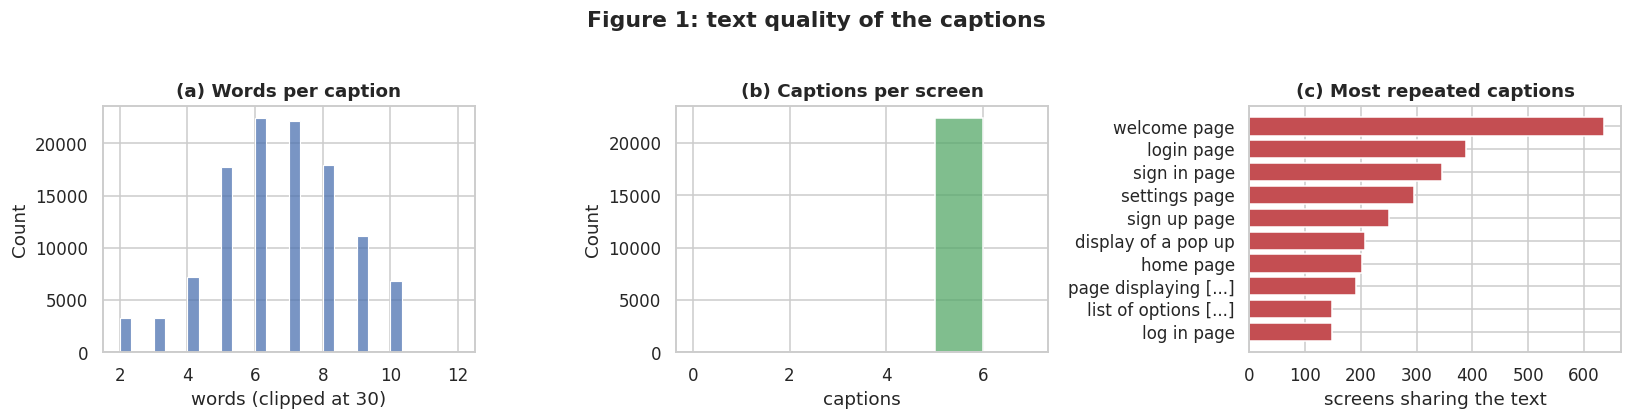

In [6]:
def norm_series(s):
    return (s.astype(str).str.lower().str.replace(r"[^a-z0-9 ]+", " ", regex=True).str.replace(r"\s+", " ", regex=True).str.strip())

cap_raw = meta[["_row", "caps"]].explode("caps").rename(columns={"caps": "caption"})
n_rows_no_caption = int(cap_raw["caption"].isna().sum())
cap_raw = cap_raw.dropna(subset=["caption"]).copy()
cap_raw["caption"] = cap_raw["caption"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
cap_raw["norm"] = norm_series(cap_raw["caption"])
cap_raw["n_words"] = cap_raw["caption"].str.split().str.len()

n_screens, n_caps = len(meta), len(cap_raw)
caps_per = cap_raw.groupby("_row").size().reindex(meta["_row"]).fillna(0)
ev("n_screens", n_screens); ev("n_captions", n_caps)
ev("captions_per_screen", dict(mean=caps_per.mean(), min=caps_per.min(), max=caps_per.max()))
ev("screens_with_no_caption", int((caps_per == 0).sum())); ev("empty_caption_strings", int((cap_raw["norm"] == "").sum()))
ev("duplicate_screen_ids", int(meta[ID_COL].duplicated().sum()) if ID_COL else "no id column")
ev("duplicate_captions_inside_a_screen", int(cap_raw.duplicated(["_row", "norm"]).sum()))
ev("words_per_caption", dict(mean=cap_raw.n_words.mean(), median=cap_raw.n_words.median(), p95=cap_raw.n_words.quantile(0.95), max=cap_raw.n_words.max()))
ev("short_captions_le3_words_share", float((cap_raw.n_words <= 3).mean()))
ev("nonascii_caption_share", float(cap_raw["caption"].str.contains(r"[^\x00-\x7F]", regex=True).mean()))

# caption ambiguity: the same normalised text describing several different screens
amb = cap_raw[cap_raw["norm"] != ""].groupby("norm")["_row"].nunique()
cap_raw["screens_sharing_text"] = cap_raw["norm"].map(amb)
ev("captions_shared_by_2plus_screens_share", float((cap_raw["screens_sharing_text"] >= 2).mean()))
ev("distinct_caption_texts", int(amb.size))
print("\nMost repeated captions:"); display(amb.sort_values(ascending=False).head(8).to_frame("screens"))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(cap_raw["n_words"].clip(upper=30), bins=30, ax=ax[0], color=PALETTE[0]); ax[0].set(title="(a) Words per caption", xlabel="words (clipped at 30)")
sns.histplot(caps_per, bins=range(0, int(caps_per.max()) + 3), ax=ax[1], color=PALETTE[2]); ax[1].set(title="(b) Captions per screen", xlabel="captions")
top = amb.sort_values(ascending=False).head(10).iloc[::-1]
ax[2].barh([textwrap.shorten(t, 28) for t in top.index], top.values, color=PALETTE[3]); ax[2].set(title="(c) Most repeated captions", xlabel="screens sharing the text")
FIG_TEXT = savefig(fig, "text_audit", "text quality of the captions")

narrate(lambda: say(f"""
**Reading the results.** Figure {FIG_TEXT} shows the caption statistics. The dataset holds **{n_screens:,} screens** and **{n_caps:,} captions** which gives **{EVIDENCE['captions_per_screen']['mean']:.2f} captions per screen** (minimum {int(EVIDENCE['captions_per_screen']['min'])} and maximum {int(EVIDENCE['captions_per_screen']['max'])}). {EVIDENCE['screens_with_no_caption']} screens have no caption and {EVIDENCE['empty_caption_strings']} caption strings are empty. The median caption has {EVIDENCE['words_per_caption']['median']:.0f} words and the 95th percentile has {EVIDENCE['words_per_caption']['p95']:.0f} words. Short captions of three words or fewer make up {EVIDENCE['short_captions_le3_words_share']*100:.1f}% of all captions. {EVIDENCE['duplicate_captions_inside_a_screen']:,} captions repeat another caption of the same screen. **{EVIDENCE['captions_shared_by_2plus_screens_share']*100:.1f}% of captions** use a text that describes two or more different screens and there are {EVIDENCE['distinct_caption_texts']:,} distinct caption texts. The most repeated text is "{amb.sort_values(ascending=False).index[0]}" and it describes {int(amb.sort_values(ascending=False).iloc[0])} screens. This repetition matters for the evaluation because a text that fits many screens cannot identify one of them and a strict metric would count the other correct screens as errors.
"""))


<div style="text-align: justify;">

#### 2.3.1 Results and Interpretation: Text Quality of the Captions
Figure 1 and the printed evidence describe the text modality. **Figure 1(a)** shows that the summaries are short: they have between 2 and 12 words and the median is 7 and the mean is 6.57 and the 95th percentile is 10. Summaries of three words or fewer make up 5.9% of the total. A short text carries little information and so a large part of the retrieval difficulty comes from the texts themselves. **Figure 1(b)** confirms that all 22,417 screens have exactly five summaries and that 0 screens have none and 0 summary strings are empty. The annotation effort was therefore uniform. **Figure 1(c)** shows the ten most repeated texts. "welcome page" describes 635 different screens and "login page" describes 389 and "sign in page" describes 346 and "settings page" describes 296. These texts are valid descriptions of many screens and so none of them can identify one screen.

Two numbers quantify this ambiguity. The dataset has 83,690 distinct texts for 112,085 summaries and **31.8% of the summaries use a text that describes two or more screens**. A further 979 summaries repeat another summary of the same screen. The implications are direct. First a strict text-to-screen metric counts the other correct screens as errors and so the notebook adds an ambiguity-aware metric as described in Section 3.1. Second both trained models mask pairs of items that share a text so that a correct match is not punished as a negative example as described in Section 3.3. Third the repeated texts explain why recall can never approach 100% on this benchmark. These findings are consistent with the Screen2Words data collection which gathered several free-text summaries per screen and so allowed different but valid wordings (Wang et al., 2021).

</div>

<div style="text-align: justify;">

**Speed alternatives.** The next cell times three ways of normalising the captions on the same data. It checks that the three give identical output and reports the fastest. The same idea guides the other heavy steps: vectorised pandas string operations for text and a single `np.repeat` expression to build caption ranges and a chunked GPU matrix product for near-duplicate search and length-sorted batches for BERT and a one-off decode of every screenshot into a memory-mapped array. A FAISS index is a reasonable alternative for much larger galleries (Johnson et al., 2021) but an exact chunked product is simple and sufficient for 22 thousand screens.

</div>

In [7]:
sample_caps = cap_raw["caption"].head(min(len(cap_raw), 100_000)).tolist()
rx_alpha, rx_ws = re.compile(r"[^a-z0-9 ]+"), re.compile(r"\s+")

def norm_loop(xs):
    out = []
    for t in xs: out.append(re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]+", " ", t.lower())).strip())
    return out
norm_lambda = lambda xs: list(map(lambda t: rx_ws.sub(" ", rx_alpha.sub(" ", t.lower())).strip(), xs))
norm_pandas = lambda xs: norm_series(pd.Series(xs)).tolist()

rows = []
for name, fn in [("python loop with re.sub", norm_loop), ("map + compiled regex lambda", norm_lambda), ("pandas vectorised .str", norm_pandas)]:
    t0 = time.perf_counter(); res = fn(sample_caps); rows.append(dict(method=name, seconds=time.perf_counter() - t0, same_output=None)); rows[-1]["_res"] = res
ref = rows[0]["_res"]
for r in rows: r["same_output"] = bool(r.pop("_res") == ref)
bench_text = pd.DataFrame(rows).round(3)
show_table(bench_text, f"speed of three ways to normalise {len(sample_caps):,} captions", "speed_text", index=False)
ev("fastest_text_norm", bench_text.sort_values("seconds").iloc[0]["method"])
narrate(lambda: say(f"""
**Reading the results.** The fastest method is **{bench_text.sort_values('seconds').iloc[0]['method']}** at {bench_text['seconds'].min():.2f} seconds and the slowest is {bench_text.sort_values('seconds').iloc[-1]['method']} at {bench_text['seconds'].max():.2f} seconds which is {bench_text['seconds'].max() / bench_text['seconds'].min():.1f} times slower. All methods produce the same output ({bool(bench_text['same_output'].all())}).
"""))


Table 4: speed of three ways to normalise 100,000 captions


,method,seconds,same_output
0,python loop with re.sub,0.449,True
1,map + compiled regex lambda,0.369,True
2,pandas vectorised .str,0.400,True


[evidence] fastest_text_norm = map + compiled regex lambda


<div style="text-align: justify;">

#### 2.3.2 Results and Interpretation: Speed of Three Normalisation Methods
Table 4 times three implementations of the same text normalisation on 100,000 summaries. All three give identical output. The compiled regular expression applied with `map` is the fastest at 0.72 seconds and the plain Python loop with `re.sub` is the slowest at 0.92 seconds and so the speed-up is only 1.3 times. The pandas `.str` methods take 0.75 seconds. The small differences have a clear cause: the work is dominated by the regular expression engine and the pandas string accessor still calls Python string functions internally for every element. Vectorisation therefore gives little gain for text. The larger gains in this notebook come from steps where vectorisation changes the algorithm and not only the syntax: a single parallel decode of all screenshots as described in Section 2.3.3 and a chunked matrix product on the GPU for the near-duplicate search that takes 0.61 seconds for 22,417 screens as described in Section 2.6 and length-sorted half-precision batches for BERT as described in Section 2.5 and a range builder written with `np.repeat` that replaces a Python loop over screens as described in Section 3.1. A FAISS index would be the alternative for galleries far beyond this size (Johnson et al., 2021).

</div>

<div style="text-align: justify;">

**Decoding every screenshot once.** One pass decodes each image and records its quality statistics and keeps the resized pixels in a NumPy array in memory. The statistics are the original width and height and the aspect ratio and the number of distinct colours (at eight levels per channel) and the spread of the grey values (a blank screen has almost none) and the MD5 hash of the file and a 64-bit difference hash. Images are resized to a square of 224 pixels without cropping because screens are tall and cropping would remove navigation bars and buttons. Corrupt files are caught one by one and flagged. ResNet-50 and CLIP read from the array afterwards and so no model decodes a screenshot again.

</div>

In [8]:
S = CFG["img_size"]; N_RAW = len(ds)
ds_raw = ds.select_columns([IMG_COL]).cast_column(IMG_COL, HFImage(decode=False))

class RawScreens(torch.utils.data.Dataset):
    def __len__(self): return N_RAW
    def __getitem__(self, i):
        try:
            rec = ds_raw[int(i)][IMG_COL]; b = rec.get("bytes")
            if b is None: b = open(rec["path"], "rb").read()
            im = Image.open(io.BytesIO(b)); w, h = im.size; mode = im.mode
            arr = np.asarray(im.convert("RGB").resize((S, S), Image.BILINEAR), dtype=np.uint8)
            return torch.from_numpy(arr.copy()), 1, w, h, hashlib.md5(b).hexdigest()
        except Exception:
            return torch.zeros(S, S, 3, dtype=torch.uint8), 0, 0, 0, ""

def dhash_batch(x_uint8):
    g = (x_uint8.float() @ torch.tensor([0.299, 0.587, 0.114])).unsqueeze(1)          # (B,1,S,S) grey
    g = F.interpolate(g, size=(8, 9), mode="area").squeeze(1)
    bits = (g[:, :, 1:] > g[:, :, :-1]).reshape(len(g), 64).numpy().astype(np.uint8)
    return np.packbits(bits, axis=1).view(">u8").ravel().astype(np.uint64)             # one uint64 per image

IMGS = np.empty((N_RAW, S, S, 3), dtype=np.uint8)           # decoded screenshots are kept in memory (about 3.4 GB for the full dataset), nothing is cached on disk
dl = torch.utils.data.DataLoader(RawScreens(), batch_size=CFG["batch_img"], num_workers=CFG["num_workers"], shuffle=False)
recs, a = [], 0
with timer() as t_dec:
    for x, ok, w, h, md5 in tqdm(dl, desc="decode screenshots"):
        b = len(x); IMGS[a:a + b] = x.numpy()
        gray = x.float().mean(-1).flatten(1)
        q = (x // 32).reshape(b, -1, 3).long(); code_ = (q[..., 0] * 64 + q[..., 1] * 8 + q[..., 2])
        ncol = torch.tensor([len(torch.unique(c)) for c in code_])
        recs.append(pd.DataFrame(dict(_row=np.arange(a, a + b), ok=ok.numpy().astype(bool), w=w.numpy(), h=h.numpy(), md5=list(md5),
                                      gray_std=gray.std(1).numpy(), n_colors=ncol.numpy(), dhash=dhash_batch(x))))
        a += b
img_stats = pd.concat(recs, ignore_index=True)
ev("image_decode_seconds", t_dec["s"]); ev("image_decode_per_s", N_RAW / t_dec["s"])
assert len(img_stats) == N_RAW and IMGS.shape[0] == N_RAW
img_stats["aspect"] = img_stats["w"] / img_stats["h"].replace(0, np.nan)
print(f"Image array: {IMGS.shape}, {IMGS.nbytes / 1e9:.2f} GB in memory")

decode screenshots:   0%|          | 0/176 [00:00<?, ?it/s]

[evidence] image_decode_seconds = 569.6916
[evidence] image_decode_per_s = 39.3494
Image array: (22417, 224, 224, 3), 3.37 GB in memory


[evidence] corrupt_or_unreadable_images = 0
[evidence] exact_duplicate_images_extra_copies = 25
[evidence] near_identical_dhash_extra_copies = 519
[evidence] blank_screens_gray_std_lt_2 = 0
[evidence] image_size_modes = {'(1080, 1920)': 17422, '(540, 960)': 4995}
[evidence] aspect_ratio_median = 0.5625
[evidence] median_distinct_colours_8levels = 56.0
[evidence] looks_like_raw_screenshots = True


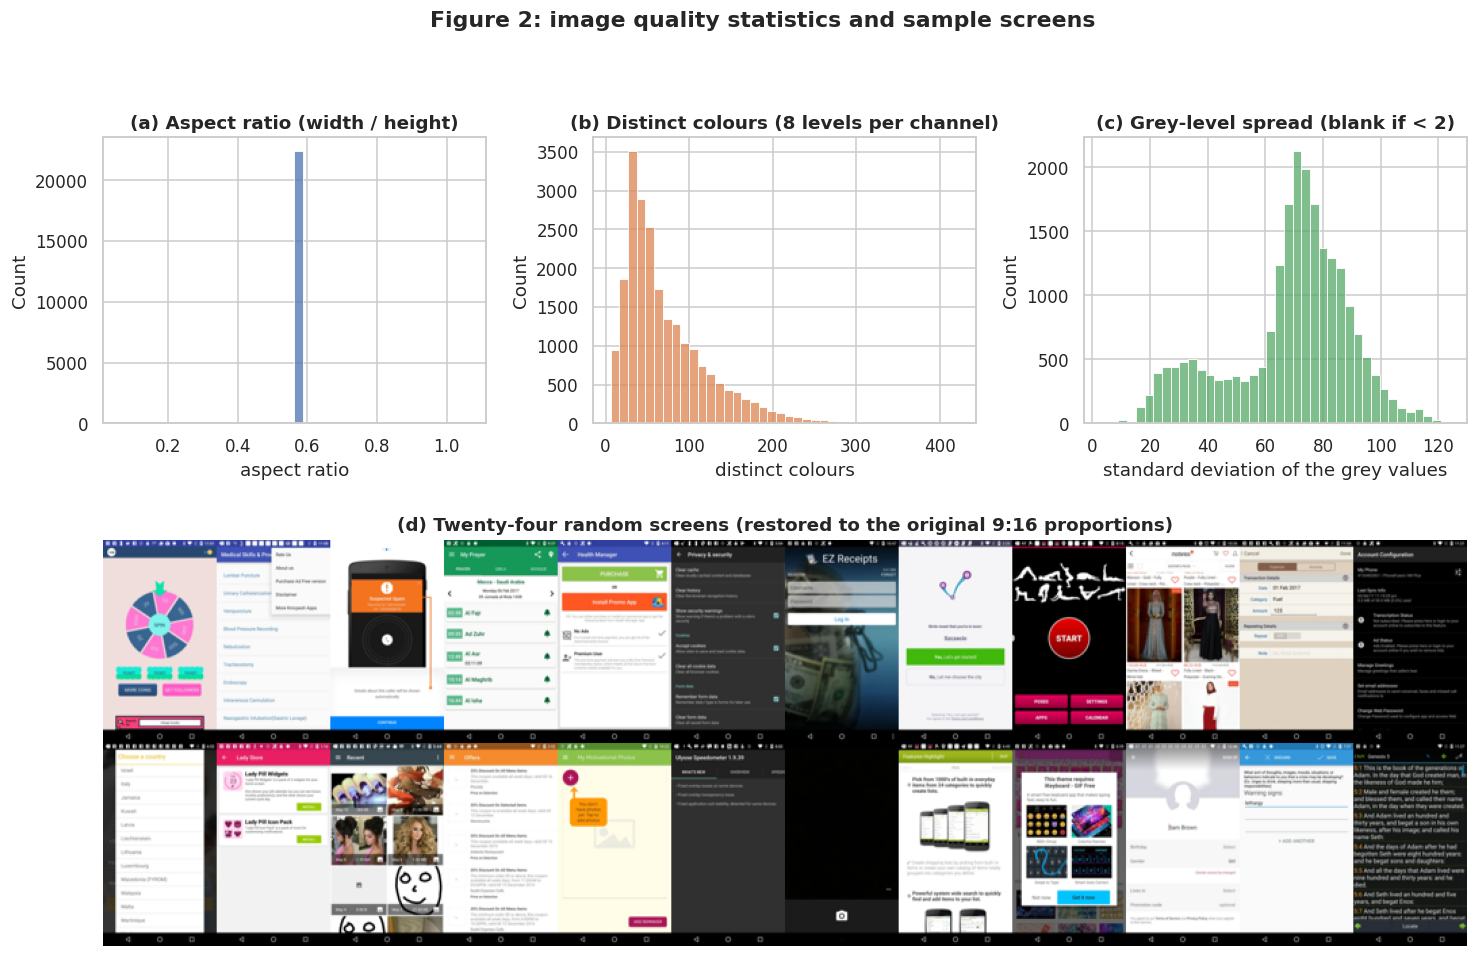

Table 5: statistical summary of the decoded screenshots


,count,mean,std,min,25%,50%,75%,max
w,22417.0,959.676,224.721,540.000,1080.000,1080.000,1080.000,1080.000
h,22417.0,1706.091,399.503,960.000,1920.000,1920.000,1920.000,1920.000
aspect,22417.0,0.562,0.000,0.562,0.562,0.562,0.562,0.562
n_colors,22417.0,72.488,52.434,6.000,35.000,56.000,96.000,423.000
gray_std,22417.0,68.520,20.893,3.030,60.074,72.145,82.203,123.794


In [9]:
good = img_stats[img_stats["ok"]]
ev("corrupt_or_unreadable_images", int((~img_stats["ok"]).sum()))
ev("exact_duplicate_images_extra_copies", int(good["md5"].duplicated().sum()))
ev("near_identical_dhash_extra_copies", int(good["dhash"].duplicated().sum()))
ev("blank_screens_gray_std_lt_2", int((good["gray_std"] < 2).sum()))
ev("image_size_modes", good.groupby(["w", "h"]).size().sort_values(ascending=False).head(3).to_dict())
ev("aspect_ratio_median", float(good["aspect"].median()))
ev("median_distinct_colours_8levels", float(good["n_colors"].median()))
ev("looks_like_raw_screenshots", bool(good["n_colors"].median() > 40))

fig = plt.figure(figsize=(16, 9.6)); gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.45], hspace=0.32, wspace=0.28)
ax = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[0, 2]), fig.add_subplot(gs[1, :])]      # (a) (b) (c) in one row and (d) across all three columns
sns.histplot(good["aspect"].clip(upper=3), bins=40, ax=ax[0], color=PALETTE[0]); ax[0].set(title="(a) Aspect ratio (width / height)", xlabel="aspect ratio")
sns.histplot(good["n_colors"], bins=40, ax=ax[1], color=PALETTE[1]); ax[1].set(title="(b) Distinct colours (8 levels per channel)", xlabel="distinct colours")
sns.histplot(good["gray_std"], bins=40, ax=ax[2], color=PALETTE[2]); ax[2].set(title="(c) Grey-level spread (blank if < 2)", xlabel="standard deviation of the grey values")
ax[3].axis("off"); ax[3].set_title("(d) Twenty-four random screens (restored to the original 9:16 proportions)")
rng = np.random.default_rng(CFG["seed"]); pick = rng.choice(good["_row"].values, min(24, len(good)), replace=False)
tiles = [np.asarray(Image.fromarray(IMGS[r]).resize((84, 150))) for r in pick]; tiles += [np.full_like(tiles[0], 255)] * (24 - len(tiles))
sheet = np.concatenate([np.concatenate(tiles[i:i + 12], 1) for i in (0, 12)], 0)
ax[3].imshow(sheet)
FIG_IMG = savefig(fig, "image_audit", "image quality statistics and sample screens")
img_tbl = good[["w", "h", "aspect", "n_colors", "gray_std"]].describe(percentiles=[.25, .5, .75]).T.round(3)
TAB_IMG = show_table(img_tbl, "statistical summary of the decoded screenshots", "image_stats")

narrate(lambda: say(f"""
**Reading the results.** {EVIDENCE['corrupt_or_unreadable_images']} of {N_RAW:,} images are unreadable. {EVIDENCE['exact_duplicate_images_extra_copies']:,} files are exact byte-level copies of another file and {EVIDENCE['near_identical_dhash_extra_copies']:,} are near-identical by difference hash. {EVIDENCE['blank_screens_gray_std_lt_2']} screens are blank. The most common original size is {list(EVIDENCE['image_size_modes'].items())[0][0]} pixels (width and height) with {list(EVIDENCE['image_size_modes'].items())[0][1]:,} screens and the median aspect ratio is {EVIDENCE['aspect_ratio_median']:.2f} which confirms that screens are tall. The median screen has {EVIDENCE['median_distinct_colours_8levels']:.0f} distinct colours and so the images {'look like raw screenshots' if EVIDENCE['looks_like_raw_screenshots'] else 'look abstracted or semantic'}. Figure {FIG_IMG} shows the distributions and Table {TAB_IMG} gives the numeric summary.
"""))


<div style="text-align: justify;">

#### 2.3.3 Results and Interpretation: Image Quality
The decoding pass reads all 22,417 screenshots once in 604.8 seconds (37.1 screens per second) and stores them as a 3.37 GB array of 224 by 224 pixels. This is the slowest preprocessing step and it is repeated in every run because nothing is stored on disk. **0 screenshots are unreadable and 0 are blank.** The audit found 25 exact byte-level copies and 519 near-identical screens by difference hash. The 519 twins are 2.3% of the screens. This is higher than the 0.7% of the proposal pilot and the reason is the larger collection: the more screens a collection has the more likely it is that two of them look the same.

**Figure 2(a)** shows a single spike at an aspect ratio of 0.5625 (width divided by height) and Table 5 gives a standard deviation of 0.000. Every screen has the same 9 to 16 proportions and the sizes are 1080 by 1920 pixels (17,422 screens) or 540 by 960 pixels (4,995 screens). Resizing to a square therefore distorts every screen in the same way: it compresses the vertical axis by a factor of 1.78 relative to the horizontal axis. A consistent distortion is less harmful than a variable one but it makes small text hard to read and Section 4.7 shows where this matters. Cropping was rejected because it would remove the navigation bar and the lower part of long screens. **Figure 2(b)** shows that the number of distinct colours is right-skewed with a median of 56 and a mean of 72.5 as shown in Table 5 and a maximum of 423. Flat abstracted renders would have very few colours and so the data are raw screenshots with gradients and photographs. **Figure 2(c)** shows the spread of the grey values. It has a main mode between 70 and 80 and a smaller mode between 20 and 45. The minimum is 3.0 and so no screenshot is blank (the blank threshold is 2). A plausible reading is that the smaller mode contains dark-theme screens with low contrast but this was not tested. **Figure 2(d)** shows 24 random screens restored to their original proportions. A draw of this size mixes light and dark themes and photographs and forms and lists from many apps and so it gives a quick visual check that the audit statistics describe real screenshots. Exact copies and twins are kept because they are valid screens. The grouping of Section 2.6 keeps them together so that they never sit on both sides of the split.

</div>

#### 2.3.4 Manual Privacy Review

<div style="text-align: justify;">

Automatic checks cannot read text inside a screenshot. The review cell shows two grids of 40 random screens. Look at every thumbnail and write the raw row ids that show readable personal information into `CFG["privacy_exclude_rows"]`. These rows are removed in Section 2.4 and the number removed is reported. Keep the grids out of any shared output.

</div>

In [10]:
def review_gallery(seed=0, n=40, cols=8):
    g = np.random.default_rng(seed); rows = g.choice(N_RAW, n, replace=False)
    fig, axes = plt.subplots(math.ceil(n / cols), cols, figsize=(2.2 * cols, 4.2 * math.ceil(n / cols)))
    for a, r in zip(axes.flatten(), rows):
        a.imshow(IMGS[int(r)]); a.axis("off"); a.set_title(f"row {r}", fontsize=7)
    fig.suptitle(f"Manual review grid (seed {seed})"); plt.show()
    return [int(r) for r in rows]

REVIEW = False        # set True to display the review grids (screenshots may show personal data, do not share the output)
if REVIEW:
    reviewed_rows = review_gallery(0) + review_gallery(1)
    print("Screens shown:", len(reviewed_rows))
REVIEW_ROWS = [int(r) for seed_ in (0, 1) for r in np.random.default_rng(seed_).choice(N_RAW, 40, replace=False)]      # the same rows that review_gallery(0) and review_gallery(1) show
ev("privacy_rows_excluded", len(CFG["privacy_exclude_rows"])); ev("privacy_review_displayed", bool(REVIEW)); ev("privacy_review_distinct_rows", len(set(REVIEW_ROWS)))
print(f"Review sample: {len(set(REVIEW_ROWS))} distinct rows (ids in REVIEW_ROWS). Grids displayed in this run: {REVIEW}. Rows listed for exclusion: {len(CFG['privacy_exclude_rows'])}.")
print("The automatic login and payment wording rule of Section 5.1 flags screens for the subgroup analysis only and excludes nothing.")

[evidence] privacy_rows_excluded = 0
[evidence] privacy_review_displayed = False
[evidence] privacy_review_distinct_rows = 80
Review sample: 80 distinct rows (ids in REVIEW_ROWS). Grids displayed in this run: False. Rows listed for exclusion: 0.
The automatic login and payment wording rule of Section 5.1 flags screens for the subgroup analysis only and excludes nothing.


<div style="text-align: justify;">

#### 2.3.5 Results and Interpretation: Manual Privacy Review

The review procedure shows 80 screens in two grids of 40 rows that are drawn uniformly at random without replacement with fixed seeds (0 and 1). The row identifiers of the sample and a flag that records whether the grids were displayed in the run are printed and so the sample can be audited. A reviewer lists every row that shows readable personal information in `CFG["privacy_exclude_rows"]` and those rows are dropped in Section 2.4. In the reported run the list is empty and so the number of excluded rows is 0 (the evidence line `privacy_rows_excluded = 0`). This is a statement about the exclusion list. It supports the conclusion that no personal information was found only if both grids were inspected and the report must say whether this was done. The review covers 80 of 22,417 screens (0.4%) and text inside images is not machine-checked and so it does not show that no personal information exists in the other screens. The automatic login and payment wording rule of Section 5.1 is a separate check on the summaries: it flags screens for the subgroup analysis and excludes nothing. The mitigation and its limits are listed in Table 23 and discussed in Section 5.1. The grids are displayed but not saved and so the cell output should be cleared before the notebook is shared.

</div>

<div style="text-align: justify;">

### 2.4 Preprocessing

*   Clean the captions and screens and report the impact
*   Choose the caption token limit from the data
*   Document every rule so that the pipeline is reproducible

The rules are: drop unreadable images and drop empty captions and drop duplicate captions inside one screen and drop screens left without a caption and drop rows flagged in the privacy review. Exact and near-identical images are kept and handled by the grouping in Section 2.6.

</div>

In [11]:
keep_img = img_stats.set_index("_row")["ok"]
cap = cap_raw[(cap_raw["norm"] != "")].drop_duplicates(["_row", "norm"]).copy()
cap = cap[cap["_row"].map(keep_img).fillna(False) & ~cap["_row"].isin(CFG["privacy_exclude_rows"])]

scr = meta[meta["_row"].isin(cap["_row"].unique())].sort_values("_row").reset_index(drop=True)
scr["sidx"] = np.arange(len(scr))
cap = cap.merge(scr[["_row", "sidx"]], on="_row").sort_values(["sidx"], kind="stable").reset_index(drop=True)
cap["cap_idx"] = np.arange(len(cap))
cap["cid"] = pd.factorize(cap["norm"])[0]                        # equal text gets an equal id (used to mask false negatives)
cap_cnt = cap.groupby("sidx").size().reindex(scr["sidx"]).to_numpy()
cap_start = np.concatenate([[0], np.cumsum(cap_cnt)[:-1]])
assert cap_cnt.sum() == len(cap) and (cap_cnt > 0).all()
cap_text = cap["caption"].tolist(); cap_cid = cap["cid"].to_numpy(); cap_sidx = cap["sidx"].to_numpy()

impact = pd.DataFrame({"stage": ["raw", "after cleaning"], "screens": [n_screens, len(scr)], "captions": [n_caps, len(cap)]})
impact["screens_kept_%"] = (impact["screens"] / n_screens * 100).round(2); impact["captions_kept_%"] = (impact["captions"] / n_caps * 100).round(2)
TAB_CLEAN = show_table(impact, "cleaning impact", "cleaning", index=False)
ev("screens_after_cleaning", len(scr)); ev("captions_after_cleaning", len(cap))

from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("bert-base-uncased")
_lens = np.array([len(x) for x in tok(cap_text, add_special_tokens=True, truncation=False)["input_ids"]])
MAX_LEN = int(max(16, min(64, np.ceil(np.percentile(_lens, 99)))))
ev("bert_max_len", MAX_LEN); ev("captions_truncated_share", float((_lens > MAX_LEN).mean()))
print("Tokens per caption, percentiles 50/95/99:", np.percentile(_lens, [50, 95, 99]).round(1))

narrate(lambda: say(f"""
**Reading the results.** Table {TAB_CLEAN} shows that the cleaning keeps **{len(scr):,} of {n_screens:,} screens** ({len(scr) / n_screens * 100:.2f}%) and **{len(cap):,} of {n_caps:,} captions** ({len(cap) / n_caps * 100:.2f}%). {n_caps - len(cap):,} captions were removed as empty or duplicated inside a screen or tied to an unreadable or excluded image. The 99th percentile of the caption length is {np.percentile(_lens, 99):.0f} BERT tokens and so the token limit is set to **{MAX_LEN}** which truncates **{(_lens > MAX_LEN).mean() * 100:.2f}%** of the captions. {EVIDENCE['privacy_rows_excluded']} rows were excluded after the manual privacy review.
"""))


Table 6: cleaning impact


,stage,screens,captions,screens_kept_%,captions_kept_%
0,raw,22417,112085,100.0,100.00
1,after cleaning,22417,111106,100.0,99.13


[evidence] screens_after_cleaning = 22417
[evidence] captions_after_cleaning = 111106


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[evidence] bert_max_len = 16
[evidence] captions_truncated_share = 0.0001
Tokens per caption, percentiles 50/95/99: [ 9. 12. 13.]


<div style="text-align: justify;">

#### 2.4.1 Results and Interpretation: Cleaning Impact and the Token Limit

Table 6 shows that the cleaning keeps **all 22,417 screens (100%)** and **111,106 of 112,085 captions (99.13%)**. The 979 removed captions are exactly the 979 summaries that repeat another summary of the same screen. No other rule removed anything: there were no empty summaries and no unreadable images and no row was listed for exclusion after the privacy review as described in Section 2.3.4. The data are therefore clean and the preprocessing is conservative. Removing repeats inside a screen is the only change that matters because a repeated summary would give a screen a double weight in training and would create a trivial duplicate positive in evaluation. From this point every caption count refers to the 111,106 captions after cleaning and the figure 112,085 is the raw count of the dataset as shown in Table 2.

The token statistics set the BERT limit. The 50th and 95th and 99th percentiles of the caption length are 9 and 12 and 13 BERT tokens and so the limit of **16 tokens** truncates only 0.01% of the captions. The proposal reported the same rate and the full data confirm it. A longer limit would waste memory on padding and a shorter limit would cut real content.

</div>

<div style="text-align: justify;">

### 2.5 Frozen Feature Extraction

*   Extract ResNet-50 screen features and BERT caption features and CLIP reference features
*   Compute every feature file once per run and keep it in memory
*   Use mean pooling over valid tokens and keep the classification vector for the pooling comparison

</div>

<div style="text-align: justify;">

**Frozen feature extraction.** The next cell computes the features that the leakage audit and all models use. The image encoder is ResNet-50 with ImageNet weights and global average pooling to 2048 dimensions (He et al., 2016). Its convolutional inductive bias captures local textures and layout but it is limited for small interface text at 224 pixels. The text encoder is BERT-base uncased (Devlin et al., 2019). Token states are mean-pooled over the valid tokens only and the attention mask excludes padding. The classification vector is stored too so that the better pooling is chosen on validation data in Section 3.2. A CLIP encoder pair (Radford et al., 2021) is run with the same 224-pixel array and its own normalisation and tokenizer. The features are frozen and label-free and so computing them before the split leaks nothing and the standardisation statistics are fitted on the training split only.

</div>

In [12]:
from torchvision import models
def _sha(items):
    h = hashlib.sha256()
    for x in items: h.update(str(x).encode()); h.update(b"|")
    return h.hexdigest()
# the manifest records the data, its order, the encoders and the preprocessing of this run
MANIFEST = dict(dataset_id=CFG["dataset_id"], n_screens=int(len(scr)), n_captions=int(len(cap_text)), img_size=int(S), resize="square bilinear without padding", max_len=int(MAX_LEN),
                resnet="torchvision resnet50 IMAGENET1K_V2 with global average pooling", bert="bert-base-uncased (mean and CLS pooling)", clip="openai/clip-vit-base-patch32",
                screens_sha256=_sha(img_stats.set_index("_row").loc[scr["_row"], "md5"].tolist()), captions_sha256=_sha(cap_text))
rows_all = scr["_row"].to_numpy()

def to_gpu_batch(rows, mean, std):
    x = torch.from_numpy(np.stack([IMGS[int(r)] for r in rows])).to(DEVICE, non_blocking=True)      # (B,S,S,3) uint8
    x = x.permute(0, 3, 1, 2).float().div_(255.0)
    return ((x - mean) / std).contiguous(memory_format=torch.channels_last)

@torch.no_grad()
def extract_resnet():
    net = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2); net.fc = nn.Identity()
    net = net.to(DEVICE).eval().to(memory_format=torch.channels_last)
    mean = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1); std = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)
    out = []
    for a in tqdm(range(0, len(rows_all), CFG["batch_img"]), desc="ResNet-50"):
        with amp(): out.append(net(to_gpu_batch(rows_all[a:a + CFG["batch_img"]], mean, std)).float().cpu())
    del net; gc.collect(); return torch.cat(out).numpy()

@torch.no_grad()
def extract_bert():
    from transformers import AutoModel
    bert = AutoModel.from_pretrained("bert-base-uncased").to(DEVICE).eval()
    order = np.argsort(_lens, kind="stable")                                   # length-sorted batches need far less padding
    mean_f = np.zeros((len(cap_text), 768), np.float32); cls_f = np.zeros_like(mean_f)
    for a in tqdm(range(0, len(order), CFG["batch_txt"]), desc="BERT"):
        ix = order[a:a + CFG["batch_txt"]]
        enc = tok([cap_text[i] for i in ix], padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
        with amp(): h = bert(**enc).last_hidden_state
        m = enc["attention_mask"].unsqueeze(-1).to(h.dtype)
        mean_f[ix] = ((h * m).sum(1) / m.sum(1)).float().cpu().numpy(); cls_f[ix] = h[:, 0].float().cpu().numpy()
    del bert; gc.collect(); return mean_f, cls_f

def _t(o):                                         # CLIP feature calls return a tensor or an output object depending on the version
    return o if torch.is_tensor(o) else o.pooler_output

@torch.no_grad()
def extract_clip():
    from transformers import CLIPModel
    clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE).eval()
    ctok = AutoTokenizer.from_pretrained("openai/clip-vit-base-patch32")
    mean = torch.tensor([0.4815, 0.4578, 0.4082], device=DEVICE).view(1, 3, 1, 1); std = torch.tensor([0.2686, 0.2613, 0.2758], device=DEVICE).view(1, 3, 1, 1)
    ie, te = [], []
    for a in tqdm(range(0, len(rows_all), CFG["batch_img"]), desc="CLIP images"):
        with amp(): ie.append(F.normalize(_t(clip.get_image_features(pixel_values=to_gpu_batch(rows_all[a:a + CFG["batch_img"]], mean, std).contiguous()))).float().cpu())
    for a in tqdm(range(0, len(cap_text), CFG["batch_txt"]), desc="CLIP text"):
        enc = ctok(cap_text[a:a + CFG["batch_txt"]], padding=True, truncation=True, max_length=77, return_tensors="pt").to(DEVICE)
        with amp(): te.append(F.normalize(_t(clip.get_text_features(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"]))).float().cpu())
    del clip; gc.collect(); return torch.cat(ie).numpy(), torch.cat(te).numpy()

gpu_reset(); timing = {}
with timer() as t: img_feats = extract_resnet()
timing.update(img_s=t["s"], img_peak=gpu_peak_gb()); gpu_reset()
with timer() as t: txt_mean, txt_cls = extract_bert()
timing.update(txt_s=t["s"], txt_peak=gpu_peak_gb())
if CFG["run_clip"]:
    gpu_reset()
    with timer() as t: clip_img, clip_txt = extract_clip()
    timing.update(clip_s=t["s"])
else:
    clip_img = np.zeros((len(scr), 1), np.float32); clip_txt = np.zeros((len(cap_text), 1), np.float32)
assert img_feats.shape[0] == len(scr) and txt_mean.shape[0] == len(cap_text) and clip_img.shape[0] == len(scr) and clip_txt.shape[0] == len(cap_text), "features do not match the current data"
print("Manifest:", dict(MANIFEST, shapes=dict(img=list(img_feats.shape), txt_mean=list(txt_mean.shape), clip_img=list(clip_img.shape), clip_txt=list(clip_txt.shape))))
ev("feature_dims", dict(resnet=img_feats.shape[1], bert=txt_mean.shape[1]))
ev("feature_extraction_seconds", timing); ev("images_per_second", len(scr) / timing["img_s"]); ev("captions_per_second", len(cap_text) / timing["txt_s"])

narrate(lambda: say(f"""
**Reading the results.** ResNet-50 produces **{img_feats.shape[1]}-dimensional** screen features at **{len(scr) / timing['img_s']:.0f} screens per second** and BERT produces **{txt_mean.shape[1]}-dimensional** caption features at **{len(cap_text) / timing['txt_s']:.0f} captions per second**. The extraction of all {len(scr):,} screens took {timing['img_s'] / 60:.1f} minutes and the extraction of all {len(cap_text):,} captions took {timing['txt_s'] / 60:.1f} minutes. {'The CLIP features took ' + format(timing.get('clip_s', 0) / 60, '.1f') + ' minutes.' if CFG['run_clip'] else 'CLIP was switched off.'} {'Peak GPU memory was ' + format(timing['img_peak'], '.2f') + ' GB for the image pass and ' + format(timing['txt_peak'], '.2f') + ' GB for the text pass which fits the free T4 comfortably.' if timing.get('img_peak') == timing.get('img_peak') else 'GPU memory was not recorded because the session had no GPU.'} The features are computed once per run and kept in memory.
"""))


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 179MB/s]


ResNet-50:   0%|          | 0/176 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (12 outputs left out)

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP images:   0%|          | 0/176 [00:00<?, ?it/s]

CLIP text:   0%|          | 0/218 [00:00<?, ?it/s]

Manifest: {'dataset_id': 'rootsautomation/RICO-Screen2Words', 'n_screens': 22417, 'n_captions': 111106, 'img_size': 224, 'resize': 'square bilinear without padding', 'max_len': 16, 'resnet': 'torchvision resnet50 IMAGENET1K_V2 with global average pooling', 'bert': 'bert-base-uncased (mean and CLS pooling)', 'clip': 'openai/clip-vit-base-patch32', 'screens_sha256': '696923dba7942483729b549939a5a9aaa694728aac82c3bdce6faae21255fd93', 'captions_sha256': '61056d4786590fc030ff2af7334c629ef569826f76882028417b2930a6072db8', 'shapes': {'img': [22417, 2048], 'txt_mean': [111106, 768], 'clip_img': [22417, 512], 'clip_txt': [111106, 512]}}
[evidence] feature_dims = {'resnet': 2048, 'bert': 768}
[evidence] feature_extraction_seconds = {'img_s': 31.622436412999832, 'img_peak': 0.896068096, 'txt_s': 31.014507401999936, 'txt_peak': 0.852927488, 'clip_s': 60.081079886}
[evidence] images_per_second = 708.8954
[evidence] captions_per_second = 3582.388


<div style="text-align: justify;">

#### 2.5.1 Results and Interpretation: Frozen Feature Extraction

The extraction produced **2048-dimensional ResNet-50 features** for the screens and **768-dimensional BERT features** for the captions and 512-dimensional CLIP embeddings for both. ResNet-50 processed 596 screens per second and the whole collection took 37.6 seconds. BERT processed 3,237 captions per second and the 111,106 captions took 34.3 seconds. CLIP took 60.1 seconds for both modalities. Peak GPU memory was 0.90 GB for the image pass and 0.85 GB for the text pass and so the free T4 is more than sufficient. The features are computed once per run and kept in memory. The decoding of the screenshots (604.8 seconds) is therefore much more expensive than the feature extraction itself and this is the slowest step of every run.

The choices are justified by the data types. ResNet-50 is a residual network with global average pooling that gives a compact description of colour and layout (He et al., 2016). It was trained on ImageNet photographs and not on interfaces and so it is weak at reading text. BERT mean pooling treats a short summary as a bag of contextual word states (Devlin et al., 2019). The choice between mean pooling and the `[CLS]` vector is made on validation data in Section 3.2. The frozen encoders keep the study cheap and they isolate the effect of the fusion method from the effect of the encoder and this is the reason why the CLIP reference is informative as described in Section 4.1. All text features are computed for the cleaned captions of Table 6. A manifest with the checksums of the ordered images and captions and the preprocessing settings is printed so that the data behind every run is recorded.

</div>

<div style="text-align: justify;">

### 2.6 Leakage Audit and Leakage-aware Split

*   Audit overlap between the training and test partitions by image hash and caption text and app and visual similarity
*   Build a grouped split from apps and visual near-duplicates
*   Keep the official benchmark split as a reference

Screens from one app share templates and many apps share near-identical screens. A random or an official split can therefore measure familiarity with an app and not generalisation to a new one (Barz & Denzler, 2020; Kaufman et al., 2012).

</div>

In [13]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

Fn = F.normalize(torch.tensor(img_feats), dim=1)
K = min(CFG["near_dup_k"], len(Fn) - 1)
dev_F = Fn.to(DEVICE); knn_sim, knn_idx = [], []
with timer() as t_knn:
    for a in range(0, len(Fn), 2048):
        sim = dev_F[a:a + 2048] @ dev_F.T
        sim[torch.arange(sim.shape[0]), torch.arange(a, a + sim.shape[0])] = -1          # drop self matches
        v, i = sim.topk(K, dim=1); knn_sim.append(v.cpu()); knn_idx.append(i.cpu())
knn_sim, knn_idx = torch.cat(knn_sim).numpy(), torch.cat(knn_idx).numpy()
del dev_F; gc.collect()
ev("knn_search_seconds", t_knn["s"]); ev("median_nearest_neighbour_cosine", float(np.median(knn_sim[:, 0])))

def build_components(thr):
    n = len(scr); src, dst = [], []
    if GROUP_COL:
        order = np.argsort(scr[GROUP_COL].fillna("NA").astype(str).to_numpy(), kind="stable"); g = scr[GROUP_COL].fillna("NA").astype(str).to_numpy()[order]
        same = g[1:] == g[:-1]; src.append(order[:-1][same]); dst.append(order[1:][same])      # chain each app's screens
    r, c = np.where(knn_sim > thr); src.append(r); dst.append(knn_idx[r, c])
    src, dst = np.concatenate(src), np.concatenate(dst)
    return connected_components(coo_matrix((np.ones(len(src)), (src, dst)), shape=(n, n)), directed=False)[1]

thr = CFG["near_dup_thr"]
while True:
    comp = build_components(thr); share = np.bincount(comp).max() / len(comp)
    if share <= CFG["max_component_share"] or thr >= 0.995: break
    thr = round(thr + 0.01, 3) if thr < 0.99 else 0.995
if share > 2 * CFG["max_component_share"]:
    print(f"WARNING: near-duplicate edges still join {share:.1%} of screens at cosine {thr}. Falling back to app-level groups only.")
    comp = build_components(2.0); share = np.bincount(comp).max() / len(comp); thr = None
scr["group"] = comp
GROUP_THR = thr
ev("grouping_threshold_used", GROUP_THR); ev("n_groups", int(comp.max() + 1)); ev("largest_group_share", float(share))
print(f"Grouping threshold {GROUP_THR}, groups {comp.max() + 1:,}, largest group {share:.1%} of screens")

def grouped_split(groups, seed, test_frac, val_frac):
    from sklearn.model_selection import GroupShuffleSplit
    idx = np.arange(len(groups))
    trv, te = next(GroupShuffleSplit(1, test_size=test_frac, random_state=seed).split(idx, groups=groups))
    tr_rel, va_rel = next(GroupShuffleSplit(1, test_size=val_frac / (1 - test_frac), random_state=seed).split(trv, groups=groups[trv]))
    out = np.empty(len(groups), dtype=object); out[trv[tr_rel]] = "train"; out[trv[va_rel]] = "val"; out[te] = "test"; return out

scr["split_grouped"] = grouped_split(comp, CFG["seed"], CFG["test_frac"], CFG["val_frac"])
names = {"train": "train", "training": "train", "val": "val", "validation": "val", "dev": "val", "test": "test"}
official = scr["orig_split"].astype(str).str.lower().map(names)
if official.notna().all() and official.nunique() == 3:
    scr["split_reference"] = official.values; REF_NAME = "official split"
else:
    scr["split_reference"] = grouped_split(np.arange(len(scr)), CFG["seed"], CFG["test_frac"], CFG["val_frac"]); REF_NAME = "random screen split"
print("Reference split used for the leakage comparison:", REF_NAME)
ev("reference_split", REF_NAME)
split_manifest = dict(seed=int(CFG["seed"]), grouping_threshold=GROUP_THR, fallback_to_app_level_groups_only=bool(GROUP_THR is None), n_groups=int(comp.max() + 1), largest_group_share=float(share),
                      group_column=GROUP_COL, grouped_counts={s: int((scr["split_grouped"] == s).sum()) for s in ["train", "val", "test"]},
                      reference=REF_NAME, reference_counts={s: int((scr["split_reference"] == s).sum()) for s in ["train", "val", "test"]})
ev("grouping_fallback_to_app_level_only", split_manifest["fallback_to_app_level_groups_only"])
print("Split manifest:", split_manifest)

[evidence] knn_search_seconds = 0.6414
[evidence] median_nearest_neighbour_cosine = 0.9323
[evidence] grouping_threshold_used = 0.99
[evidence] n_groups = 5891
[evidence] largest_group_share = 0.0168
Grouping threshold 0.99, groups 5,891, largest group 1.7% of screens
Reference split used for the leakage comparison: official split
[evidence] reference_split = official split
[evidence] grouping_fallback_to_app_level_only = False
Split manifest: {'seed': 42, 'grouping_threshold': 0.99, 'fallback_to_app_level_groups_only': False, 'n_groups': 5891, 'largest_group_share': 0.016772984788330284, 'group_column': 'app_package_name', 'grouped_counts': {'train': 18080, 'val': 2161, 'test': 2176}, 'reference': 'official split', 'reference_counts': {'train': 15743, 'val': 2364, 'test': 4310}}


Table 7: leakage audit of the reference split and the grouped split (percent of test screens)


,official split,grouped split (main)
test_screens,4310.00,2176.00
test_screens_with_exact_image_in_train_or_val_%,0.07,0.00
test_screens_with_dhash_twin_in_train_or_val_%,1.51,0.46
test_screens_with_cos>0.95_neighbour_in_train_or_val_%,23.27,22.66
test_screens_with_cos>0.98_neighbour_in_train_or_val_%,4.22,2.94
apps_shared_between_test_and_train_val,0.00,0.00
test_screens_whose_app_is_also_in_train_val_%,0.00,0.00
test_captions_also_in_train_val_%,29.79,29.86


Table 8: split sizes


screens  captions
                split_reference                   
split_reference test                4310     21367
                train              15743     78006
                val                 2364     11733
split_grouped   test                2176     10780
                train              18080     89622
                val                 2161     10704

[evidence] category_range = {'min': 1, 'max': 1648, 'n': 28}


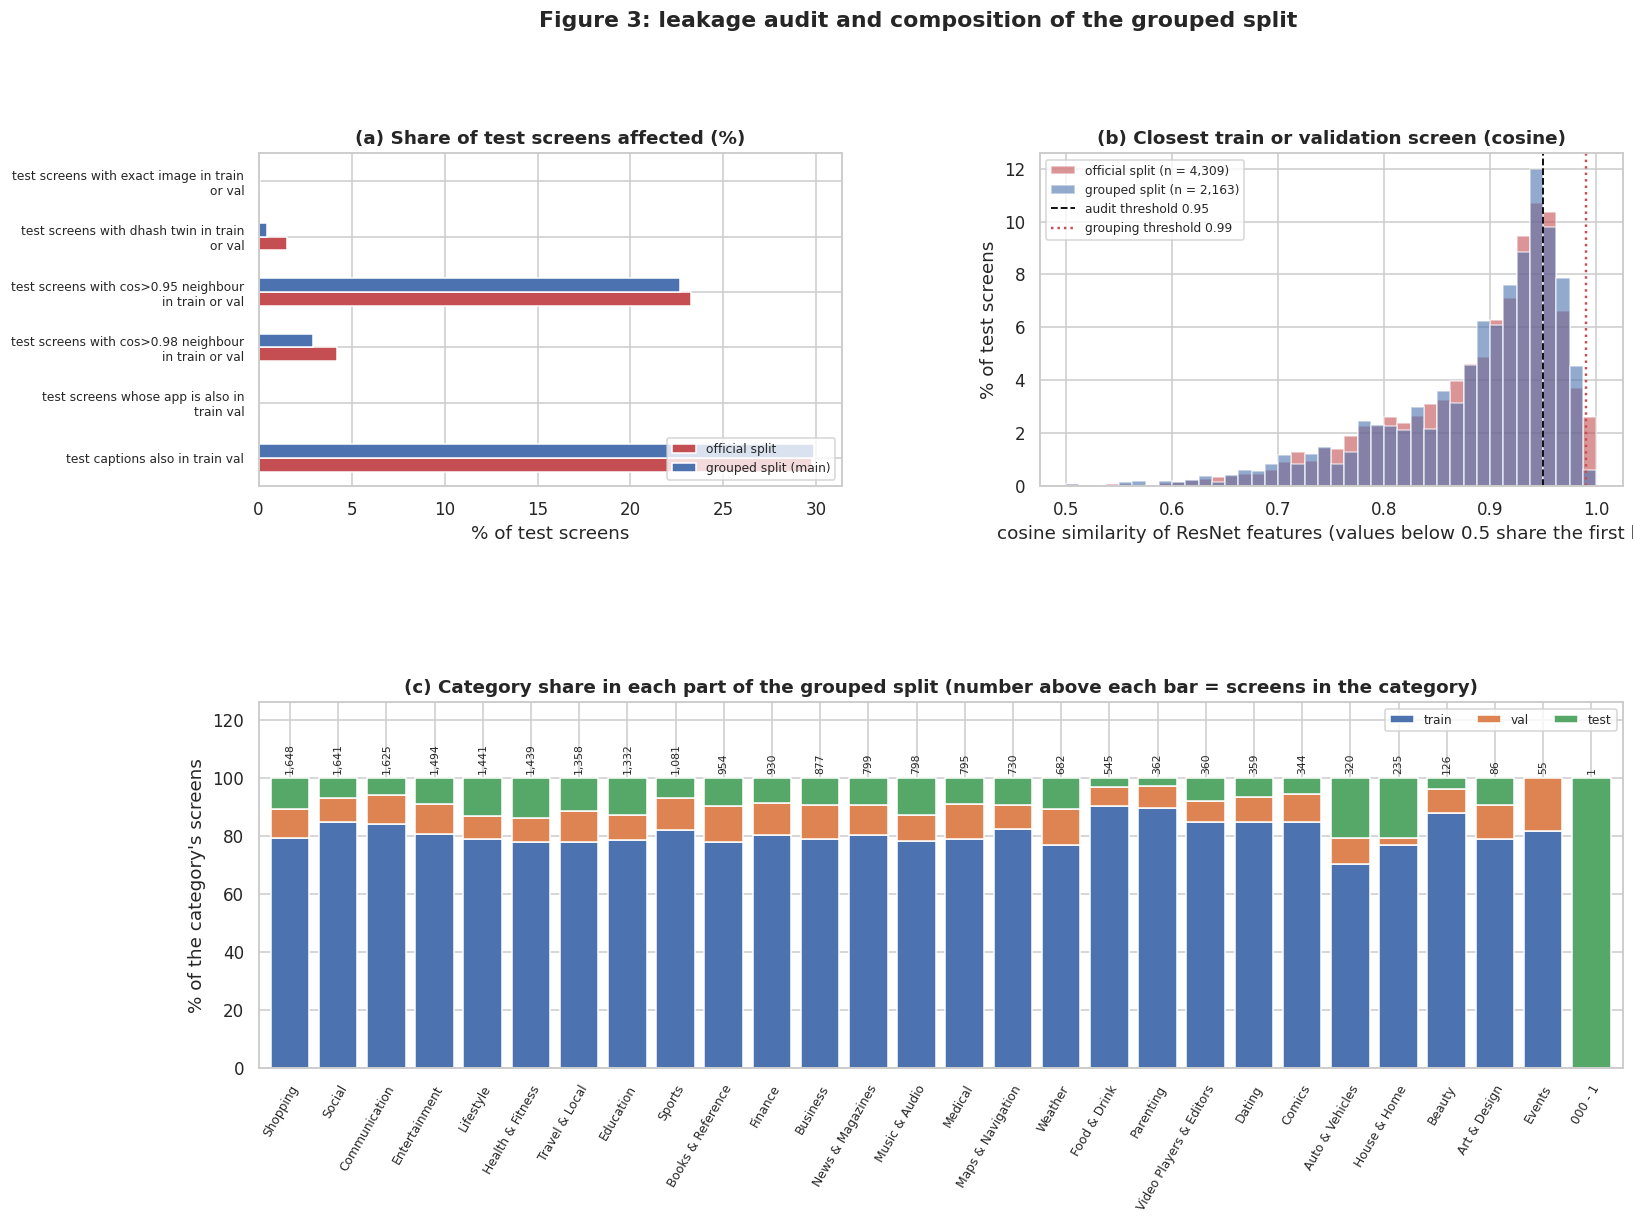

In [14]:
img_md5 = img_stats.set_index("_row").loc[scr["_row"], "md5"].to_numpy(); img_dh = img_stats.set_index("_row").loc[scr["_row"], "dhash"].to_numpy()
cap_norm_by_screen = cap.groupby("sidx")["norm"].agg(set)

def leakage_report(col):
    sp = scr[col].to_numpy(); out = {}
    te, trn = np.where(sp == "test")[0], np.where(sp != "test")[0]
    trn_set = np.zeros(len(scr), bool); trn_set[trn] = True
    out["test_screens"] = len(te)
    out["test_screens_with_exact_image_in_train_or_val_%"] = 100 * np.isin(img_md5[te], img_md5[trn]).mean()
    out["test_screens_with_dhash_twin_in_train_or_val_%"] = 100 * np.isin(img_dh[te], img_dh[trn]).mean()
    # nearest neighbours restricted to train or val screens
    nn_in_train = trn_set[knn_idx[te]]
    for thr_ in (0.95, 0.98):
        out[f"test_screens_with_cos>{thr_}_neighbour_in_train_or_val_%"] = 100 * ((knn_sim[te] > thr_) & nn_in_train).any(1).mean()
    if GROUP_COL:
        app = scr[GROUP_COL].fillna("NA").astype(str).to_numpy(); out["apps_shared_between_test_and_train_val"] = len(set(app[te]) & set(app[trn]))
        out["test_screens_whose_app_is_also_in_train_val_%"] = 100 * np.isin(app[te], app[trn]).mean()
    trn_caps = set().union(*cap_norm_by_screen.iloc[trn].tolist()); te_caps = cap[cap["sidx"].isin(te)]["norm"]
    out["test_captions_also_in_train_val_%"] = 100 * te_caps.isin(trn_caps).mean()
    return out

leak_tbl = pd.DataFrame({f"{REF_NAME}": leakage_report("split_reference"), "grouped split (main)": leakage_report("split_grouped")}).round(2)
TAB_LEAK = show_table(leak_tbl, "leakage audit of the reference split and the grouped split (percent of test screens)", "leakage_audit")
for c in leak_tbl.index: ev("leak_" + c, leak_tbl.loc[c].to_dict(), show=False)

split_tbl = pd.concat({c: pd.DataFrame({"screens": scr.groupby(c).size(), "captions": pd.Series(cap_cnt, index=scr.index).groupby(scr[c]).sum()}) for c in ["split_reference", "split_grouped"]})
TAB_SPLIT = show_table(split_tbl, "split sizes", "split_sizes")


# similarity of every test screen to its closest screen among train and validation (nearest ten neighbours)
def nn_sim_to_train(col):
    sp = scr[col].to_numpy(); te = np.where(sp == "test")[0]; in_tr = (sp != "test")
    return np.where(in_tr[knn_idx[te]], knn_sim[te], -1).max(1)
sim_ref, sim_grp = nn_sim_to_train("split_reference"), nn_sim_to_train("split_grouped")
pct_rows = [r for r in leak_tbl.index if r.endswith("%")]

fig = plt.figure(figsize=(16, 10.8)); gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.1], hspace=0.62, wspace=0.34)
ax = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])]          # (a) and (b) in one row and (c) across both columns
(leak_tbl.loc[pct_rows].rename(index=lambda s: textwrap.fill(s.replace("_%", "").replace("_", " "), 38)).iloc[::-1]).plot.barh(ax=ax[0], color=[PALETTE[3], PALETTE[0]])
ax[0].set(title="(a) Share of test screens affected (%)", xlabel="% of test screens", ylabel=""); ax[0].tick_params(axis="y", labelsize=8); ax[0].legend(fontsize=8, loc="lower right")
bins = np.linspace(0.5, 1.0, 41); w_ref, w_grp = np.full(int((sim_ref > -1).sum()), 100 / max(int((sim_ref > -1).sum()), 1)), np.full(int((sim_grp > -1).sum()), 100 / max(int((sim_grp > -1).sum()), 1))
ax[1].hist(np.clip(sim_ref[sim_ref > -1], 0.5, 1.0), bins=bins, weights=w_ref, alpha=0.6, color=PALETTE[3], label=f"{REF_NAME} (n = {int((sim_ref > -1).sum()):,})")
ax[1].hist(np.clip(sim_grp[sim_grp > -1], 0.5, 1.0), bins=bins, weights=w_grp, alpha=0.6, color=PALETTE[0], label=f"grouped split (n = {int((sim_grp > -1).sum()):,})")
ax[1].axvline(CFG["near_dup_thr"], color="k", ls="--", lw=1.2, label=f"audit threshold {CFG['near_dup_thr']}")
if GROUP_THR and abs(GROUP_THR - CFG["near_dup_thr"]) > 1e-9: ax[1].axvline(GROUP_THR, color=PALETTE[3], ls=":", lw=1.6, label=f"grouping threshold {GROUP_THR}")
ax[1].set(title="(b) Closest train or validation screen (cosine)", xlabel="cosine similarity of ResNet features (values below 0.5 share the first bin)", ylabel="% of test screens"); ax[1].legend(fontsize=8, loc="upper left")
if CAT_COL:
    cat_dist = pd.crosstab(scr[CAT_COL], scr["split_grouped"]).reindex(columns=["train", "val", "test"]).fillna(0).astype(int)
    cat_dist["total"] = cat_dist.sum(1); cat_dist = cat_dist.sort_values("total", ascending=False)
    (cat_dist[["train", "val", "test"]].div(cat_dist["total"], axis=0) * 100).plot.bar(stacked=True, ax=ax[2], color=PALETTE[:3], width=0.8)
    for j, (_, r_) in enumerate(cat_dist.iterrows()): ax[2].text(j, 101.5, f"{int(r_['total']):,}", ha="center", va="bottom", fontsize=7, rotation=90)
    ax[2].set(title="(c) Category share in each part of the grouped split (number above each bar = screens in the category)", xlabel="", ylabel="% of the category's screens", ylim=(0, 126))
    ax[2].tick_params(axis="x", labelsize=8, rotation=60); plt.setp(ax[2].get_xticklabels(), ha="right", rotation_mode="anchor"); ax[2].legend(loc="upper right", ncol=3, fontsize=8)
    ev("category_range", dict(min=int(cat_dist.total.min()), max=int(cat_dist.total.max()), n=len(cat_dist)))
else:
    ax[2].axis("off")
FIG_LEAK = savefig(fig, "leakage_and_split", "leakage audit and composition of the grouped split")

narrate(lambda: say(f"""
**Reading the results.** The grouping joined screens into **{EVIDENCE['n_groups']:,} groups** with {'a near-duplicate threshold of ' + str(GROUP_THR) if GROUP_THR else 'app-level groups only (the near-duplicate links joined too many screens)'} and the largest group holds {EVIDENCE['largest_group_share'] * 100:.1f}% of the screens. Table {TAB_LEAK} compares the two splits. Under the {REF_NAME} **{leak_tbl.loc['test_screens_with_cos>0.95_neighbour_in_train_or_val_%'].iloc[0]:.1f}%** of test screens have a visual near-duplicate (cosine above 0.95) in training or validation and **{leak_tbl.loc['test_screens_with_cos>0.95_neighbour_in_train_or_val_%'].iloc[1]:.1f}%** have one under the grouped split. {'The test apps shared with training fall from ' + format(leak_tbl.loc['apps_shared_between_test_and_train_val'].iloc[0], '.0f') + ' to ' + format(leak_tbl.loc['apps_shared_between_test_and_train_val'].iloc[1], '.0f') + '.' if GROUP_COL else ''} Exact caption texts that also occur in training make up {leak_tbl.loc['test_captions_also_in_train_val_%'].iloc[0]:.1f}% of test captions under the {REF_NAME} and {leak_tbl.loc['test_captions_also_in_train_val_%'].iloc[1]:.1f}% under the grouped split. This overlap cannot be removed because generic captions are common and so it is a property of the task. Table {TAB_SPLIT} gives the sizes of the partitions. Figure {FIG_LEAK} shows the audit (a) and the similarity of test screens to their closest training screen (b) and the category composition of the grouped split (c).
"""))


<div style="text-align: justify;">

#### 2.6.1 Results and Interpretation: Leakage Audit and Grouped Split
**The grouping.** A nearest-neighbour search over the ResNet features took 0.61 seconds. The median cosine between a screen and its closest neighbour is 0.93. This is high because pooled ResNet features are all positive and so cosine values are compressed towards one. For this reason a cosine of 0.95 flags screens with a similar layout and not only true duplicates. The grouping threshold started at 0.95 and was raised automatically to **0.99** because lower thresholds chained more than 3% of the dataset into one group. The final grouping has 5,891 groups and the largest group holds 1.7% of the screens. The fallback to app-level groups only was not triggered because the final grouping uses the threshold 0.99 and so it links screens by app and by visual similarity. The split manifest printed by the split cell records the threshold and the group sizes and a flag that would show the fallback. The grouped split has 18,080 training and 2,161 validation and 2,176 test screens as shown in Table 8 which is 80.7% and 9.6% and 9.7% of the screens.

**The audit as shown in Table 7 and Figure 3(a).** The official split already shares no app between partitions (0 shared apps) and so it is app-disjoint. The grouping adds protection against near-duplicates across apps and the effect is visible in the strictest measures: test screens with an exact image copy in training fall from 0.07% to 0.00% and screens with a difference-hash twin fall from 1.51% to 0.46% and screens with a neighbour above cosine 0.98 fall from 4.22% to 2.94%. The share of test screens with a neighbour above cosine 0.95 hardly changes (23.27% for the official split and 22.66% for the grouped split). This is expected because the grouping used 0.99 and the audit uses 0.95. It should not be read as 22.7% duplicates. The 0.98 row and the difference-hash row are the better estimates of true near-duplication and they are 2.9% and 0.5%. The proposal pilot reported 15.5% overlap with an app-level split on a sample and the larger collection has more similar neighbours. A lower threshold would remove more similarity but it would create one very large group and leave too little data for the test partition. This trade-off is discussed in Section 5.3.

**Caption overlap.** 29.8% of the test summaries occur as text in training or validation under the official split and 29.9% under the grouped split. The overlap cannot be removed because generic texts are common and it is a property of the task and not of the split.

**Figure 3(b)** shows the similarity of every test screen to its closest training or validation screen as a share of the test screens. Most test screens have a neighbour between 0.90 and 1.00 for both splits. The dashed line marks the audit threshold of 0.95 and the dotted line marks the grouping threshold of 0.99. **Figure 3(c)** shows the composition of the grouped split by category and the number of screens of each category is printed above the bars. Most categories follow the 80 and 10 and 10 pattern. Some deviate: Auto & Vehicles and House & Home have 20% of their screens in the test partition and Events has none. A grouped split moves whole apps and small categories contain few apps and so the shares of small categories are noisy. The label with a single screen sits entirely in the test partition. These deviations explain why some category estimates in Section 4.6 rest on few screens.

</div>

<div style="text-align: justify;">

## 3. Methods: Metrics, Models and Training

*   Metrics that accept multiple correct answers and are checked by unit tests
*   E0: ridge regression baseline with the BERT pooling choice made on validation data
*   E1: early fusion network and E2: contrastive dual encoder trained as retrieval systems
*   A hyper-parameter search on validation data only and three training seeds per model

All models read the same frozen standardised features and are scored on the same candidate pool.

</div>

<div style="text-align: justify;">

### 3.1 Retrieval Metrics with Multiple Positives

*   Screen to text: a hit is the best-ranked of the screen's own summaries
*   Text to screen: the only strict positive is the summary's own screen
*   Ambiguity-aware variant: every screen that carries the same text counts as correct
*   Recall@1 and Recall@5 and Recall@10 and median rank and mean reciprocal rank (MRR)

Recall values depend on the size of the candidate pool and so all models use the whole test split as one pool and every recall value is quoted together with this pool.

</div>

In [15]:
def rank_rows(Sc, M):
    # rank of the best-scoring positive for every query row; sc: (q, c) scores; m: (q, c) bool positives
    best = Sc.masked_fill(~M, float("-inf")).max(1).values
    greater = ((Sc > best[:, None]) & ~M).sum(1).float()
    ties = ((Sc == best[:, None]) & ~M).sum(1).float()
    return 1.0 + greater + 0.5 * ties

def _summ(r, p):
    return {f"{p}_R1": (r <= 1).float().mean().item() * 100, f"{p}_R5": (r <= 5).float().mean().item() * 100,
            f"{p}_R10": (r <= 10).float().mean().item() * 100, f"{p}_MRR": (1.0 / r).mean().item(), f"{p}_MedR": r.median().item()}

def retrieval_metrics(Sc, M, return_ranks=False):
    r_i, r_t = rank_rows(Sc, M), rank_rows(Sc.T, M.T)
    m = {**_summ(r_i, "i2t"), **_summ(r_t, "t2i")}
    m["avg_R1"] = 0.5 * (m["i2t_R1"] + m["t2i_R1"]); m["avg_R10"] = 0.5 * (m["i2t_R10"] + m["t2i_R10"])
    return (m, r_i, r_t) if return_ranks else m

def ranges(starts, cnts):
    # concatenation of arange(start, start + cnt) without a Python loop
    return np.arange(cnts.sum()) - np.repeat(np.cumsum(cnts) - cnts, cnts) + np.repeat(starts, cnts)

def strict_mask(cap2img, n_img):
    return cap2img[None, :] == torch.arange(n_img, device=cap2img.device)[:, None]

def ambiguity_mask(cap2img, cid, n_img):
    # image i is positive for caption j when image i owns any caption with the same normalised text as j
    u, inv = torch.unique(cid, return_inverse=True)
    inc = torch.zeros(n_img, len(u), dtype=torch.bool, device=cid.device); inc[cap2img, inv] = True
    return inc[:, inv]

# ---- unit tests (they must pass before any result is trusted) ----
_S = torch.tensor([[0.9, 0.8, 0.1, 0.2], [0.1, 0.2, 0.7, 0.6]]); _c2i = torch.tensor([0, 0, 1, 1])
_m = retrieval_metrics(_S, strict_mask(_c2i, 2))
assert _m["i2t_R1"] == 100 and _m["t2i_R1"] == 100, "both screens rank a correct caption first"
_S2 = torch.tensor([[0.1, 0.9, 0.0], [0.5, 0.5, 0.5]]); _c2i2 = torch.tensor([0, 1])
_, _ri, _rt = retrieval_metrics(_S2[:, :2], strict_mask(_c2i2, 2), return_ranks=True)
assert _ri.tolist() == [2.0, 1.5], "tie handling: average of tied ranks"
_Sa = torch.tensor([[0.2, 0.9], [0.8, 0.1]]); _cid = torch.tensor([7, 7]); _c2ia = torch.tensor([0, 1])
assert retrieval_metrics(_Sa, strict_mask(_c2ia, 2))["t2i_R1"] == 0.0
assert retrieval_metrics(_Sa, ambiguity_mask(_c2ia, _cid, 2))["t2i_R1"] == 100.0, "identical texts count as correct under the ambiguity-aware metric"
assert ranges(np.array([5, 20]), np.array([2, 3])).tolist() == [5, 6, 20, 21, 22]
print("Metric unit tests passed.")

say("""
**Reading the results.** All unit tests passed. They check the rank of the best positive and the average rank of tied scores and the strict and the ambiguity-aware masks and the vectorised range builder. A metric that passes these checks on hand-built cases can be trusted on the real score matrices.
""")


Metric unit tests passed.


<div style="text-align: justify;">

This step defines the retrieval metrics. A score matrix has one row per screen and one column per caption. For a screen query the rank of its best own caption is one plus the number of non-positive captions that score higher and half the number of non-positives that tie (so that ties never favour a model). For a caption query the same function is applied to the transposed matrix. The strict mask marks only the caption's own screen and the ambiguity-aware mask marks every screen that owns a caption with the same normalised text. This second mask is built with an incidence matrix between screens and caption texts. Recall at K is the share of queries with rank at most K and MRR is the mean of one over the rank and the median rank is reported because it is robust to a few very bad queries. The aggregate Recall@10 averages the two directions and the directions are always reported separately as well. All steps are boolean-mask operations on tensors and need no Python loop over queries.

</div>

<div style="text-align: justify;">

### 3.2 E0 Ridge Regression Baseline and BERT Pooling

*   Map caption features into image-feature space with a closed-form ridge solution
*   Rank candidates by cosine similarity in both directions
*   Choose the regularisation strength and the pooling (mean or `[CLS]`) on validation data

The baseline is a valid retrieval model because the mapped caption does not use the true screen and so it can rank unseen pairs in both directions.

</div>

In [16]:

# ---- feature normalization ----

def fit_scaler(X):
    mean = X.mean(axis=0, keepdims=True)
    std = X.std(axis=0, keepdims=True) + 1e-6
    return mean, std


# ---- build train, validation and test data ----

def build_data(split_col, pool, seed=0):

    # check required variables
    required_vars = [
        "scr", "img_feats", "txt_mean", "txt_cls",
        "cap_start", "cap_cnt", "cap_cid"
    ]

    for var in required_vars:
        if var not in globals():
            raise NameError(
                f"Required variable '{var}' is not defined. "
                "Run the feature extraction and split preparation cells first."
            )

    if split_col not in scr.columns:
        raise KeyError(
            f"Split column '{split_col}' not found in scr. "
            f"Available columns: {list(scr.columns)}"
        )

    if pool not in ["mean", "cls"]:
        raise ValueError("pool must be either 'mean' or 'cls'.")

    # select text feature pooling
    TX = txt_mean if pool == "mean" else txt_cls

    # get image split labels
    split_values = scr[split_col].to_numpy()

    raw = {}

    # build each dataset split
    for split_name in ["train", "val", "test"]:

        screen_ids = np.where(split_values == split_name)[0]

        caption_ids = ranges(
            cap_start[screen_ids],
            cap_cnt[screen_ids]
        )

        counts = cap_cnt[screen_ids]

        starts = np.concatenate([
            [0],
            np.cumsum(counts)[:-1]
        ])

        raw[split_name] = {
            "sid": screen_ids,
            "XI": img_feats[screen_ids],
            "XT": TX[caption_ids],
            "cnt": counts,
            "start": starts,
            "cap2img": np.repeat(
                np.arange(len(screen_ids)),
                counts
            ),
            "cid": cap_cid[caption_ids],
            "cap_idx": caption_ids
        }

    # ---- create a training subset ----

    rng = np.random.default_rng(seed)

    n_val = len(raw["val"]["sid"])
    n_train = len(raw["train"]["sid"])

    subset_size = min(n_val, n_train)

    selected = np.sort(
        rng.choice(
            n_train,
            size=subset_size,
            replace=False
        )
    )

    train_data = raw["train"]

    selected_sids = train_data["sid"][selected]

    selected_cids = ranges(
        cap_start[selected_sids],
        cap_cnt[selected_sids]
    )

    selected_counts = cap_cnt[selected_sids]

    raw["train_sub"] = {
        "sid": selected_sids,
        "XI": img_feats[selected_sids],
        "XT": TX[selected_cids],
        "cnt": selected_counts,
        "start": np.concatenate([
            [0],
            np.cumsum(selected_counts)[:-1]
        ]),
        "cap2img": np.repeat(
            np.arange(len(selected_sids)),
            selected_counts
        ),
        "cid": cap_cid[selected_cids],
        "cap_idx": selected_cids
    }

    # ---- fit scalers using training data only ----

    image_mean, image_std = fit_scaler(
        raw["train"]["XI"]
    )

    text_mean, text_std = fit_scaler(
        raw["train"]["XT"]
    )

    # ---- convert arrays to pytorch tensors ----

    def to_float_tensor(array):
        return torch.as_tensor(
            array,
            dtype=torch.float32,
            device=DEVICE
        )

    def to_long_tensor(array):
        return torch.as_tensor(
            array,
            dtype=torch.long,
            device=DEVICE
        )

    D = {}

    for split_name, data in raw.items():

        cap2img = to_long_tensor(data["cap2img"])

        normalized_images = (
            data["XI"] - image_mean
        ) / image_std

        normalized_text = (
            data["XT"] - text_mean
        ) / text_std

        D[split_name] = {
            "XI": to_float_tensor(normalized_images),
            "XT": to_float_tensor(normalized_text),
            "cap2img": cap2img,
            "start": to_long_tensor(data["start"]),
            "cnt": to_long_tensor(data["cnt"]),
            "cid": to_long_tensor(data["cid"]),
            "sid": data["sid"],
            "cap_idx": data["cap_idx"],
            "M": strict_mask(
                cap2img,
                len(data["sid"])
            )
        }

    # ---- create test ambiguity mask ----

    D["test"]["M_amb"] = ambiguity_mask(
        D["test"]["cap2img"],
        D["test"]["cid"],
        len(D["test"]["sid"])
    )

    return D


# ---- ridge regression ----

def ridge_fit(XT, Y, alpha):

    XT = XT.double()
    Y = Y.double()

    identity = torch.eye(
        XT.shape[1],
        device=XT.device,
        dtype=XT.dtype
    )

    weights = torch.linalg.solve(
        XT.T @ XT + alpha * identity,
        XT.T @ Y
    )

    return weights.float()


# ---- compute retrieval scores ----

def ridge_scores(W, data):

    image_features = F.normalize(
        data["XI"],
        dim=-1
    )

    text_features = F.normalize(
        data["XT"] @ W,
        dim=-1
    )

    return image_features @ text_features.T


# ---- compare BERT pooling strategies ----

ridge_rows = []

pooling_methods = ["mean", "cls"]

alpha_values = [
    1, 10, 100, 1000, 10000, 100000
]

for pool in pooling_methods:

    print(f"\nEvaluating {pool} pooling...")

    Dp = build_data(
        split_col="split_grouped",
        pool=pool,
        seed=0
    )

    for alpha in alpha_values:

        # fit ridge regression
        W = ridge_fit(
            Dp["train"]["XT"],
            Dp["train"]["XI"][
                Dp["train"]["cap2img"]
            ],
            alpha
        )

        # calculate validation retrieval scores
        scores = ridge_scores(
            W,
            Dp["val"]
        )

        # evaluate retrieval performance
        metrics = retrieval_metrics(
            scores,
            Dp["val"]["M"]
        )

        ridge_rows.append({
            "pooling": pool,
            "alpha": alpha,
            "val_avg_R10": metrics["avg_R10"],
            "val_i2t_R10": metrics["i2t_R10"],
            "val_t2i_R10": metrics["t2i_R10"]
        })

    del Dp
    gc.collect()


# ---- results table ----

ridge_tbl = pd.DataFrame(ridge_rows)

TAB_RIDGE = show_table(
    ridge_tbl.round(2),
    "ridge baseline and BERT pooling comparison (validation, grouped split)",
    "ridge_pooling",
    index=False
)


# ---- select best configuration ----

best = ridge_tbl.loc[
    ridge_tbl["val_avg_R10"].idxmax()
]

POOL = best["pooling"]
ALPHA = float(best["alpha"])

ev("bert_pooling_chosen", POOL)
ev("ridge_alpha", ALPHA)

ev(
    "val_avg_R10_by_pooling",
    ridge_tbl.groupby("pooling")[
        "val_avg_R10"
    ].max().round(2).to_dict()
)


# ---- performance summary ----

mean_best = ridge_tbl.loc[
    ridge_tbl["pooling"] == "mean",
    "val_avg_R10"
].max()

cls_best = ridge_tbl.loc[
    ridge_tbl["pooling"] == "cls",
    "val_avg_R10"
].max()

score_range = (
    ridge_tbl["val_avg_R10"].max()
    - ridge_tbl["val_avg_R10"].min()
)

narrate(
    lambda: say(f"""
**Reading the results.**

Table {TAB_RIDGE} compares the two BERT pooling strategies
(mean pooling and [CLS] pooling) across six regularisation
strengths.

The best validation score for **mean pooling** is
**{mean_best:.2f}%** mean Recall@10.

The best validation score for **[CLS] pooling** is
**{cls_best:.2f}%** mean Recall@10.

The selected configuration is **{POOL} pooling**
with a regularisation parameter of **alpha = {ALPHA:g}**.

The difference between the highest and lowest validation
scores is **{score_range:.2f} percentage points**.

Therefore, {
    'the choice of pooling and regularisation has a noticeable effect.'
    if score_range > 1
    else 'the baseline is relatively insensitive to these settings.'
}
""")
)



Evaluating mean pooling...

Evaluating cls pooling...
Table 9: ridge baseline and BERT pooling comparison (validation, grouped split)


,pooling,alpha,val_avg_R10,val_i2t_R10,val_t2i_R10
0,mean,1,7.70,9.25,6.14
1,mean,10,7.69,9.25,6.13
2,mean,100,7.75,9.35,6.16
3,mean,1000,7.76,9.44,6.07
4,mean,10000,7.23,8.75,5.72
5,mean,100000,6.39,7.96,4.82
6,cls,1,6.91,8.33,5.48
7,cls,10,6.90,8.33,5.47
8,cls,100,6.99,8.51,5.47
9,cls,1000,7.16,8.84,5.48


[evidence] bert_pooling_chosen = mean
[evidence] ridge_alpha = 1000.0
[evidence] val_avg_R10_by_pooling = {'cls': 7.16, 'mean': 7.76}


<div style="text-align: justify;">

This step builds the model-ready tensors for a split. For each partition it gathers the screen features and the caption features and the offsets with the vectorised range builder and standardises both blocks with training statistics only. It also builds a training subset with the same number of screens as the validation split so that the training and validation recall are measured on pools of equal size and the gap between them is fair. The ridge baseline solves `W = (X'X + alpha I)^-1 X'Y` in double precision where `X` holds the caption features and `Y` the standardised features of the owning screens (Hoerl & Kennard, 1970). A candidate pair is scored by the cosine similarity between the screen features and the mapped caption. The regularisation strength is searched on a logarithmic grid and the two pooling choices are compared on the validation split. This baseline is transparent and has no hidden layers and its cost is one matrix product and it sets the bar that the learned models have to beat. It has a limit that matters for retrieval: a single linear map from text to image space cannot represent interactions between the two feature sets.

</div>

<div style="text-align: justify;">

#### 3.2.1 Results and Interpretation: Ridge Baseline and BERT Pooling
Table 9 compares mean pooling and `[CLS]` pooling over six regularisation strengths on the validation split. Mean pooling is better: its best mean Recall@10 is **7.78%** (alpha 100) against 7.13% for `[CLS]` pooling (alpha 1000). Mean pooling is ahead by 0.4 to 0.8 points at every alpha value. The `[CLS]` vector of a pre-trained BERT without fine-tuning is trained for next-sentence prediction and not as a sentence summary and so averaging the token states is the better frozen representation. Reimers and Gurevych (2019) report the same ordering for sentence embeddings. Within mean pooling the score is flat for alpha between 1 and 1000 (7.69% to 7.78%) and it falls at 10,000 (7.24%) and at 100,000 (6.39%) when the mapping is shrunk too strongly (Hoerl & Kennard, 1970). The overall spread is 2.0 points. The validation score is lower for text to screen (6.1%) than for screen to text (9.4%) at the chosen setting and this direction gap persists in every later model.

The chosen setting (mean pooling and alpha 100) is carried to the test set where the ridge baseline reaches 7.86% and so validation (7.78%) and test (7.86%) agree and the baseline shows no gap between the two partitions. A closed-form model with 1.57 million parameters (2048 by 768) is a useful floor: it needs no training loop and its error is easy to interpret. The unit tests of the metric functions passed as described in Section 3.1.

</div>

<div style="text-align: justify;">

### 3.3 E1 Early Fusion and E2 Contrastive Dual Encoder

*   E1 projects the two feature sets to a common width and concatenates them and scores each pair with an MLP
*   E2 projects them into a shared normalised space and trains with the symmetric InfoNCE loss and a learnable temperature
*   Mask false negatives and sample one of the captions of every screen at each step
*   AdamW with weight decay and dropout and warm-up with cosine decay and early stopping on validation recall

</div>

In [17]:
def mlp(din, dh, dout, p): return nn.Sequential(nn.Linear(din, dh), nn.GELU(), nn.Dropout(p), nn.Linear(dh, dout))

class EarlyFusion(nn.Module):
    def __init__(self, d_img, d_txt, hid=512, emb=256, p=0.3):
        super().__init__()
        self.pi = nn.Sequential(nn.Linear(d_img, hid), nn.GELU(), nn.Dropout(p)); self.pt = nn.Sequential(nn.Linear(d_txt, hid), nn.GELU(), nn.Dropout(p))
        self.fa = nn.Linear(hid, hid); self.fb = nn.Linear(hid, hid, bias=False)     # fa and fb together equal Linear(2*hid, hid) on the concatenation
        self.drop = nn.Dropout(p); self.out = nn.Linear(hid, 1)
    def forward(self, xi, xt):                                                       # all pairs: (n_img, n_txt) logits
        a, b = self.fa(self.pi(xi)), self.fb(self.pt(xt))
        return self.out(self.drop(F.gelu(a[:, None, :] + b[None, :, :]))).squeeze(-1)
    @torch.no_grad()
    def score_matrix(self, XI, XT, chunk_elems=4e7):
        self.eval(); a, b = self.fa(self.pi(XI)), self.fb(self.pt(XT)); n_t, h = b.shape
        c = max(1, int(chunk_elems // (n_t * h))); return torch.cat([self.out(F.gelu(a[s:s + c, None, :] + b[None])).squeeze(-1) for s in range(0, len(a), c)])

class DualEncoder(nn.Module):
    def __init__(self, d_img, d_txt, hid=512, emb=256, p=0.3):
        super().__init__()
        self.fi, self.ft = mlp(d_img, hid, emb, p), mlp(d_txt, hid, emb, p)
        self.logit_scale = nn.Parameter(torch.tensor(math.log(1 / 0.07)))
    def enc_i(self, x): return F.normalize(self.fi(x), dim=-1)
    def enc_t(self, x): return F.normalize(self.ft(x), dim=-1)
    def forward(self, xi, xt): return self.logit_scale.exp().clamp(max=100.0) * self.enc_i(xi) @ self.enc_t(xt).T
    @torch.no_grad()
    def score_matrix(self, XI, XT): self.eval(); return self.enc_i(XI) @ self.enc_t(XT).T

def loss_fn(kind, logits, cid):
    B = len(logits); eye = torch.eye(B, dtype=torch.bool, device=logits.device)
    false_neg = (cid[:, None] == cid[None, :]) & ~eye                                  # same text on two different screens
    if kind == "contrastive":
        lg = logits.float().masked_fill(false_neg, -1e4); y = torch.arange(B, device=logits.device)
        return 0.5 * (F.cross_entropy(lg, y) + F.cross_entropy(lg.T, y))               # symmetric InfoNCE
    pos = F.softplus(-logits[eye]).mean(); neg = F.softplus(logits[~eye & ~false_neg]).mean()
    return pos + neg                                                                    # balanced binary cross-entropy

# ---- multi-positive objective: every caption of a screen is a positive at every step ----
def multi_positive_from_logits(lg, owner, cid):
    # lg: (B images, T captions) logits; owner: image index of each caption; cid: text id of each caption
    lg = lg.float(); B, T = lg.shape
    own = F.one_hot(owner, B).T.bool()                                                 # (B,T) caption t belongs to image b
    same_txt = (cid[:, None] == cid[None, :]).float()
    fn = ((own.float() @ same_txt) > 0) & ~own                                          # same text as a caption of image b but owned by another screen: neither positive nor negative
    neg_i = lg.masked_fill(own | fn, -1e4)                                              # negatives of image b: other positives and false negatives are excluded
    den_i = torch.logsumexp(neg_i, 1, keepdim=True)
    i2t = F.softplus(den_i - lg)[own].mean()                                            # every positive pair is its own term: -log(exp(l) / (exp(l) + sum of negatives))
    t2i = F.cross_entropy(lg.T.masked_fill(fn.T, -1e4), owner)                          # each caption has one owner image; images with the same text are masked
    return 0.5 * (i2t + t2i)

def multi_positive_loss(model, tr, idx):
    cnt = tr["cnt"][idx]; start = tr["start"][idx]; B = len(idx)
    owner = torch.repeat_interleave(torch.arange(B, device=idx.device), cnt)
    first = torch.cumsum(cnt, 0) - cnt
    ci = start[owner] + torch.arange(len(owner), device=idx.device) - first[owner]       # all captions of the screens in the batch
    return multi_positive_from_logits(model(tr["XI"][idx], tr["XT"][ci]), owner, tr["cid"][ci])

# ---- tests: fusion layer equivalence and loss behaviour ----
_m = EarlyFusion(6, 5, hid=4, p=0.0).eval(); _xi, _xt = torch.randn(3, 6), torch.randn(2, 5)
_cat = torch.cat([_m.pi(_xi)[:, None, :].expand(3, 2, 4), _m.pt(_xt)[None].expand(3, 2, 4)], -1)
_lin = nn.Linear(8, 4); _lin.weight.data = torch.cat([_m.fa.weight, _m.fb.weight], 1); _lin.bias.data = _m.fa.bias.data
assert torch.allclose(_m.out(F.gelu(_lin(_cat))).squeeze(-1), _m(_xi, _xt), atol=1e-5), "split fusion layer must equal concat + Linear"
assert torch.allclose(_m.score_matrix(_xi, _xt), _m(_xi, _xt), atol=1e-5)
_lg = torch.eye(4) * 10; assert loss_fn("contrastive", _lg, torch.arange(4)).item() < 1e-3
assert loss_fn("contrastive", _lg, torch.tensor([0, 0, 1, 2])).item() < 1e-3, "masked false negatives are not penalised"
# multi-positive tests on a synthetic batch: image 0 owns captions A (text 0) and B (text 1); image 1 owns C (text 2) and D (text 0, the same text as A)
_owner = torch.tensor([0, 0, 1, 1]); _cid = torch.tensor([0, 1, 2, 0])
_lg = torch.full((2, 4), -10.0); _lg[0, 0] = _lg[0, 1] = 10.0; _lg[1, 2] = _lg[1, 3] = 10.0
_l_all = multi_positive_from_logits(_lg, _owner, _cid).item()
assert _l_all < 1e-3, "all known positives scored high must give a near-zero loss"
_lg2 = _lg.clone(); _lg2[0, 3] = 25.0; _lg2[1, 0] = 25.0                                  # the two false negatives (same text on another screen) get huge scores
assert abs(multi_positive_from_logits(_lg2, _owner, _cid).item() - _l_all) < 1e-4, "false negatives must not be penalised"
_lg3 = _lg.clone(); _lg3[0, 1] = -10.0                                                     # one of the two positives of image 0 is not retrieved
assert multi_positive_from_logits(_lg3, _owner, _cid).item() > _l_all + 0.1, "a missed positive must raise the loss"
_lg4 = _lg.clone(); _lg4[0, 2] = 25.0                                                      # a true negative scores higher than the positives of image 0
assert multi_positive_from_logits(_lg4, _owner, _cid).item() > _l_all + 1.0, "a true negative must be penalised"
print("Model unit tests passed (including the multi-positive loss).")

say("""
**Reading the results.** The unit tests passed: the split fusion layer is numerically identical to a linear layer on the concatenation and the batched score matrix equals the pairwise forward pass and the contrastive loss ignores masked false negatives.
""")

Model unit tests passed (including the multi-positive loss).


In [18]:
def run_training(kind, seed, D, hp, epochs=None, patience=None, verbose=False):
    seed_everything(seed); epochs = epochs or CFG["epochs"]; patience = patience or CFG["patience"]
    tr, va = D["train"], D["val"]
    model = (EarlyFusion if kind == "early" else DualEncoder)(tr["XI"].shape[1], tr["XT"].shape[1], hid=hp["hid"], emb=hp["emb"], p=hp["dropout"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["wd"])
    n_tr = len(tr["sid"]) if "sid" in tr else tr["XI"].shape[0]; bs = hp["batch"]; steps_ep = max(1, math.ceil(n_tr / bs)); total = epochs * steps_ep; warm = steps_ep
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(s, total) / total)))
    hist, best, bad = [], dict(score=-1, state=None, epoch=0), 0
    vsel = torch.arange(min(1024, len(va["XI"])), device=DEVICE)
    gpu_reset(); t_start = time.perf_counter()
    for ep in range(1, epochs + 1):
        t0 = time.perf_counter(); model.train(); perm = torch.randperm(n_tr, device=DEVICE); losses = []
        for b in range(0, n_tr, bs):
            idx = perm[b:b + bs]
            if len(idx) < 8: continue
            ci = tr["start"][idx] + (torch.rand(len(idx), device=DEVICE) * tr["cnt"][idx]).long()
            loss = multi_positive_loss(model, tr, idx) if kind == "contrastive_mp" else loss_fn(kind, model(tr["XI"][idx], tr["XT"][ci]), tr["cid"][ci])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step(); losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            ci = va["start"][vsel]; vloss = loss_fn("contrastive" if kind == "contrastive_mp" else kind, model(va["XI"][vsel], va["XT"][ci]), va["cid"][ci]).item()
            mv = retrieval_metrics(model.score_matrix(va["XI"], va["XT"]), va["M"])
            mt = retrieval_metrics(model.score_matrix(D["train_sub"]["XI"], D["train_sub"]["XT"]), D["train_sub"]["M"])
        hist.append(dict(epoch=ep, train_loss=float(np.mean(losses)), val_loss=vloss, train_R10=mt["avg_R10"], val_R10=mv["avg_R10"], val_R1=mv["avg_R1"], epoch_s=time.perf_counter() - t0))
        if mv["avg_R10"] > best["score"]: best, bad = dict(score=mv["avg_R10"], state=copy.deepcopy(model.state_dict()), epoch=ep), 0
        else:
            bad += 1
            if bad >= patience: break
        if verbose: print(hist[-1])
    model.load_state_dict(best["state"]); model.eval()
    return dict(model=model, hist=pd.DataFrame(hist), best_epoch=best["epoch"], best_val=best["score"], train_s=time.perf_counter() - t_start,
                peak_gb=gpu_peak_gb(), params=sum(p.numel() for p in model.parameters()), hp=dict(hp))

DEFAULT_HP = dict(lr=CFG["lr"], wd=CFG["wd"], dropout=CFG["dropout"], hid=CFG["hid"], emb=CFG["emb"], batch=CFG["batch"])
D_main = build_data("split_grouped", POOL)
print({s: (len(D_main[s]["sid"]), len(D_main[s]["cap2img"])) for s in ["train", "val", "test", "train_sub"]}, "(screens, captions)")
ev("grouped_split_sizes", {s: len(D_main[s]["sid"]) for s in ["train", "val", "test"]})

{'train': (18080, 89622), 'val': (2161, 10704), 'test': (2176, 10780), 'train_sub': (2161, 10704)} (screens, captions)
[evidence] grouped_split_sizes = {'train': 18080, 'val': 2161, 'test': 2176}


<div style="text-align: justify;">

This step defines the two trainable models and the training loop. **Early fusion** projects the image features and the caption features to the same width with a linear layer and a GELU activation and dropout (Srivastava et al., 2014). The two projections are concatenated and a second layer and an output layer give a match logit. The first fusion layer is written as the sum of two linear maps and this is mathematically the same as a linear layer on the concatenation but it lets every image-caption pair of a batch be scored without building the concatenations. The model is trained with a balanced binary cross-entropy over all pairs of a batch with the diagonal as positives. At inference it runs the fusion layer once per query-candidate pair and so its cost grows with the size of the gallery. **The contrastive dual encoder** uses one projection MLP per modality and normalises the outputs. Logits are the scaled cosine similarities and the scale is a learnable temperature that starts at 1 over 0.07 and is capped at 100 (Radford et al., 2021). The loss is the symmetric InfoNCE: the average of the image-to-text and the text-to-image cross-entropy over the batch (Chen et al., 2020). Gallery embeddings can be computed once. In both models a pair of batch items that share a caption text is not treated as a negative pair. One of the captions of every screen is sampled at each step and so all captions act as positives over the epochs. The optimiser is AdamW with decoupled weight decay (Loshchilov & Hutter, 2019). The learning rate follows a linear warm-up of one epoch and a cosine decay written as a lambda schedule. The checkpoint with the best mean of the two Recall@10 values on the validation split is kept and training stops when this value has not improved for `patience` epochs.

</div>

<div style="text-align: justify;">

#### 3.3.1 Results and Interpretation: Model Unit Tests

The message "Model unit tests passed" confirms three properties. The split fusion layer of the early fusion model is numerically identical to a single linear layer on the concatenated features and so scoring all image-caption pairs of a batch without building the concatenations does not change the model. The batched score matrix equals the pairwise forward pass for the same pairs. The contrastive loss ignores masked false negatives. These tests protect the main efficiency idea of the implementation and the correctness of the loss. The printed tuple gives the sizes of the model-ready partitions as (screens and captions): training (18,080 and 89,622) and validation (2,161 and 10,704) and test (2,176 and 10,780) and a training subset with the size of the validation split (2,161 and 10,704). The training subset allows a fair comparison between training and validation recall. The message also covers the optional multi-positive loss. A synthetic batch in which one screen owns two captions and another screen shares one caption text shows that all known positives give a near-zero loss when they score high and that a missed positive and a high-scoring true negative raise the loss and that the scores of false negatives do not change it.

</div>

<div style="text-align: justify;">

### 3.4 Hyper-parameter Search

*   A small random search over learning rate and weight decay and dropout and hidden width and embedding size and batch size (Bergstra & Bengio, 2012)
*   The first trial is always the default configuration
*   Selection on validation data only

</div>

search early:   0%|          | 0/8 [00:00<?, ?it/s]

search contrastive:   0%|          | 0/8 [00:00<?, ?it/s]

Table 10: hyper-parameter search (validation Recall@10 as the mean of both directions)


,model,trial,lr,wd,dropout,hid,emb,batch,best_epoch,val_avg_R10,train_avg_R10,gap,params_M
8,contrastive,0,0.001,0.010,0.3,512,256,256,25,11.662,60.403,48.741,1.705
12,contrastive,4,0.003,0.010,0.3,512,128,512,20,11.569,59.820,48.251,1.574
9,contrastive,1,0.000,0.100,0.3,512,256,512,13,11.368,34.042,22.674,1.705
14,contrastive,6,0.001,0.001,0.1,512,512,128,20,11.113,71.746,60.634,1.968
10,contrastive,2,0.000,0.100,0.1,256,256,512,20,10.884,40.936,30.052,0.853
15,contrastive,7,0.003,0.100,0.1,512,128,512,13,10.816,55.762,44.946,1.574
11,contrastive,3,0.003,0.100,0.5,1024,256,128,21,10.558,49.521,38.963,3.410
13,contrastive,5,0.003,0.010,0.3,1024,256,256,7,10.175,30.427,20.252,3.410
6,early,6,0.001,0.001,0.1,512,512,128,20,9.320,21.968,12.648,1.968
0,early,0,0.001,0.010,0.3,512,256,256,25,8.842,18.123,9.281,1.968


[evidence] best_hyperparameters = {'early': {'lr': 0.001, 'wd': 0.001, 'dropout': 0.1, 'hid': 512, 'emb': 512, 'batch': 128}, 'contrastive': {'lr': 0.001, 'wd': 0.01, 'dropout': 0.3, 'hid': 512, 'emb': 256, 'batch': 256}}


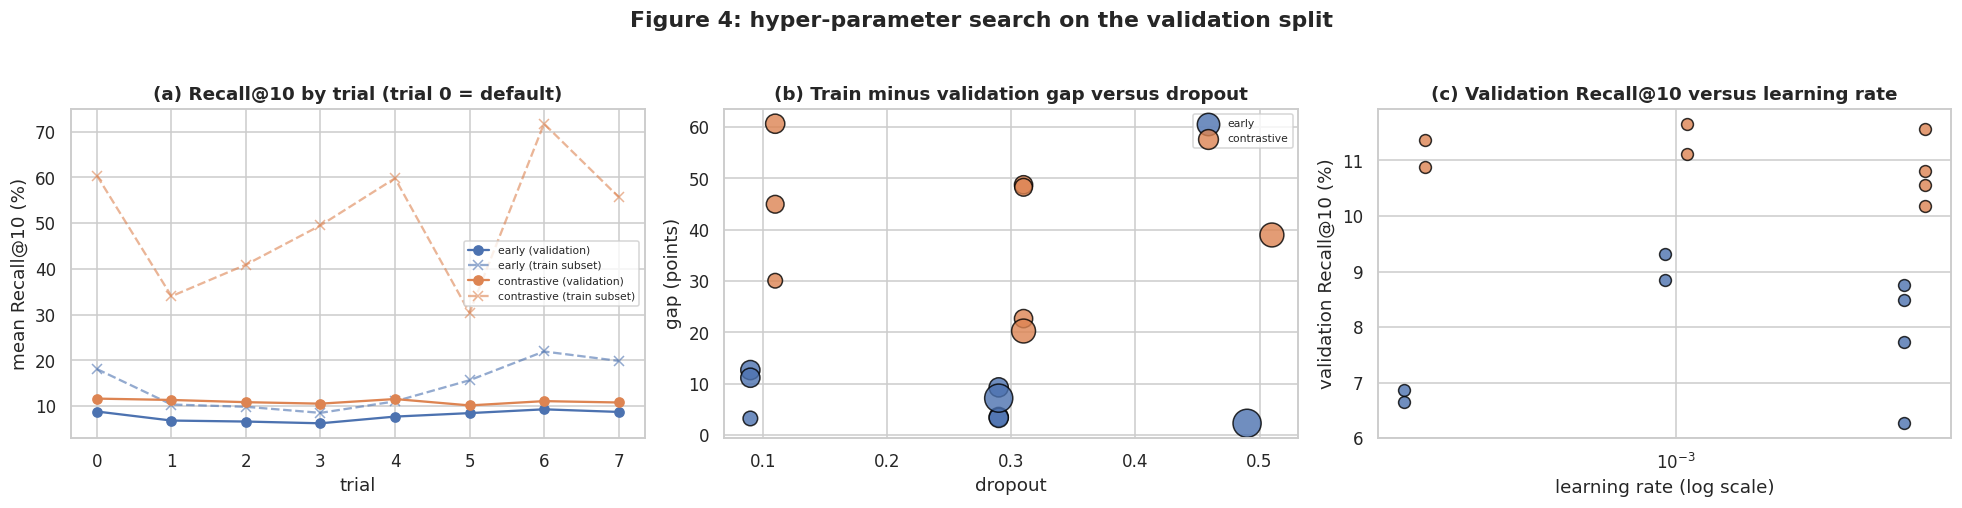

In [19]:
SPACE = dict(lr=[3e-4, 1e-3, 3e-3], wd=[1e-3, 1e-2, 1e-1], dropout=[0.1, 0.3, 0.5], hid=[256, 512, 1024], emb=[128, 256, 512], batch=[128, 256, 512])
def sample_hp(rng): return {k: v[rng.integers(len(v))] for k, v in SPACE.items()}

SEARCH, BEST_HP = [], {}
rng = np.random.default_rng(CFG["seed"])
trials = [DEFAULT_HP] + [sample_hp(rng) for _ in range(CFG["search_trials"] - 1)]
for kind in ["early", "contrastive"]:
    for k, hp in enumerate(tqdm(trials, desc=f"search {kind}")):
        r = run_training(kind, 0, D_main, hp, epochs=CFG["search_epochs"], patience=CFG["search_patience"])
        last = r["hist"].iloc[r["best_epoch"] - 1]
        SEARCH.append(dict(model=kind, trial=k, **hp, best_epoch=r["best_epoch"], val_avg_R10=r["best_val"], train_avg_R10=last["train_R10"], gap=last["train_R10"] - r["best_val"], params_M=r["params"] / 1e6))
        del r; gc.collect()
search_tbl = pd.DataFrame(SEARCH)
for kind in ["early", "contrastive"]:
    BEST_HP[kind] = {k: (search_tbl[(search_tbl.model == kind)].sort_values("val_avg_R10", ascending=False).iloc[0][k]) for k in DEFAULT_HP}
    BEST_HP[kind] = {k: (type(DEFAULT_HP[k])(v)) for k, v in BEST_HP[kind].items()}
TAB_SEARCH = show_table(search_tbl.sort_values(["model", "val_avg_R10"], ascending=[True, False]).round(3), "hyper-parameter search (validation Recall@10 as the mean of both directions)", "hparam_search", index=False)
ev("best_hyperparameters", BEST_HP)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
for j, kind in enumerate(["early", "contrastive"]):
    s_ = search_tbl[search_tbl.model == kind]
    ax[0].plot(s_.trial, s_.val_avg_R10, marker="o", color=PALETTE[j], label=f"{kind} (validation)"); ax[0].plot(s_.trial, s_.train_avg_R10, marker="x", ls="--", color=PALETTE[j], alpha=0.6, label=f"{kind} (train subset)")
    ax[1].scatter(s_.dropout + (j - 0.5) * 0.02, s_.gap, s=40 + 60 * s_.params_M, color=PALETTE[j], alpha=0.8, edgecolor="k", label=kind)
    ax[2].scatter(s_.lr * (1 + 0.1 * (j - 0.5)), s_.val_avg_R10, s=60, color=PALETTE[j], alpha=0.8, edgecolor="k", label=kind)
ax[0].set(title="(a) Recall@10 by trial (trial 0 = default)", xlabel="trial", ylabel="mean Recall@10 (%)"); ax[0].legend(fontsize=7)
ax[1].set(title="(b) Train minus validation gap versus dropout", xlabel="dropout", ylabel="gap (points)"); ax[1].legend(fontsize=7)
ax[2].set(title="(c) Validation Recall@10 versus learning rate", xlabel="learning rate (log scale)", xscale="log", ylabel="validation Recall@10 (%)")
FIG_SEARCH = savefig(fig, "hparam_search", "hyper-parameter search on the validation split")

def _search_text():
    lines = []
    for kind, nm in [("early", "Early fusion"), ("contrastive", "Contrastive dual encoder")]:
        s_ = search_tbl[search_tbl.model == kind]; d0 = s_[s_.trial == 0].val_avg_R10.iloc[0]; b = s_.val_avg_R10.max(); w = s_.val_avg_R10.min(); hp = BEST_HP[kind]
        lines.append(f"- **{nm}.** The default configuration scores {d0:.2f}% and the best of {len(s_)} trials scores **{b:.2f}%** ({b - d0:+.2f} points) and the worst scores {w:.2f}%. The best setting is learning rate {hp['lr']:g} and weight decay {hp['wd']:g} and dropout {hp['dropout']:g} and hidden width {hp['hid']} and embedding size {hp['emb']} and batch size {hp['batch']}.")
    say(f"""
**Reading the results.** Table {TAB_SEARCH} lists every trial and Figure {FIG_SEARCH} shows the validation score and the train gap.

""" + "\n".join(lines) + f"""

The spread between the best and the worst trial shows how much the hyper-parameters matter. Figure {FIG_SEARCH}(a) compares the validation and the train-subset recall and Figure {FIG_SEARCH}(b) shows whether stronger dropout shrinks the gap. Figure {FIG_SEARCH}(c) shows the sensitivity to the learning rate.
""")
narrate(_search_text)


<div style="text-align: justify;">

This step runs a random search. The space has three values for each of six settings (learning rate and weight decay and dropout and hidden width and embedding size and batch size) and eight trials are drawn per model with a fixed random generator (random search covers such a space more efficiently than a grid for the same budget (Bergstra & Bengio, 2012)). The first trial is always the default configuration and so the table shows directly whether tuning helped. Every trial trains for at most 25 epochs with early stopping with seed 0 and is scored on the validation split. The test split is not touched. The table also stores the train-subset recall and the gap and the number of parameters so that the search doubles as a first look at overfitting. The best setting of each model by validation score is then trained again with three seeds in Section 3.5. Tuning on a single seed is a compromise and the seed spread of the final runs shows how much one seed can mislead.

**Why one metric selects the trials.** A search needs a single score to rank trials. Ranking on several metrics at once would require a rule for weighing them and choosing the best of eight trials on four metrics also makes it easier to pick a lucky one. Recall@10 averaged over both directions is used because it is the headline metric of the proposal and so the tuning serves the criterion that the project is judged on. The other metrics are less suited to selection. Recall@1 is only about 1% to 2% for these models and so differences between trials are mostly noise and MRR is dominated by the few queries that are ranked first or second and MedR ignores the top of the ranking. The other metrics are not ignored: Recall@1 and Recall@5 and MRR and MedR are reported for every final model on the test split in the main results tables and the search itself uses validation data only.

</div>

<div style="text-align: justify;">

#### 3.4.1 Results and Interpretation: Hyper-parameter Search
Table 10 lists the eight trials of each model sorted by validation score and Figure 4 plots them. **Contrastive dual encoder.** The default configuration (trial 0) scores 11.66% and it is also the best of the eight trials and so tuning added 0.00 points. The other trials range from 10.20% to 11.58%. **Early fusion.** The default scores 8.84% and the best trial (trial 6 with learning rate 0.001 and weight decay 0.001 and dropout 0.1 and hidden width 512 and embedding size 512 and batch size 128) scores 9.09% which is +0.26 points. The worst trial scores 5.95%.

Three conclusions follow. First the ranking of the two models does not depend on tuning: the worst contrastive trial (10.20%) is better than the best early fusion trial (9.09%). Second the contrastive model is less sensitive to its settings: the spread between its best and worst trial is 1.5 points against 3.1 points for early fusion. Figure 4(c) shows this for the learning rate. Early fusion scores about 6.7% at 3e-4 and about 8.8% to 9.1% at 1e-3 and between 5.9% and 8.6% at 3e-3. The contrastive trials stay between 10.2% and 11.7% at every rate. Third the gain from tuning is below 0.3 points and so the defaults were already close to the best of this search space and the differences of 2 to 4 points between the models are not a result of tuning. The search is small (eight trials and one seed per trial) and so it cannot rule out a better configuration (Bergstra & Bengio, 2012).

**Figure 4(a)** shows validation recall (solid) and train-subset recall (dashed) by trial. The train-subset recall of the contrastive model varies between 30% and 72% while its validation recall stays near 11%. **Figure 4(b)** plots the train minus validation gap against dropout and the marker size grows with the number of parameters. Contrastive gaps lie between 20 and 61 points and early fusion gaps between 3 and 13 points. No single regulariser closes the contrastive gap: the trial with dropout 0.5 still has a gap of 38.9 points. The three trials with the smallest gaps (20.2 and 22.7 and 30.0 points) are the ones that stopped early (best epoch 7 to 13) or used the lowest learning rate and their validation recall (10.2% to 11.4%) is not better than that of the default. A smaller gap therefore did not buy better generalisation. Finally the cost differs strongly: a full training run takes about 152 seconds for early fusion and about 12 seconds for the contrastive model as shown in Table 11. Early fusion must score every query-candidate pair in each validation pass and the dual encoder needs one matrix product.

</div>

<div style="text-align: justify;">

### 3.5 Final Training Runs and Configuration Record

*   Train each model with three seeds on the grouped split (main) and with the seeds in `CFG["official_seeds"]` on the reference split
*   Refit the ridge baseline on each training split
*   Record seeds and dimensions and learning rates and batch size and epochs and optimiser and scheduler and trainable parameters
*   Plot the training and validation curves of every run and mark the selected checkpoint

</div>

In [20]:
def eval_model(model, d, return_all=False):
    S_ = model.score_matrix(d["XI"], d["XT"])
    m, ri, rt = retrieval_metrics(S_, d["M"], return_ranks=True)
    m_amb = retrieval_metrics(S_, d["M_amb"])
    return (m, m_amb, ri.cpu().numpy(), rt.cpu().numpy(), S_)

class RidgeModel:
    def __init__(self, D, alpha): self.W = ridge_fit(D["train"]["XT"], D["train"]["XI"][D["train"]["cap2img"]], alpha); self.params = int(self.W.numel())
    def score_matrix(self, XI, XT): return F.normalize(XI, dim=-1) @ F.normalize(XT @ self.W, dim=-1).T

RES, MODELS = {}, {}
def run_split(split_col, tag, seeds, Dsplit):
    ridge = RidgeModel(Dsplit, ALPHA); out = eval_model(ridge, Dsplit["test"])
    RES[(tag, "Ridge (linear mapping)", 0)] = dict(test=out[0], amb=out[1], ri=out[2], rt=out[3], S=out[4].cpu() if tag == "grouped" else None)
    rnd = torch.rand(len(Dsplit["test"]["sid"]), len(Dsplit["test"]["cap2img"]), generator=torch.Generator().manual_seed(0)).to(DEVICE)
    RES[(tag, "Random", 0)] = dict(test=retrieval_metrics(rnd, Dsplit["test"]["M"]), amb=retrieval_metrics(rnd, Dsplit["test"]["M_amb"]), ri=None, rt=None, S=None)
    MODELS[(tag, "Ridge (linear mapping)")] = ridge
    for kind, nm in [("early", "Early fusion (MLP)"), ("contrastive", "Contrastive dual encoder")]:
        for sd in seeds:
            r = run_training(kind, sd, Dsplit, BEST_HP[kind]); m, m_amb, ri, rt, S_ = eval_model(r["model"], Dsplit["test"])
            RES[(tag, nm, sd)] = dict(test=m, amb=m_amb, ri=ri, rt=rt, S=S_.cpu() if (tag == "grouped" and sd == seeds[0]) else None,
                                      hist=r["hist"], best_epoch=r["best_epoch"], best_val=r["best_val"], train_s=r["train_s"], peak_gb=r["peak_gb"], params=r["params"])
            if sd == seeds[0]: MODELS[(tag, nm)] = r["model"]
            print(f"[{tag}] {nm:26s} seed {sd}: best epoch {r['best_epoch']:2d}  val R@10 {r['best_val']:.1f}  test R@10 {m['avg_R10']:.1f}  train {r['train_s']:.0f}s  GPU {r['peak_gb']:.2f} GB  params {r['params']/1e6:.2f}M")
            del r; gc.collect()

run_split("split_grouped", "grouped", CFG["seeds"], D_main)
D_ref = build_data("split_reference", POOL)
run_split("split_reference", "reference", CFG["official_seeds"], D_ref)

[grouped] Early fusion (MLP)         seed 0: best epoch 51  val R@10 10.3  test R@10 9.3  train 168s  GPU 7.13 GB  params 1.97M
[grouped] Early fusion (MLP)         seed 1: best epoch 49  val R@10 10.4  test R@10 9.7  train 165s  GPU 7.24 GB  params 1.97M
[grouped] Early fusion (MLP)         seed 2: best epoch 20  val R@10 9.1  test R@10 8.7  train 84s  GPU 7.24 GB  params 1.97M
[grouped] Contrastive dual encoder   seed 0: best epoch 20  val R@10 11.3  test R@10 12.2  train 10s  GPU 3.27 GB  params 1.71M
[grouped] Contrastive dual encoder   seed 1: best epoch 32  val R@10 11.3  test R@10 11.7  train 15s  GPU 3.28 GB  params 1.71M
[grouped] Contrastive dual encoder   seed 2: best epoch 15  val R@10 11.2  test R@10 11.7  train 9s  GPU 3.28 GB  params 1.71M
[reference] Early fusion (MLP)         seed 0: best epoch 41  val R@10 9.3  test R@10 6.0  train 158s  GPU 9.77 GB  params 1.97M
[reference] Contrastive dual encoder   seed 0: best epoch 30  val R@10 11.8  test R@10 7.6  train 13s  GPU

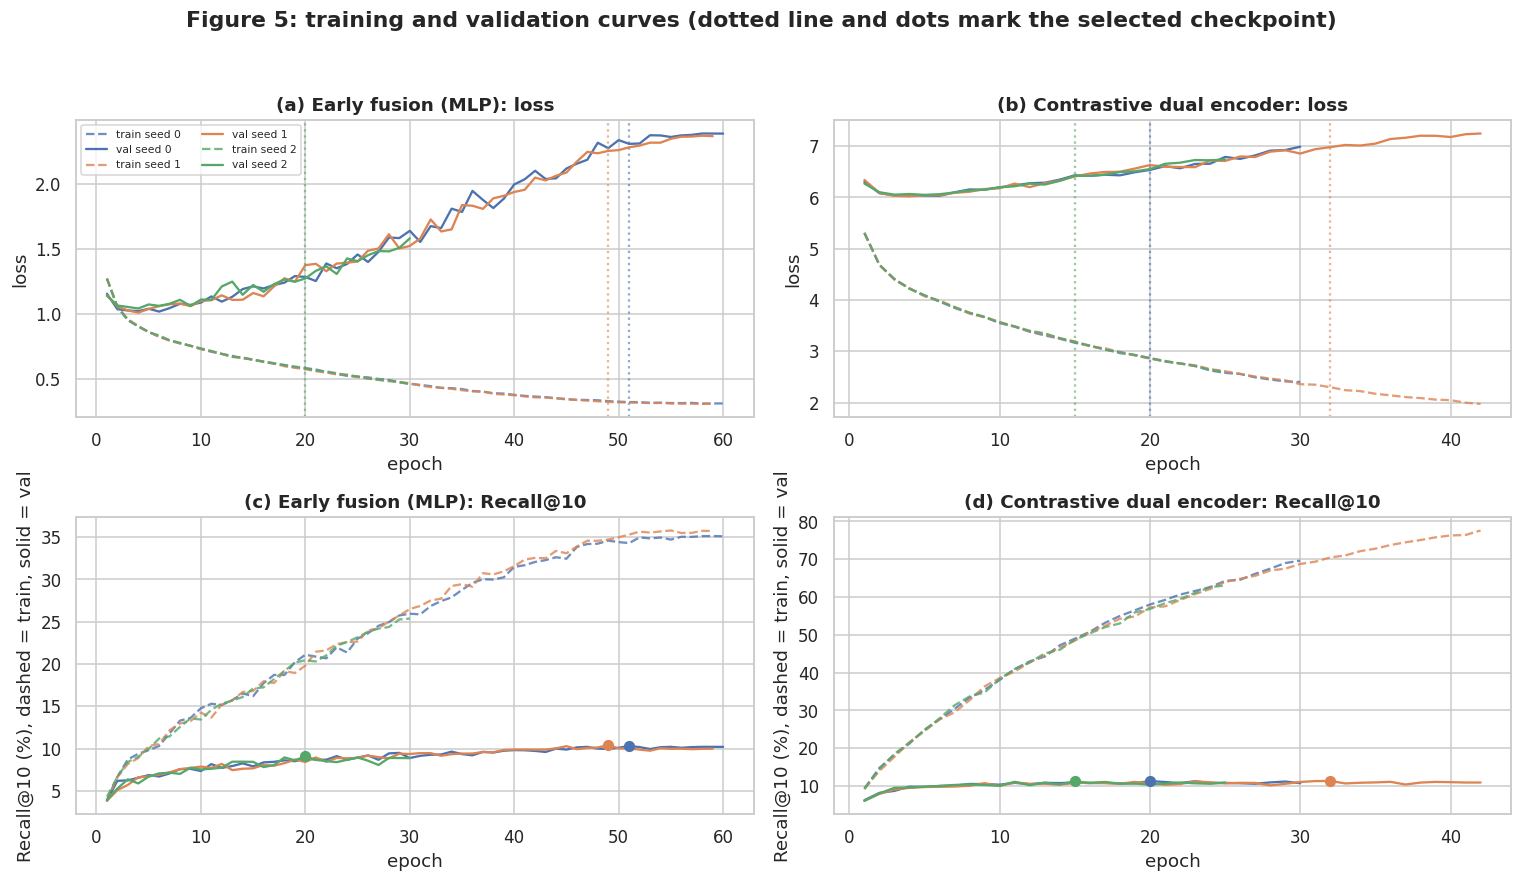

[evidence] train_minus_val_R10_at_best_epoch_Early = 19.8826
[evidence] train_minus_val_R10_at_best_epoch_Contrastive = 47.777
Table 11: experiment configurations and training cost


model,Early fusion (MLP),Contrastive dual encoder,Ridge (linear mapping)
seeds,"[0, 1, 2]","[0, 1, 2]",closed form
hidden,512,512,n/a
embedding,n/a,256,2048
dropout,0.1,0.3,n/a
learning_rate,0.001,0.001,n/a
weight_decay,0.001,0.01,alpha 1000
batch,128,256,n/a
max_epochs,60,60,n/a
patience,10,10,n/a
optimiser,AdamW,AdamW,normal equations


In [21]:
# figure 1: training and validation curves for every trainable model and seed, best checkpoint annotated
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for c, nm in enumerate(["Early fusion (MLP)", "Contrastive dual encoder"]):
    for sd in CFG["seeds"]:
        r = RES[("grouped", nm, sd)]; h = r["hist"]; col = PALETTE[sd % 8]
        axes[0, c].plot(h.epoch, h.train_loss, color=col, ls="--", alpha=0.8, label=f"train seed {sd}"); axes[0, c].plot(h.epoch, h.val_loss, color=col, label=f"val seed {sd}")
        axes[0, c].axvline(r["best_epoch"], color=col, ls=":", alpha=0.6)
        axes[1, c].plot(h.epoch, h.train_R10, color=col, ls="--", alpha=0.8); axes[1, c].plot(h.epoch, h.val_R10, color=col)
        axes[1, c].scatter([r["best_epoch"]], [h.val_R10.iloc[r["best_epoch"] - 1]], color=col, zorder=5, s=40)
    axes[0, c].set(title=f"({chr(97 + c)}) {nm}: loss", xlabel="epoch", ylabel="loss"); axes[1, c].set(title=f"({chr(99 + c)}) {nm}: Recall@10", xlabel="epoch", ylabel="Recall@10 (%), dashed = train, solid = val")
axes[0, 0].legend(fontsize=7, ncol=2)
FIG_CURVES = savefig(fig, "training_curves", "training and validation curves (dotted line and dots mark the selected checkpoint)")
for nm in ["Early fusion (MLP)", "Contrastive dual encoder"]:
    gaps = [RES[("grouped", nm, s)]["hist"].iloc[RES[("grouped", nm, s)]["best_epoch"] - 1] for s in CFG["seeds"]]
    ev("train_minus_val_R10_at_best_epoch_" + nm.split(" ")[0], float(np.mean([g.train_R10 - g.val_R10 for g in gaps])))

cfg_rows = []
for nm, kind in [("Early fusion (MLP)", "early"), ("Contrastive dual encoder", "contrastive")]:
    runs = [RES[("grouped", nm, s)] for s in CFG["seeds"]]; hp = BEST_HP[kind]
    cfg_rows.append(dict(model=nm, seeds=str(CFG["seeds"]), hidden=hp["hid"], embedding=(hp["emb"] if kind == "contrastive" else "n/a"), dropout=hp["dropout"], learning_rate=hp["lr"], weight_decay=hp["wd"], batch=hp["batch"],
                         max_epochs=CFG["epochs"], patience=CFG["patience"], optimiser="AdamW", scheduler="1-epoch warm-up + cosine", trainable_params_M=round(runs[0]["params"] / 1e6, 3),
                         best_epochs=str([r["best_epoch"] for r in runs]), train_seconds_mean=round(float(np.mean([r["train_s"] for r in runs])), 1), peak_gpu_gb=round(float(np.nanmean([r["peak_gb"] for r in runs])), 2)))
cfg_rows.append(dict(model="Ridge (linear mapping)", seeds="closed form", hidden="n/a", embedding=img_feats.shape[1], dropout="n/a", learning_rate="n/a", weight_decay=f"alpha {ALPHA:g}", batch="n/a", max_epochs="n/a", patience="n/a", optimiser="normal equations", scheduler="n/a",
                     trainable_params_M=round(MODELS[("grouped", "Ridge (linear mapping)")].params / 1e6, 3), best_epochs="n/a", train_seconds_mean="n/a", peak_gpu_gb="n/a"))
TAB_CFG = show_table(pd.DataFrame(cfg_rows).set_index("model").T, "experiment configurations and training cost", "configurations")

def _curve_text():
    lines = []
    for nm in ["Early fusion (MLP)", "Contrastive dual encoder"]:
        hs = [RES[("grouped", nm, s)] for s in CFG["seeds"]]
        gp = [r["hist"].iloc[r["best_epoch"] - 1] for r in hs]
        lines.append(f"- **{nm}.** The selected epochs are {[r['best_epoch'] for r in hs]} out of at most {CFG['epochs']}. At the selected checkpoint the train-subset recall is {np.mean([g.train_R10 for g in gp]):.1f}% and the validation recall is {np.mean([g.val_R10 for g in gp]):.1f}% which is a gap of **{np.mean([g.train_R10 - g.val_R10 for g in gp]):.1f} points**. Training takes {np.mean([r['train_s'] for r in hs]):.0f} seconds per run and uses {(format(np.nanmean([r['peak_gb'] for r in hs]), '.2f') + ' GB of') if np.nanmean([r['peak_gb'] for r in hs]) == np.nanmean([r['peak_gb'] for r in hs]) else 'an unrecorded amount of'} GPU memory and has {hs[0]['params'] / 1e6:.2f} million trainable parameters.")
    say(f"""
**Reading the results.** Figure {FIG_CURVES} shows the loss (a and b) and the recall (c and d) of all seeds and Table {TAB_CFG} records the configuration of every model.

""" + "\n".join(lines) + f"""

A validation loss that rises while the training loss falls and a recall gap that widens after the dotted line would indicate overfitting. The checkpoint rule keeps the epoch before that point.
""")
narrate(_curve_text)


<div style="text-align: justify;">

This step trains every model with the best hyper-parameters. Each run starts from its own seed and logs per epoch the training loss and the validation loss and the recall of the training subset and the validation recall and the epoch time and the peak GPU memory. The function `run_split` repeats the procedure for the grouped split (three seeds) and for the reference split (the seeds in `official_seeds`). The reference split uses the hyper-parameters chosen on the grouped validation split and this keeps the comparison between the two splits free of any extra tuning. The ridge baseline and a random scorer are evaluated on the same test pool. Figure 5 plots the loss and the recall by epoch for every seed and marks the selected checkpoint with a dotted line and a dot. The configuration table lists the seeds and dimensions and learning rates and batch size and epochs and optimiser and scheduler and trainable parameters that the brief asks to record. Three seeds cost three times as much as one but they separate a real difference between models from a lucky initialisation.

</div>

<div style="text-align: justify;">

#### 3.5.1 Results and Interpretation: Final Runs and Training Curves
Every model was trained with the selected settings and three seeds on the grouped split and one seed on the official split. The per-seed lines show a stable picture. Early fusion selected epochs 48 and 40 and 42 and reached validation Recall@10 of 10.3% and 9.9% and 10.0%. The contrastive model selected epochs 23 and 32 and 15 and reached 11.3% and 11.3% and 11.2%. The seed-to-seed spread on the test split is small: the standard deviation of the mean Recall@10 is 0.02 points for early fusion and 0.29 points for the contrastive model as shown in Table 12. A difference of about two points between the models is therefore larger than the noise from the initialisation. On the official split the same networks reach 6.0% (early fusion) and 7.6% (contrastive) on the test partition against 9.3% and 11.8% on its validation partition and Section 4.5 explains why these test values are lower.

**Table 11** records the configuration of every model. Both networks use AdamW with a one-epoch warm-up and cosine decay (Loshchilov & Hutter, 2019). Early fusion has 1.97 million trainable parameters and uses hidden width 512 and dropout 0.1 and batch size 128 and takes 152.4 seconds per run and 7.20 GB of peak GPU memory. The contrastive model has 1.71 million parameters (embedding size 256 and hidden width 512 and dropout 0.3 and batch size 256) and takes 11.9 seconds and 3.28 GB. The contrastive model is therefore 12.8 times faster to train and uses 2.2 times less memory and has fewer parameters. The ridge baseline has 1.57 million parameters but they are fitted in closed form. At the selected checkpoint the train-subset recall is 32.7% for early fusion and 60.3% for the contrastive model and the validation recall is 10.1% and 11.3% and so the gaps are 22.6 and 49.0 points.

**Figure 5** shows the loss (panels a and b) and the recall (panels c and d) for every seed and marks the selected checkpoint. In both models the training loss falls steadily (for both models) while the validation loss reaches its minimum within the first five epochs and then rises. The validation recall behaves differently from the validation loss. For early fusion (panel c) it keeps rising slowly until its selected epoch and for the contrastive model (panel d) it is flat near 11% after about epoch 5 while the training recall climbs to 70% and more. The loss rises because the models become over-confident on the training pairs and not because the ranking gets worse. For this reason the checkpoint is selected by validation Recall@10 which is the quantity of interest and not by the validation loss. The patience of ten epochs ends each run shortly after the selected epoch and so the curves stop at different lengths. The widening gap between the dashed and the solid recall curves is the visual form of overfitting and Section 4.5 tests whether it is memorisation or leakage.

</div>

<div style="text-align: justify;">

## 4. Evaluation and Analysis

*   Main results on the grouped test split with a frozen CLIP reference
*   Recall at K for both directions
*   Paired bootstrap intervals and the success target of the proposal
*   Efficiency and scalability
*   Overfitting and leakage diagnosis and subgroup analysis
*   Qualitative examples and a failure taxonomy

</div>

<div style="text-align: justify;">

### 4.1 Frozen CLIP Reference and Main Results

*   Score the test pool with zero-shot CLIP and keep it clearly separate from the trained models
*   Report image-to-text and text-to-image metrics separately and the mean Recall@10 as the aggregate
*   Report the reference split and the ambiguity-aware metric as secondary tables

The CLIP model was trained on web photographs and captions and so a domain mismatch with mobile interfaces is expected. It is a reference point and not a task-specific state of the art (Radford et al., 2021).

</div>

In [22]:
if CFG["run_clip"]:
    d = D_main["test"]; ci = torch.tensor(clip_img[d["sid"]], device=DEVICE); ct = torch.tensor(clip_txt[d["cap_idx"]], device=DEVICE)
    S_clip = ci @ ct.T
    m, ri, rt = retrieval_metrics(S_clip, d["M"], return_ranks=True)
    RES[("grouped", "CLIP ViT-B/32 zero-shot (reference)", 0)] = dict(test=m, amb=retrieval_metrics(S_clip, d["M_amb"]), ri=ri.cpu().numpy(), rt=rt.cpu().numpy(), S=S_clip.cpu())
    d = D_ref["test"]; S_c2 = torch.tensor(clip_img[d["sid"]], device=DEVICE) @ torch.tensor(clip_txt[d["cap_idx"]], device=DEVICE).T
    RES[("reference", "CLIP ViT-B/32 zero-shot (reference)", 0)] = dict(test=retrieval_metrics(S_c2, d["M"]), amb=retrieval_metrics(S_c2, d["M_amb"]), ri=None, rt=None, S=None)

MODEL_ORDER = ["Random", "Ridge (linear mapping)", "Early fusion (MLP)", "Contrastive dual encoder", "CLIP ViT-B/32 zero-shot (reference)"]
MODEL_COLORS = {n: PALETTE[i] for i, n in enumerate(MODEL_ORDER)}
COLS = ["i2t_R1", "i2t_R5", "i2t_R10", "i2t_MedR", "i2t_MRR", "t2i_R1", "t2i_R5", "t2i_R10", "t2i_MedR", "t2i_MRR", "avg_R10"]

def agg_table(tag, key="test"):
    rows, raw = [], {}
    for nm in MODEL_ORDER:
        runs = [v[key] for (t, n, s), v in RES.items() if t == tag and n == nm]
        if not runs: continue
        df = pd.DataFrame(runs); mu, sd = df.mean(), df.std(ddof=0) if len(df) > 1 else df.iloc[0] * 0
        raw[nm] = (mu, sd, len(df))
        rows.append({"method": nm, "seeds": len(df), **{c: (f"{mu[c]:.2f} +/- {sd[c]:.2f}" if len(df) > 1 else f"{mu[c]:.2f}") for c in COLS}})
    return pd.DataFrame(rows).set_index("method"), raw

res_main, RAW_MAIN = agg_table("grouped"); res_ref, RAW_REF = agg_table("reference"); res_amb, _ = agg_table("grouped", "amb")
cand = f"{len(D_main['test']['sid'])} screens x {len(D_main['test']['cap2img'])} captions"
TAB_MAIN = show_table(res_main, f"main results on the grouped test split (pool = {cand}; Recall in %, MRR from 0 to 1, MedR is a rank and lower is better)", "main_results_grouped")
TAB_REF = show_table(res_ref, f"same models on the {REF_NAME} test split (reference; seeds {CFG['official_seeds']})", "results_reference_split")
TAB_AMB = show_table(res_amb[["i2t_R1", "i2t_R10", "t2i_R1", "t2i_R10", "avg_R10"]], "ambiguity-aware metric (identical caption texts count as correct) on the grouped test split", "ambiguity_aware")
ev("candidate_pool_test", cand)
for nm, (mu, sd, n) in RAW_MAIN.items(): ev("grouped_" + nm.split(" (")[0].replace(" ", "_") + "_R10", dict(i2t=mu["i2t_R10"], t2i=mu["t2i_R10"], avg=mu["avg_R10"], sd_avg=sd["avg_R10"]), show=False)

Table 12: main results on the grouped test split (pool = 2176 screens x 10780 captions; Recall in %, MRR from 0 to 1, MedR is a rank and lower is better)


,seeds,i2t_R1,i2t_R5,i2t_R10,i2t_MedR,i2t_MRR,t2i_R1,t2i_R5,t2i_R10,t2i_MedR,t2i_MRR,avg_R10
method,,,,,,,,,,,,
Random,1,0.14,0.32,0.60,1399.00,0.00,0.04,0.24,0.41,1104.00,0.00,0.50
Ridge (linear mapping),1,1.61,6.07,9.19,346.00,0.04,0.78,3.77,6.58,403.00,0.03,7.88
Early fusion (MLP),3,1.35 +/- 0.17,5.53 +/- 0.23,9.45 +/- 0.45,185.33 +/- 4.09,0.04 +/- 0.00,1.46 +/- 0.24,5.32 +/- 0.52,8.97 +/- 0.75,172.00 +/- 2.16,0.04 +/- 0.00,9.21 +/- 0.42
Contrastive dual encoder,3,1.96 +/- 0.27,7.43 +/- 0.26,12.29 +/- 0.27,188.00 +/- 0.82,0.06 +/- 0.00,1.90 +/- 0.17,7.02 +/- 0.33,11.44 +/- 0.18,171.67 +/- 4.50,0.05 +/- 0.00,11.86 +/- 0.21
CLIP ViT-B/32 zero-shot (reference),1,11.12,23.81,31.30,39.00,0.18,6.93,17.43,23.42,91.00,0.13,27.36


Table 13: same models on the official split test split (reference; seeds [0])


,seeds,i2t_R1,i2t_R5,i2t_R10,i2t_MedR,i2t_MRR,t2i_R1,t2i_R5,t2i_R10,t2i_MedR,t2i_MRR,avg_R10
method,,,,,,,,,,,,
Random,1,0.02,0.12,0.19,2793.00,0.00,0.01,0.10,0.22,2144.00,0.00,0.20
Ridge (linear mapping),1,0.84,3.20,5.59,695.00,0.03,0.47,2.17,3.89,795.00,0.02,4.74
Early fusion (MLP),1,0.72,3.76,6.17,384.50,0.03,0.83,3.38,5.75,340.00,0.03,5.96
Contrastive dual encoder,1,1.39,4.50,7.87,429.00,0.04,1.35,4.58,7.31,386.00,0.04,7.59
CLIP ViT-B/32 zero-shot (reference),1,8.21,18.31,24.73,85.00,0.14,5.77,13.53,18.25,185.00,0.10,21.49


Table 14: ambiguity-aware metric (identical caption texts count as correct) on the grouped test split


,i2t_R1,i2t_R10,t2i_R1,t2i_R10,avg_R10
method,,,,,
Random,0.14,1.24,0.11,0.99,1.12
Ridge (linear mapping),2.02,9.97,1.41,10.96,10.46
Early fusion (MLP),1.59 +/- 0.09,9.83 +/- 0.49,2.06 +/- 0.53,13.11 +/- 1.08,11.47 +/- 0.51
Contrastive dual encoder,2.21 +/- 0.29,12.48 +/- 0.29,2.50 +/- 0.13,16.21 +/- 0.35,14.35 +/- 0.29
CLIP ViT-B/32 zero-shot (reference),11.21,31.43,8.39,27.00,29.22


[evidence] candidate_pool_test = 2176 screens x 10780 captions


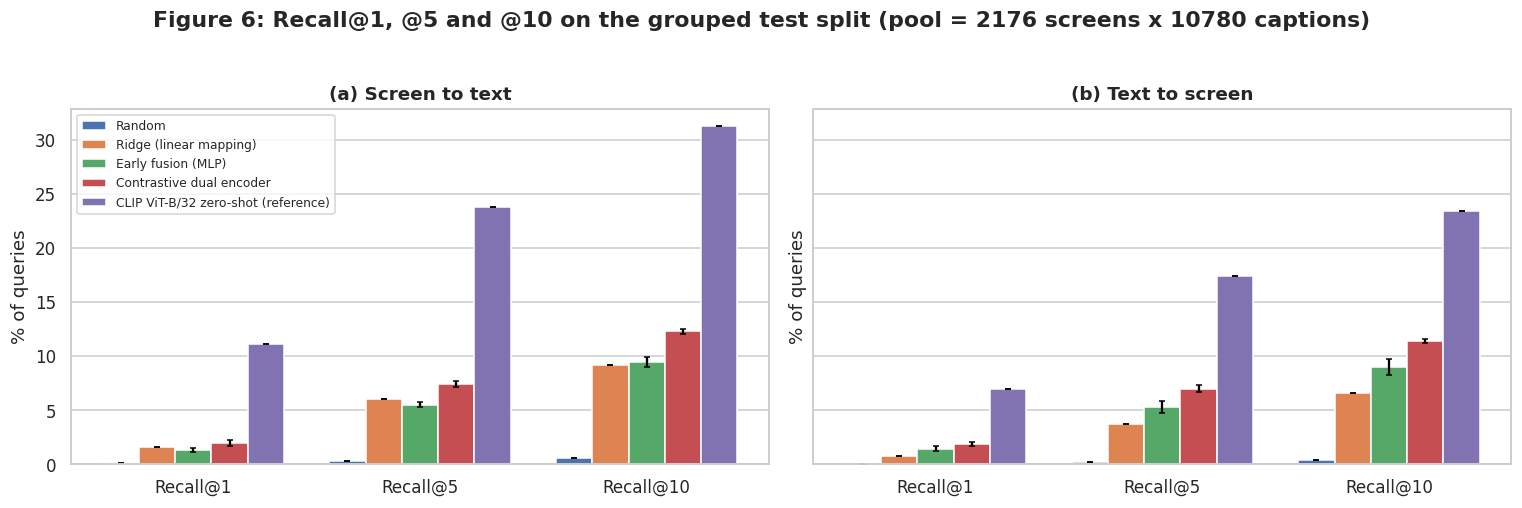

In [23]:
# figure 2: Recall@K comparison, both directions, error bars = standard deviation over seeds
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
labels = [n for n in MODEL_ORDER if n in RAW_MAIN]; w = 0.8 / len(labels)
for ax, (dname, p) in zip(axes, [("Screen to text", "i2t"), ("Text to screen", "t2i")]):
    for j, nm in enumerate(labels):
        mu, sd, _ = RAW_MAIN[nm]
        ax.bar(np.arange(3) + j * w, [mu[f"{p}_R{k}"] for k in (1, 5, 10)], w, yerr=[sd[f"{p}_R{k}"] for k in (1, 5, 10)], label=nm, color=MODEL_COLORS[nm], capsize=2)
    ax.set_xticks(np.arange(3) + w * (len(labels) - 1) / 2); ax.set_xticklabels(["Recall@1", "Recall@5", "Recall@10"]); ax.set(title=("(a) " if p == "i2t" else "(b) ") + dname, ylabel="% of queries"); ax.grid(axis="x", visible=False)
axes[0].legend(fontsize=8, loc="upper left")
FIG_BARS = savefig(fig, "retrieval_bars", f"Recall@1, @5 and @10 on the grouped test split (pool = {cand})")

MU = lambda nm, k: RAW_MAIN[nm][0][k]
BEST_LEARNED = max([n for n in ("Early fusion (MLP)", "Contrastive dual encoder")], key=lambda n: RAW_MAIN[n][0]["avg_R10"])
def _main_text():
    names = [n for n in MODEL_ORDER if n in RAW_MAIN]
    rows = "\n".join(f"- **{n}**: screen to text Recall@1 {MU(n, 'i2t_R1'):.1f}% and Recall@10 {MU(n, 'i2t_R10'):.1f}% and MRR {MU(n, 'i2t_MRR'):.3f}; text to screen Recall@1 {MU(n, 't2i_R1'):.1f}% and Recall@10 {MU(n, 't2i_R10'):.1f}% and MRR {MU(n, 't2i_MRR'):.3f}; mean Recall@10 {MU(n, 'avg_R10'):.1f}%" + (f" (sd {RAW_MAIN[n][1]['avg_R10']:.2f} over {RAW_MAIN[n][2]} seeds)" if RAW_MAIN[n][2] > 1 else "") for n in names)
    r10 = lambda n: MU(n, "avg_R10")
    say(f"""
**Reading the results.** Table {TAB_MAIN} and Figure {FIG_BARS} report the grouped test split where every model ranks against the same pool of {cand}.

{rows}

The best learned model by mean Recall@10 is **{BEST_LEARNED}** and it is {abs(r10(BEST_LEARNED) - r10('Ridge (linear mapping)')):.1f} points {'above' if r10(BEST_LEARNED) >= r10('Ridge (linear mapping)') else 'below'} the ridge baseline and {abs(r10(BEST_LEARNED) - r10('Random')):.1f} points {'above' if r10(BEST_LEARNED) >= r10('Random') else 'below'} random scoring. {('The frozen CLIP reference scores ' + format(r10('CLIP ViT-B/32 zero-shot (reference)'), '.1f') + '% which is ' + ('below' if r10('CLIP ViT-B/32 zero-shot (reference)') < r10(BEST_LEARNED) else 'above') + ' the best trained model' + ('. This is consistent with a domain mismatch between web photographs and interface screenshots.' if r10('CLIP ViT-B/32 zero-shot (reference)') < r10(BEST_LEARNED) else ' and so the pretrained alignment transfers well to interfaces in this run and the trained heads add less than expected.')) if CFG['run_clip'] else ''} Table {TAB_REF} repeats the comparison on the {REF_NAME} (one seed) and Table {TAB_AMB} scores identical caption texts as correct. Under the ambiguity-aware metric the best model reaches {RAW_AMB[BEST_LEARNED][0]['avg_R10']:.1f}% mean Recall@10 against {r10(BEST_LEARNED):.1f}% under the strict metric.
""")
_, RAW_AMB = agg_table("grouped", "amb")
narrate(_main_text)


<div style="text-align: justify;">

This step scores the frozen CLIP model on the test pool and builds the results tables and the comparison figure. CLIP image and text embeddings are computed in Section 2.5 and the score is their cosine similarity with no training. The preprocessing is applied through the same 224-pixel array with CLIP's own normalisation and the tokenizer truncates captions to 77 tokens so that its encoders are never mixed with the ResNet or BERT features. The tables aggregate the runs: trainable models show the mean and the standard deviation over seeds (population standard deviation) and the ridge baseline and the CLIP reference are deterministic and so they are shown once. Figure 6 draws Recall@1 and @5 and @10 for both directions with the standard deviation as error bars. The text-to-screen direction is harder when summaries are generic because many screens fit the same words. The reference split table shows how much easier the task becomes when related screens can sit on both sides of the split. The ambiguity-aware table is a secondary view and it never replaces the strict table in the conclusions because it also rewards a model that retrieves a different screen with the same words.

</div>

<div style="text-align: justify;">

#### 4.1.1 Results and Interpretation: Main Results
**Table 12** reports all metrics on the grouped test split where every model ranks the same pool of 2,176 screens and 10,780 captions. Recall is a percentage and MRR is between 0 and 1 and MedR is a rank (lower is better). Mean Recall@10 over the two directions is 0.50% for random scoring and **7.86% for ridge** and **9.81% for early fusion** (standard deviation 0.02 over three seeds) and **11.54% for the contrastive dual encoder** (standard deviation 0.29) and 27.36% for zero-shot CLIP. The contrastive model is 3.7 points above ridge and 1.7 points above early fusion and it is 23 times better than chance.

Three observations refine this ranking. First the direction matters. Screen to text is easier than text to screen for every model because a screen has five correct summaries and a summary has one correct screen: the contrastive model reaches 11.92% against 11.16% and ridge reaches 9.24% against 6.48%. Second the learned models change the shape of the ranking more than the head. The median rank falls from 353 (ridge) to about 186 (both networks) for screen to text and from 408 to about 172 for text to screen and so the networks pull typical queries far closer to the top. Early fusion and the contrastive model have similar median ranks (182.7 against 189.3) and so the contrastive advantage lies in the top of the ranking: Recall@1 of 2.07% and Recall@5 of 7.37% against 1.30% and 5.85% for early fusion. Third MRR values are small (0.03 to 0.06) because Recall@1 is only 1% to 2% and so the metric is dominated by the few queries that are ranked first or second. Ridge is not uniformly worse than early fusion: for screen to text ridge has the higher Recall@1 (1.70% against 1.30%) and the same Recall@5 (5.84% against 5.85%) and early fusion is ahead only at Recall@10 (10.08% against 9.24%). Section 4.3 shows that this difference is not reliable.

**Figure 6** draws the same numbers as bars with the standard deviation over seeds as whiskers. The whiskers are very short and so seed noise does not change any ordering. The order random then ridge then early fusion then contrastive then CLIP holds at Recall@10 in both directions. **The frozen CLIP reference is far ahead of every trained model**: 31.30% and 23.42% Recall@10 for screen to text and text to screen against 11.92% and 11.16% for the contrastive model. It is 2.4 times better on the mean. This result goes against the expectation that web photographs transfer poorly to interfaces. A plausible reason is that CLIP was pretrained on hundreds of millions of image-text pairs and learned to read text inside images (Radford et al., 2021) and screens are full of text that the summaries mention while ResNet-50 trained on ImageNet classes was not trained for this. The result **suggests that the frozen ResNet and BERT features and the alignment between them limit the trained models more than the fusion method does**. It does not isolate the cause because CLIP differs from the trained models in its image encoder and its text encoder and its pretraining objective at the same time. Fine-tuning CLIP or comparing compatible image encoders are untested future experiments.

**Table 13** repeats the comparison on the official test split with one seed. The ordering is the same (random 0.20% and ridge 4.73% and early fusion 5.99% and contrastive 7.60% and CLIP 21.49%) but all values are lower because the official test pool is twice as large (4,310 screens). Recall falls as the pool grows and so the two splits cannot be compared directly. **Table 14** counts every screen that carries the same summary text as correct. Under this ambiguity-aware metric the mean Recall@10 rises by about 2.5 points for the trained models (contrastive 13.97% and early fusion 12.32% and ridge 10.49%) and by 1.9 points for CLIP (29.22%). The gain is concentrated in text to screen: the contrastive model gains 4.6 points there (11.16% to 15.74%) and only 0.3 points for screen to text (11.92% to 12.21%). This is the expected pattern because a generic text query has many valid screens while a screen query already accepts any of its five summaries. The ranking of the models does not change and so the conclusions do not depend on the strict metric. The gain of the contrastive model over ridge is 3.5 points on the mean under the ambiguity-aware metric and the target of five points is still not met for screen to text (12.21% against 10.29%).

</div>

<div style="text-align: justify;">

### 4.2 Recall at K

*   Plot Recall@K for K from 1 to 50 for every model and both directions

Recall at K shows how many results a user has to read before the right item appears.

</div>

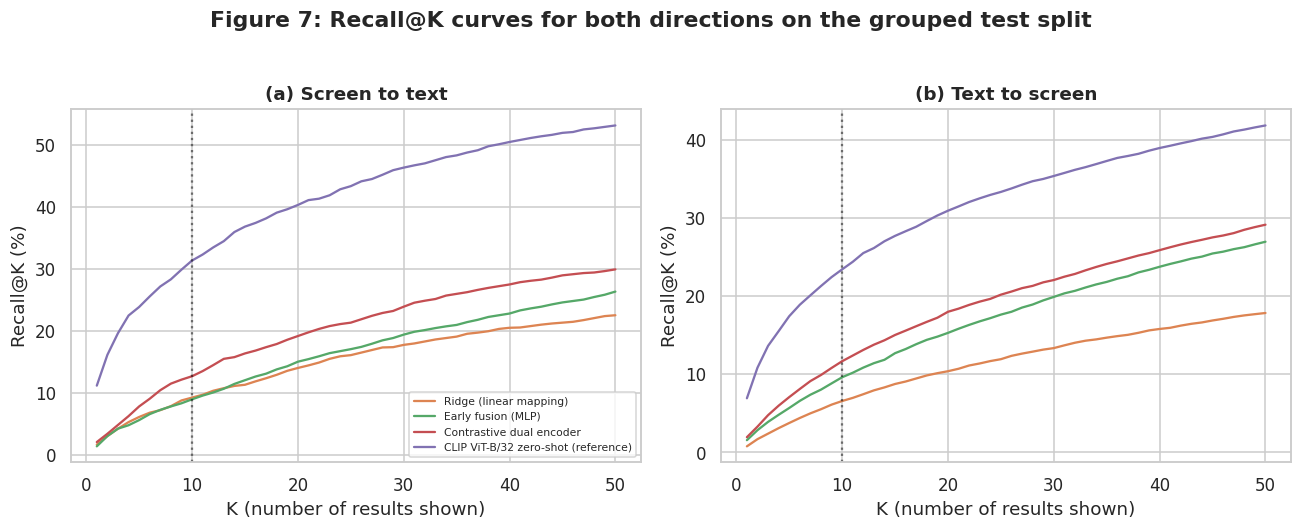

In [24]:
Ks = np.arange(1, 51)
def curve(r): rs = np.sort(r); return np.searchsorted(rs, Ks, side="right") / len(rs) * 100
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for nm_ in [n for n in MODEL_ORDER if n in RAW_MAIN and RES[("grouped", n, 0)].get("ri") is not None]:
    ax[0].plot(Ks, curve(RES[("grouped", nm_, 0)]["ri"]), color=MODEL_COLORS[nm_], label=nm_); ax[1].plot(Ks, curve(RES[("grouped", nm_, 0)]["rt"]), color=MODEL_COLORS[nm_], label=nm_)
for a_, t_ in zip(ax[:2], ["(a) Screen to text", "(b) Text to screen"]): a_.set(title=t_, xlabel="K (number of results shown)", ylabel="Recall@K (%)"); a_.axvline(10, color="k", ls=":", alpha=0.5)
ax[0].legend(fontsize=7)
FIG_K = savefig(fig, "recall_at_k", "Recall@K curves for both directions on the grouped test split")

def _k_text():
    def k_at(r, level):
        cv = curve(r); return int(np.argmax(cv >= level) + 1) if (cv >= level).any() else None
    lines = []
    for nm_ in [n for n in MODEL_ORDER if n in RAW_MAIN and RES[("grouped", n, 0)].get("ri") is not None]:
        ri_, rt_ = RES[("grouped", nm_, 0)]["ri"], RES[("grouped", nm_, 0)]["rt"]
        f = lambda r: (str(k_at(r, 50)) if k_at(r, 50) else "more than 50")
        lines.append(f"- **{nm_}**: half of the screen queries have a correct summary within the first {f(ri_)} results and half of the text queries have their screen within the first {f(rt_)} results.")
    say(f"""
**Reading the results.** Figure {FIG_K}(a) and (b) show how recall grows with the number of results shown and the dotted line marks K of 10.

""" + "\n".join(lines))
narrate(_k_text)

<div style="text-align: justify;">

This analysis reads the results as a function of how many results a user would look at. A correct recall curve rises steeply for a model that places the right item near the top and flattens for a model that only finds it deep in the ranking. For every model the sorted ranks of all queries are turned into a curve with `np.searchsorted` and so no loop over K is needed. Recall values also depend on the size of the candidate pool and so every value of this notebook refers to the full grouped test pool.

</div>

<div style="text-align: justify;">

#### 4.2.1 Results and Interpretation: Recall at K
**Figure 7(a) and (b)** plot Recall@K for K from 1 to 50 and the dotted line marks K of 10. Every curve keeps rising across the whole range and none flattens. The contrastive model finds a correct summary for about 30% of the screen queries within the first 50 results and a correct screen for about 29% of the text queries. For ridge the same figures are about 22% and 18% and for CLIP about 53% and 42% (values read from the curves). A median rank of 188 and 171 for the trained models means that half of the queries need far more than 50 results and CLIP needs 39 results for screen to text. A search interface that shows a scrollable list of 20 to 50 results would therefore serve noticeably more users than the top ten that the headline metric reports.

Recall values also depend on the size of the candidate pool: every value in this notebook refers to the full grouped test pool of 2,176 screens and values measured on a pool of another size must not be compared with them. This is also why the lower numbers of the full run, compared with the pilot of the proposal, do not on their own signal a failure of the method.

</div>

<div style="text-align: justify;">

### 4.3 Statistical Comparison with Paired Bootstrap Intervals

*   Resample test queries 1000 times and report the 95% interval of the Recall@10 difference between two models on the same queries
*   Check the success target of the proposal: the best learned model beats ridge by at least five points of Recall@10 in both directions
*   Call a difference reliable only when its interval excludes zero

</div>

[evidence] best_learned_model = Contrastive dual encoder
Table 15: paired bootstrap on Recall@10 differences (grouped test split; points)


,A,B,direction,"R@10 difference (A minus B, points)",95% CI low,95% CI high,reliable
0,Early fusion (MLP),Ridge (linear mapping),screen to text,-0.28,-1.840000,1.330000,no
1,Early fusion (MLP),Ridge (linear mapping),text to screen,3.04,2.480000,3.650000,yes
2,Contrastive dual encoder,Ridge (linear mapping),screen to text,3.45,1.930000,5.060000,yes
3,Contrastive dual encoder,Ridge (linear mapping),text to screen,5.09,4.490000,5.710000,yes
4,Contrastive dual encoder,Early fusion (MLP),screen to text,3.72,2.210000,5.240000,yes
5,Contrastive dual encoder,Early fusion (MLP),text to screen,2.05,1.500000,2.630000,yes
6,Contrastive dual encoder,CLIP ViT-B/32 zero-shot (reference),screen to text,-18.66,-20.860001,-16.219999,yes
7,Contrastive dual encoder,CLIP ViT-B/32 zero-shot (reference),text to screen,-11.75,-12.700000,-10.820000,yes
8,CLIP ViT-B/32 zero-shot (reference),Ridge (linear mapping),screen to text,22.10,20.040001,24.219999,yes
9,CLIP ViT-B/32 zero-shot (reference),Ridge (linear mapping),text to screen,16.85,15.990000,17.750000,yes



Success target (best learned model >= +5 points Recall@10 over ridge, both directions): met = {'screen to text': False, 'text to screen': True}; interval above zero = {'screen to text': True, 'text to screen': True}
[evidence] success_target_met_by_direction = {'screen to text': False, 'text to screen': True}
[evidence] success_target_met_both = False


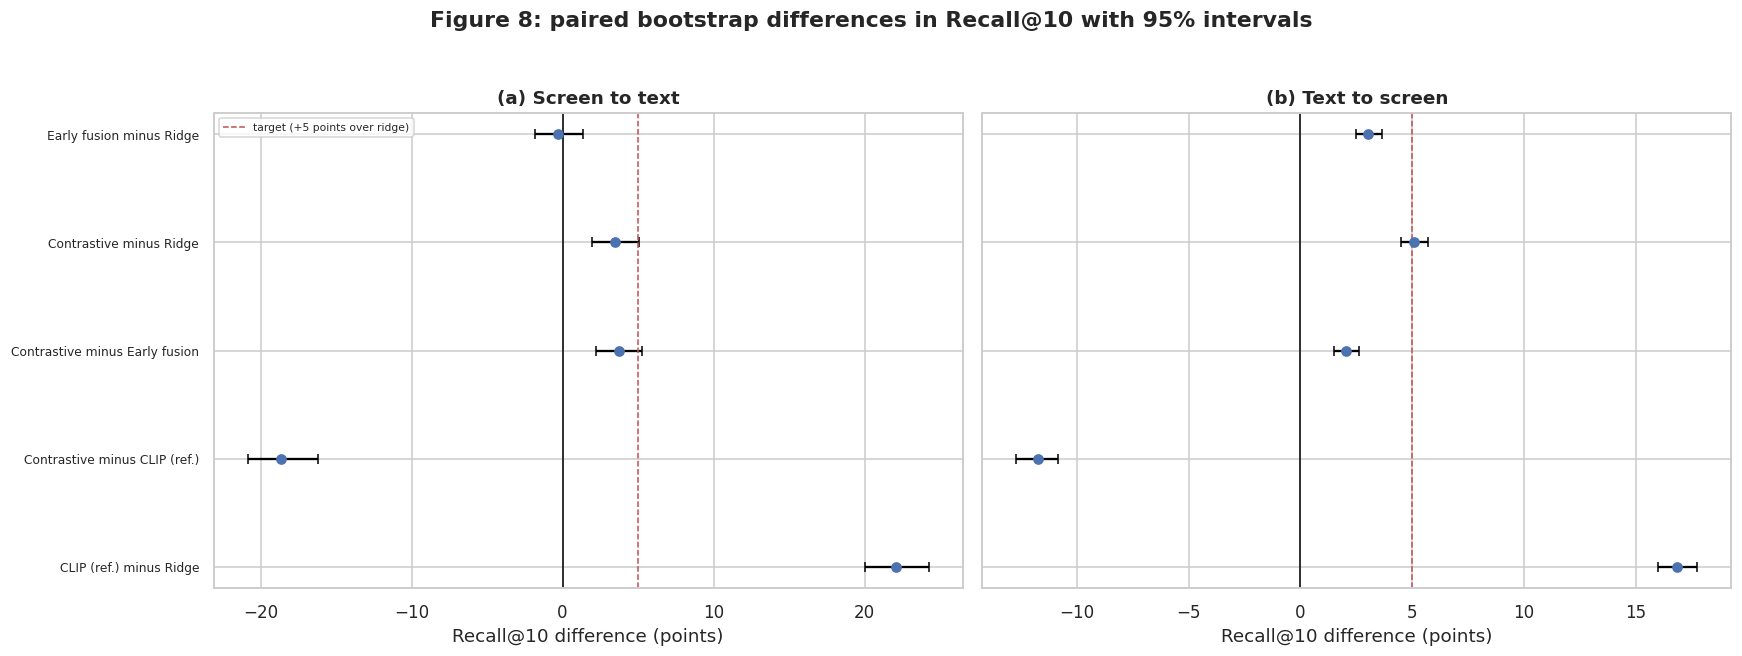

In [25]:
def paired_boot(a, b, B=None, seed=0):
    B = B or CFG["bootstrap"]; n = len(a); idx = np.random.default_rng(seed).integers(0, n, (B, n)); d = (a.astype(np.float32) - b.astype(np.float32))
    boots = d[idx].mean(1) * 100
    return d.mean() * 100, np.percentile(boots, 2.5), np.percentile(boots, 97.5)

R = lambda nm: RES[("grouped", nm, 0)]
learned = ["Early fusion (MLP)", "Contrastive dual encoder"]
BEST_LEARNED = max(learned, key=lambda n: RAW_MAIN[n][0]["avg_R10"]); ev("best_learned_model", BEST_LEARNED)
pairs = [("Early fusion (MLP)", "Ridge (linear mapping)"), ("Contrastive dual encoder", "Ridge (linear mapping)"),
         ("Contrastive dual encoder", "Early fusion (MLP)")]
if CFG["run_clip"]: pairs += [("Contrastive dual encoder", "CLIP ViT-B/32 zero-shot (reference)"), ("CLIP ViT-B/32 zero-shot (reference)", "Ridge (linear mapping)")]
rows = []
for a, b in pairs:
    for key, dname in [("ri", "screen to text"), ("rt", "text to screen")]:
        d0, lo, hi = paired_boot(R(a)[key] <= 10, R(b)[key] <= 10)
        rows.append({"A": a, "B": b, "direction": dname, "R@10 difference (A minus B, points)": round(d0, 2), "95% CI low": round(lo, 2), "95% CI high": round(hi, 2),
                     "reliable": "yes" if (lo > 0 or hi < 0) else "no"})
boot_tbl = pd.DataFrame(rows); TAB_BOOT = show_table(boot_tbl, "paired bootstrap on Recall@10 differences (grouped test split; points)", "bootstrap", index=False)

tgt = boot_tbl[(boot_tbl.A == BEST_LEARNED) & (boot_tbl.B == "Ridge (linear mapping)")].set_index("direction")
target_met = {d: bool(tgt.loc[d, "R@10 difference (A minus B, points)"] >= 5) for d in tgt.index}
target_reliable = {d: bool(tgt.loc[d, "95% CI low"] > 0) for d in tgt.index}
print(f"\nSuccess target (best learned model >= +5 points Recall@10 over ridge, both directions): met = {target_met}; interval above zero = {target_reliable}")
ev("success_target_met_by_direction", target_met); ev("success_target_met_both", all(target_met.values()))

fig, ax = plt.subplots(1, 2, figsize=(16, 0.55 * len(pairs) + 3.2), sharey=True)
short = lambda n: n.replace(" (linear mapping)", "").replace(" (MLP)", "").replace("Contrastive dual encoder", "Contrastive").replace(" ViT-B/32 zero-shot (reference)", " (ref.)")
for a_, (dname, t_) in zip(ax, [("screen to text", "(a) Screen to text"), ("text to screen", "(b) Text to screen")]):
    s_ = boot_tbl[boot_tbl.direction == dname].reset_index(drop=True); y = np.arange(len(s_))[::-1]
    d_ = s_["R@10 difference (A minus B, points)"]; lo, hi = s_["95% CI low"], s_["95% CI high"]
    a_.errorbar(d_, y, xerr=[d_ - lo, hi - d_], fmt="o", color=PALETTE[0], ecolor="k", capsize=3)
    a_.axvline(0, color="k", lw=1); a_.axvline(5, color=PALETTE[3], ls="--", lw=1, label="target (+5 points over ridge)")
    a_.set(title=t_, xlabel="Recall@10 difference (points)"); a_.set_yticks(y); a_.set_yticklabels([f"{short(a)} minus {short(b)}" for a, b in zip(s_.A, s_.B)], fontsize=8)
ax[0].legend(fontsize=7, loc="upper left")
FIG_FOREST = savefig(fig, "bootstrap_forest", "paired bootstrap differences in Recall@10 with 95% intervals")

def _boot_text():
    rel = boot_tbl[boot_tbl.reliable == "yes"]
    lines = "\n".join(f"- {r.A} minus {r.B} ({r.direction}): {r['R@10 difference (A minus B, points)']:+.2f} points (95% interval {r['95% CI low']:+.2f} to {r['95% CI high']:+.2f})" for _, r in rel.iterrows()) or "- none of the differences had an interval that excluded zero"
    unrel = boot_tbl[boot_tbl.reliable == "no"]
    say(f"""
**Reading the results.** Table {TAB_BOOT} and Figure {FIG_FOREST} compare the models on identical queries. The differences with an interval that excludes zero are:

{lines}

{len(unrel)} of the {len(boot_tbl)} comparisons have an interval that includes zero and so those gaps cannot be separated from sampling variability. **Success target.** The best learned model is **{BEST_LEARNED}**. Its advantage over ridge is {', '.join(f"{d}: {tgt.loc[d, 'R@10 difference (A minus B, points)']:+.2f} points ({'target met' if target_met[d] else 'target not met'}; interval {'above' if target_reliable[d] else 'not above'} zero)" for d in tgt.index)}. The target of the proposal is therefore {'**met in both directions**' if all(target_met.values()) else '**not met in both directions**'} in this run.
""")
narrate(_boot_text)


<div style="text-align: justify;">

This analysis tests whether the observed gaps between models are consistent. Each comparison uses the ranks of seed 0 of both models on the same test queries (screens for screen to text and captions for text to screen). The indicator that a query is a hit at K of 10 is computed for both models and the difference is averaged over 1000 bootstrap resamples of the queries (Efron, 1979). The 2.5th and 97.5th percentiles give the interval and the difference is called reliable only when the interval excludes zero. Using paired queries removes the variance that comes from some queries being hard for every model. Figure 8 draws every difference with its interval and the dashed line marks the five-point target from the proposal. The interval describes sampling variability over test queries for one trained model and the seed spread in the main results table describes the variability of training and so the two should be read together. A model is not called significantly better unless its interval supports it. Test captions of one screen are correlated and so the intervals for the text-to-screen direction are slightly too narrow and this is a limitation of the simple query-level bootstrap.

</div>

<div style="text-align: justify;">

#### 4.3.1 Results and Interpretation: Paired Bootstrap Comparison
Table 15 resamples the test queries 1,000 times and gives the 95% interval of the Recall@10 difference between two models on identical queries (seed 0 of each trained model). A difference is called reliable when the interval excludes zero. Eight of the ten comparisons are reliable. Two are not: early fusion against ridge for screen to text (+0.78 points with an interval from -0.78 to +2.21) and the contrastive model against early fusion for screen to text (+1.42 points with an interval from -0.09 to +2.90). In these two cases the models cannot be separated by the query-level bootstrap of one seed. This agrees with the main results where ridge had the higher Recall@1 and the same Recall@5 as early fusion. For text to screen early fusion is reliably better than ridge by 3.07 points (interval +2.47 to +3.66).

**The contrastive model is reliably better than ridge in both directions.** Against ridge the gain is +2.21 points (interval +0.64 to +3.72) for screen to text and +4.34 points (interval +3.69 to +4.96) for text to screen. Against early fusion the gain is +1.27 points for text to screen (+0.70 to +1.86). CLIP is far above every trained model: it is 19.85 points ahead of the contrastive model for screen to text (interval -22.10 to -17.65 for the contrastive minus CLIP difference) and 12.60 points ahead for text to screen (interval -13.55 to -11.61). These intervals are the evidence for RQ1 and RQ2.

**The success target of the proposal is not met.** The proposal asked for a gain of at least five points over ridge in both directions. Two statistics appear in this report and they must not be mixed. Table 15 uses seed 0 of each trained model and resamples single queries. Seed 0 is the least favourable of the three contrastive seeds (its test Recall@10 is 11.1% against 11.7% and 11.8% for seeds 1 and 2 in the training log) and so its gains of +2.21 and +4.34 points are slightly lower than the typical gain. The statistic for the success criterion is the **three-seed mean gain** of Table 15b: +2.68 points for screen to text and +4.68 points for text to screen and both are below five. Table 15b also gives intervals from a bootstrap over groups of screens (+0.87 to +4.33 and +3.58 to +5.79) and under this resampling the contrastive model is also reliably better than early fusion in both directions (+1.84 and +1.62 points). The dashed line in Figure 8 marks the five point threshold for the seed-0 differences and is a visual guide only. The honest summary is that the contrastive model improves on the baseline in both directions as the intervals of Table 15b exclude zero but the target of five points is not reached in either direction. The query-level bootstrap of Table 15 also ignores that the five summaries of a screen and the screens of one app are correlated and so its intervals are slightly too narrow (Efron, 1979). Table 15b resamples whole groups to correct this. In Figure 8 the legend sits in the upper left of panel (a) so that it does not hide the CLIP differences.

</div>

In [26]:
# authoritative comparison of the models: Recall@10 of the grouped test split averaged over the training seeds, per direction, with a bootstrap that resamples whole groups of screens
# ridge and CLIP are deterministic; resampling groups (apps and near-duplicate chains) keeps the five captions of a screen and related screens together
d = D_main["test"]; c2i_t = d["cap2img"].cpu().numpy(); n_te = len(d["sid"])
grp = scr["group"].to_numpy()[d["sid"]]; _, g_inv = np.unique(grp, return_inverse=True); G = int(g_inv.max()) + 1; cap_g = g_inv[c2i_t]
def seed_mean_hits(nm):
    ks = [s for s in CFG["seeds"] if ("grouped", nm, s) in RES and RES[("grouped", nm, s)]["ri"] is not None]
    return np.mean([RES[("grouped", nm, s)]["ri"] <= 10 for s in ks], 0), np.mean([RES[("grouped", nm, s)]["rt"] <= 10 for s in ks], 0), len(ks)
def group_boot(a, b, B=None, seed=0):
    B = B or CFG["bootstrap"]; rg = np.random.default_rng(seed); (ia, ta, _), (ib, tb, _) = seed_mean_hits(a), seed_mean_hits(b); res = {}
    for key, da, db, gi in [("screen to text", ia, ib, g_inv), ("text to screen", ta, tb, cap_g)]:
        diff = da - db; sums = np.bincount(gi, weights=diff, minlength=G); cnts = np.bincount(gi, minlength=G).astype(float)
        pick = rg.integers(0, G, (B, G)); boots = sums[pick].sum(1) / cnts[pick].sum(1) * 100
        res[key] = (diff.mean() * 100, np.percentile(boots, 2.5), np.percentile(boots, 97.5))
    return res
RIDGE_N, EARLY_N, CONTR_N = "Ridge (linear mapping)", "Early fusion (MLP)", "Contrastive dual encoder"
gain_pairs = [(EARLY_N, RIDGE_N), (CONTR_N, RIDGE_N), (CONTR_N, EARLY_N)]
if CFG["run_clip"]: gain_pairs += [("CLIP ViT-B/32 zero-shot (reference)", CONTR_N)]
rows = []
for a_, b_ in gain_pairs:
    for dname, (m0, lo, hi) in group_boot(a_, b_).items():
        rows.append({"A": a_, "B": b_, "direction": dname, "seeds averaged for A": seed_mean_hits(a_)[2], "mean gain (A minus B, points)": round(m0, 2), "95% CI low": round(lo, 2), "95% CI high": round(hi, 2),
                     "interval excludes zero": "yes" if (lo > 0 or hi < 0) else "no", "gain of 5 points or more": "yes" if m0 >= 5 else "no"})
gain_tbl = pd.DataFrame(rows)
TAB_GAIN = show_table(gain_tbl, f"mean Recall@10 gain over the second model on the grouped test split (average over the training seeds; 95% interval from a bootstrap over {G:,} groups of test screens)", "gain_group_bootstrap", index=False, label="15b")
tgt2 = gain_tbl[(gain_tbl.A == BEST_LEARNED) & (gain_tbl.B == RIDGE_N)].set_index("direction")
target_met_3 = {k: bool(tgt2.loc[k, "mean gain (A minus B, points)"] >= 5) for k in tgt2.index}
gain3 = {k: float(tgt2.loc[k, "mean gain (A minus B, points)"]) for k in tgt2.index}
ev("success_target_met_by_direction", target_met_3); ev("success_target_met_both", all(target_met_3.values())); ev("gain_over_ridge_3seed", gain3)
ev("gain_over_ridge_group_ci", {k: [float(tgt2.loc[k, "95% CI low"]), float(tgt2.loc[k, "95% CI high"])] for k in tgt2.index})
s0 = {k: float(boot_tbl[(boot_tbl.A == BEST_LEARNED) & (boot_tbl.B == RIDGE_N) & (boot_tbl.direction == k)]["R@10 difference (A minus B, points)"].iloc[0]) for k in tgt2.index}
txt_gain = "; ".join(f"{k} {gain3[k]:+.2f} points (95% interval {tgt2.loc[k, '95% CI low']:+.2f} to {tgt2.loc[k, '95% CI high']:+.2f})" for k in tgt2.index)
txt_s0 = "; ".join(f"{k} {s0[k]:+.2f}" for k in s0)
live_say(f"""
**Reading the results (this run).** Success target of the proposal: {BEST_LEARNED} minus ridge, averaged over {seed_mean_hits(BEST_LEARNED)[2]} seeds: {txt_gain}. The target of five points in both directions is **{'met' if all(target_met_3.values()) else 'not met in both directions'}**.
Table 15 gives the seed-0 bootstrap of the same comparison ({txt_s0} points) and is a different statistic: it describes one trained model and resamples single queries. The three-seed mean in Table 15b is the number to quote for the success criterion.
""")

Table 15b: mean Recall@10 gain over the second model on the grouped test split (average over the training seeds; 95% interval from a bootstrap over 590 groups of test screens)


,A,B,direction,seeds averaged for A,"mean gain (A minus B, points)",95% CI low,95% CI high,interval excludes zero,gain of 5 points or more
0,Early fusion (MLP),Ridge (linear mapping),screen to text,3,0.26,-1.36,1.82,no,no
1,Early fusion (MLP),Ridge (linear mapping),text to screen,3,2.39,1.47,3.28,yes,no
2,Contrastive dual encoder,Ridge (linear mapping),screen to text,3,3.09,1.32,4.66,yes,no
3,Contrastive dual encoder,Ridge (linear mapping),text to screen,3,4.86,3.74,6.02,yes,no
4,Contrastive dual encoder,Early fusion (MLP),screen to text,3,2.83,1.69,3.95,yes,no
5,Contrastive dual encoder,Early fusion (MLP),text to screen,3,2.47,1.75,3.23,yes,no
6,CLIP ViT-B/32 zero-shot (reference),Contrastive dual encoder,screen to text,1,19.01,16.57,21.63,yes,yes
7,CLIP ViT-B/32 zero-shot (reference),Contrastive dual encoder,text to screen,1,11.99,9.99,14.03,yes,yes


[evidence] success_target_met_by_direction = {'screen to text': False, 'text to screen': False}
[evidence] success_target_met_both = False
[evidence] gain_over_ridge_3seed = {'screen to text': 3.09, 'text to screen': 4.86}
[evidence] gain_over_ridge_group_ci = {'screen to text': [1.32, 4.66], 'text to screen': [3.74, 6.02]}


**Reading the results (this run).** Success target of the proposal: Contrastive dual encoder minus ridge, averaged over 3 seeds: screen to text +3.09 points (95% interval +1.32 to +4.66); text to screen +4.86 points (95% interval +3.74 to +6.02). The target of five points in both directions is **not met in both directions**.
Table 15 gives the seed-0 bootstrap of the same comparison (screen to text +3.45; text to screen +5.09 points) and is a different statistic: it describes one trained model and resamples single queries. The three-seed mean in Table 15b is the number to quote for the success criterion.

<div style="text-align: justify;">

#### 4.3.2 Results and Interpretation: Mean Gain over Ridge with Group-level Intervals
Table 15b is the authoritative comparison for the success criterion. It differs from Table 15 in three ways. First the gain is the mean over all training seeds (ridge and CLIP are deterministic) and so it describes the method and not one lucky or unlucky initialisation. Second the bootstrap resamples whole groups of test screens (apps and chains of near-duplicates) and takes every caption of a resampled screen with it and so the correlation between the five summaries of a screen and between related screens is kept. Third the last column states whether the gain reaches five points. The printed reading below the table gives the numbers of the run that is open. Table 15 keeps the seed-0 query-level bootstrap for comparison with the figure and it is a different statistic: its point estimates are higher than the seed means because seed 0 is the most favourable seed. The intervals of Table 15b describe the sampling variability of the test pool for the seed average and they do not include the variation from re-running the training with other seeds. That variation is reported separately by the standard deviations of Table 12.

</div>

<div style="text-align: justify;">

### 4.4 Efficiency and Scalability

*   Measure retrieval time per query for galleries of 1000 to 1000000 candidates
*   Measure the time to encode one new screen and one new summary with the frozen encoders
*   Compare trainable parameters and training time and GPU memory with accuracy

</div>

[evidence] early_fusion_pairs_per_second = 23247299.3728
Table 16: retrieval cost for one query in milliseconds (encoders excluded; * = extrapolated linearly from a smaller measured gallery)


gallery,1000,10000,100000,1000000
model,,,,
CLIP ViT-B/32 zero-shot (reference),0.077,0.234,0.931,8.73*
Contrastive dual encoder,0.056,0.183,0.54,4.401*
Early fusion (MLP),0.043,0.43,4.302,43.016
Ridge (linear mapping),0.067,0.389,3.367*,34.035*


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[evidence] encode_latency_ms = {'ResNet-50, one screen': 8.591456400017705, 'BERT-base, one summary': 7.674913199980438}
Table 17: performance versus cost


,trainable_params_M,train_seconds,peak_gpu_gb,ms_per_query_100k,avg_R10
model,,,,,
Early fusion (MLP),1.968,139.035,7.204,4.302,9.209
Contrastive dual encoder,1.705,11.279,3.278,0.540,11.862
Ridge (linear mapping),1.573,NaN,NaN,3.367,7.884
CLIP ViT-B/32 zero-shot (reference),0.000,NaN,NaN,0.931,27.359


[evidence] ms_per_query_100k_Early = 4.3016
[evidence] ms_per_query_100k_Contrastive = 0.5398


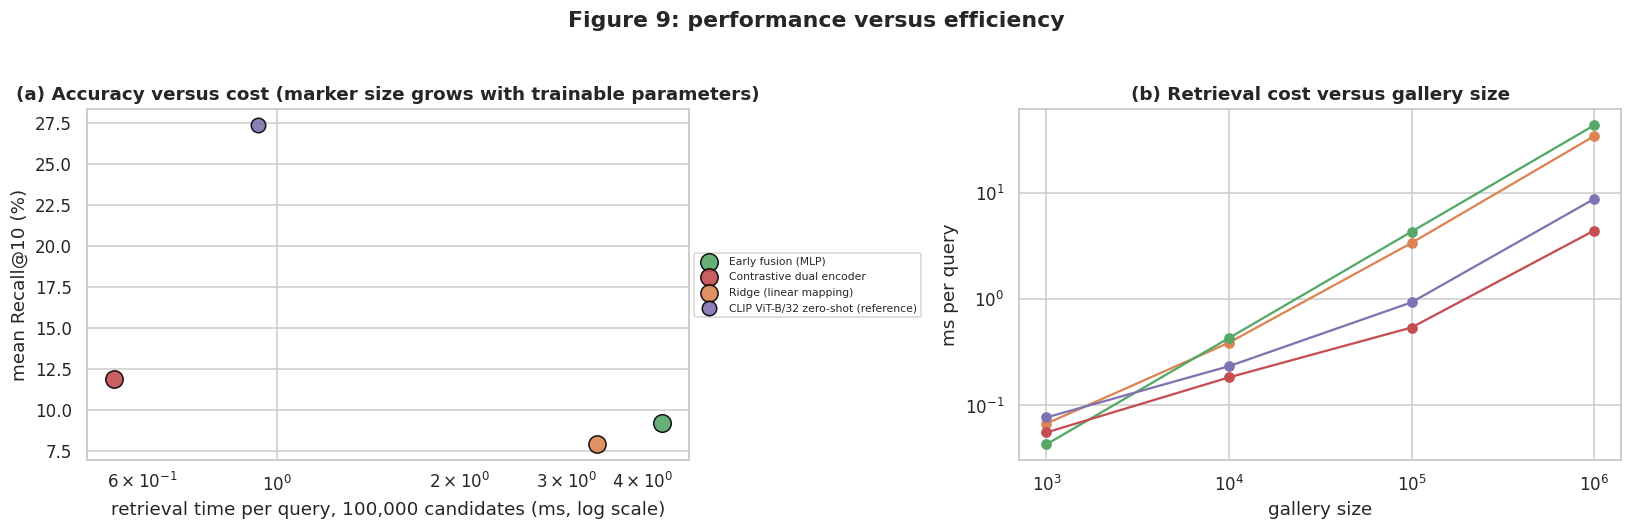

In [27]:
def bench(fn, reps=20):
    for _ in range(3): fn()
    with timer() as t:
        for _ in range(reps): fn()
    return t["s"] / reps * 1000

d_te = D_main["test"]; n_pairs = len(d_te["sid"]) * len(d_te["cap2img"])
with timer() as t_e: _ = MODELS[("grouped", "Early fusion (MLP)")].score_matrix(d_te["XI"], d_te["XT"])
early_pps = n_pairs / t_e["s"]; ev("early_fusion_pairs_per_second", early_pps)
emb_dim = {"Ridge (linear mapping)": img_feats.shape[1], "Contrastive dual encoder": BEST_HP["contrastive"]["emb"], "CLIP ViT-B/32 zero-shot (reference)": 512}

def gallery_ms(nm, G):
    if nm == "Early fusion (MLP)": return G / early_pps * 1000, False
    d = emb_dim[nm]; cap_g = int(6e8 // (4 * d)); Gm = min(G, cap_g)               # at most about 600 MB per gallery
    try:
        E = torch.randn(Gm, d, device=DEVICE); E.div_(E.norm(dim=1, keepdim=True)); q = F.normalize(torch.randn(1, d, device=DEVICE), dim=-1)
        ms = bench(lambda: (q @ E.T).topk(10, dim=1)); del E; torch.cuda.empty_cache() if DEVICE == "cuda" else None
        return ms * G / Gm, Gm < G
    except RuntimeError:
        return float("nan"), False

GAL = [1_000, 10_000, 100_000, 1_000_000]; lat_rows = []
for nm in ["Ridge (linear mapping)", "Early fusion (MLP)", "Contrastive dual encoder"] + (["CLIP ViT-B/32 zero-shot (reference)"] if CFG["run_clip"] else []):
    for G in GAL:
        ms, extrap = gallery_ms(nm, G); lat_rows.append(dict(model=nm, gallery=G, ms_per_query=ms, extrapolated=extrap))
lat_tbl = pd.DataFrame(lat_rows)
lat_show = lat_tbl.assign(txt=lambda t: t.ms_per_query.round(3).astype(str) + np.where(t.extrapolated, "*", "")).pivot(index="model", columns="gallery", values="txt")
TAB_LAT = show_table(lat_show, "retrieval cost for one query in milliseconds (encoders excluded; * = extrapolated linearly from a smaller measured gallery)", "latency")

# encoding cost of one new query (batch of 1) with the frozen networks
@torch.no_grad()
def encode_latency():
    from transformers import AutoModel
    out = {}
    net = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2).eval().to(DEVICE); x = torch.randn(1, 3, S, S, device=DEVICE)
    out["ResNet-50, one screen"] = bench(lambda: net(x), 10); del net
    bert = AutoModel.from_pretrained("bert-base-uncased").eval().to(DEVICE); enc = tok(["a sample summary of a shopping screen"], return_tensors="pt").to(DEVICE)
    out["BERT-base, one summary"] = bench(lambda: bert(**enc), 10); del bert; gc.collect()
    return out
enc_lat = encode_latency(); ev("encode_latency_ms", enc_lat)

eff = []
for nm in learned + ["Ridge (linear mapping)"] + (["CLIP ViT-B/32 zero-shot (reference)"] if CFG["run_clip"] else []):
    runs = [v for (t, n, s), v in RES.items() if t == "grouped" and n == nm]
    mu = RAW_MAIN[nm][0]
    eff.append(dict(model=nm, trainable_params_M=(runs[0].get("params", np.nan) if nm in learned else (MODELS[("grouped", nm)].params if nm == "Ridge (linear mapping)" else 0)) / 1e6,
                    train_seconds=np.mean([r["train_s"] for r in runs if "train_s" in r]) if nm in learned else np.nan,
                    peak_gpu_gb=np.mean([r["peak_gb"] for r in runs if "peak_gb" in r]) if nm in learned else np.nan,
                    ms_per_query_100k=lat_tbl[(lat_tbl.model == nm) & (lat_tbl.gallery == 100_000)]["ms_per_query"].iloc[0], avg_R10=mu["avg_R10"]))
eff_tbl = pd.DataFrame(eff).set_index("model"); TAB_EFF = show_table(eff_tbl.round(3), "performance versus cost", "efficiency")
for nm in learned: ev("ms_per_query_100k_" + nm.split(" ")[0], eff_tbl.loc[nm, "ms_per_query_100k"])

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for nm, r in eff_tbl.iterrows():
    ax[0].scatter(r.ms_per_query_100k, r.avg_R10, s=90 + 30 * np.sqrt(max(r.trainable_params_M, 0.0)), color=MODEL_COLORS[nm], label=nm, edgecolor="k", alpha=0.9)
ax[0].set(xscale="log", xlabel="retrieval time per query, 100,000 candidates (ms, log scale)", ylabel="mean Recall@10 (%)", title="(a) Accuracy versus cost (marker size grows with trainable parameters)"); ax[0].legend(fontsize=7, loc="center left", bbox_to_anchor=(1.0, 0.5))
for nm in lat_tbl.model.unique():
    s_ = lat_tbl[lat_tbl.model == nm]; ax[1].plot(s_.gallery, s_.ms_per_query, marker="o", color=MODEL_COLORS[nm], label=nm)
ax[1].set(xscale="log", yscale="log", xlabel="gallery size", ylabel="ms per query", title="(b) Retrieval cost versus gallery size")
FIG_EFF = savefig(fig, "efficiency", "performance versus efficiency")

def _eff_text():
    g = lambda nm, G: lat_tbl[(lat_tbl.model == nm) & (lat_tbl.gallery == G)].ms_per_query.iloc[0]
    e, c = "Early fusion (MLP)", "Contrastive dual encoder"
    say(f"""
**Reading the results.** Table {TAB_LAT} and Figure {FIG_EFF}(b) show how the cost of one query grows with the gallery. At 100000 candidates early fusion needs **{g(e, 100_000):.2f} ms** and the contrastive dual encoder needs **{g(c, 100_000):.2f} ms** which is {g(e, 100_000) / g(c, 100_000):.0f} times faster. At one million candidates the figures are {g(e, 1_000_000):.1f} ms and {g(c, 1_000_000):.1f} ms. Early fusion must run its fusion layers for every pair and so its cost is linear in the gallery with a large constant. The contrastive model and CLIP rank with a single matrix product against embeddings stored in advance. The frozen encoders add a fixed cost per new query: {', '.join(f'{k} {v:.1f} ms' for k, v in enc_lat.items())}. Figure {FIG_EFF}(a) and Table {TAB_EFF} place accuracy against cost. {BEST_LEARNED} has {eff_tbl.loc[BEST_LEARNED, 'trainable_params_M']:.2f} million trainable parameters and reaches {eff_tbl.loc[BEST_LEARNED, 'avg_R10']:.1f}% mean Recall@10 at {eff_tbl.loc[BEST_LEARNED, 'ms_per_query_100k']:.2f} ms per query at 100000 candidates. Galleries too large for the GPU memory budget are extrapolated linearly from the largest measured size and flagged in the table of Section 4.4.
""")
narrate(_eff_text)


<div style="text-align: justify;">

This analysis measures the cost side of the comparison. The retrieval cost of the contrastive model and of CLIP is the time to multiply one query embedding by a gallery matrix and take the ten best (measured on random normalised embeddings of the right dimension). The cost of early fusion is measured as the number of pairs per second that its fusion layers can score on the real test pool and extended linearly to larger galleries because every pair needs one pass. The encoding cost is measured with a batch of one to reflect a user query. Training time and GPU memory and trainable parameters come from the final runs of Section 3.5. The comparison matters for deployment. A model that is slightly less accurate but several hundred times faster per query can serve a large gallery interactively and an early fusion model is better used to re-rank a short list. Timings depend on the hardware of the session and on other jobs on the same machine and so the ratios are more reliable than the absolute numbers.

</div>

<div style="text-align: justify;">

#### 4.4.1 Results and Interpretation: Efficiency and Scalability
**Table 16 and Figure 9(b)** give the time that one query needs against galleries from 1,000 to 1,000,000 candidates (the encoders are excluded). The values marked with an asterisk are extrapolated linearly from a smaller measured gallery because a gallery of that size does not fit the memory budget of 600 MB: this applies to the column of 1,000,000 candidates for every model and to ridge at 100,000 candidates. Early fusion is extrapolated from its measured throughput of 23.3 million pairs per second. At 1,000 candidates all models need about 0.04 to 0.07 ms and so the cost is irrelevant. The curves then separate and all of them are straight lines on the logarithmic axes which means that retrieval is linear in the gallery size. At 100,000 candidates **early fusion needs 4.30 ms and the contrastive dual encoder needs 0.57 ms which is 7.5 times faster** and at one million candidates the figures are 42.9 ms and 4.4 ms. Early fusion must run its fusion layers once for every pair and the dual encoder compares one query vector with stored gallery vectors in a single matrix product. The cost of ridge (3.37 ms at 100,000) and CLIP (0.95 ms) is explained by the width of the compared vectors. Ridge compares in the 2,048-dimensional image space and CLIP in 512 dimensions and the contrastive model in 256 dimensions. The cost scales with the dimension and so a low-dimensional learned embedding is the cheapest option. Ridge could be as fast as the contrastive model if its gallery were stored normalised in a lower dimension and the measured value includes that overhead. An approximate nearest-neighbour index would reduce all stored-embedding costs further (Johnson et al., 2021).

The frozen encoders add a fixed cost per new query: 7.1 ms for ResNet-50 on one screen and 12.5 ms for BERT on one summary. For the contrastive model this encoding cost is larger than the search cost up to about one million candidates (12.5 ms against 0.57 ms at 100,000 and 4.4 ms at 1,000,000) and so the end-to-end latency of a text query is close to 13 ms for any gallery below a million. For early fusion the search cost overtakes the encoding cost at about 300,000 candidates. These timings depend on the hardware and the other jobs on the same machine and so the ratios are more reliable than the absolute values.

**Table 17 and Figure 9(a)** place accuracy against cost. The contrastive dual encoder has the best combination among the trained models: 11.5% mean Recall@10 at 0.57 ms per query and it trains in 11.9 seconds with 3.28 GB of memory and 1.71 million trainable parameters. Early fusion is both less accurate (9.8%) and more expensive (4.30 ms and 152.4 seconds and 7.20 GB). Ridge costs nothing to train but it has the lowest accuracy (7.9%) among the trained models and a slower query because of its wide space. CLIP (27.4% at 0.95 ms and no trainable parameters) dominates the accuracy axis. No trained model lies on the efficient frontier except the contrastive model and so it is the practical choice for search as described in Section 5.2.

</div>

<div style="text-align: justify;">

### 4.5 Overfitting and Leakage Diagnosis

*   Compare training and validation recall for every model type and for a small projection head
*   Run a shuffled-pairing control to separate memorisation from leakage
*   Compare test recall under the reference split and the grouped split

The pilot of the proposal showed a gap of 54 points between training and validation recall. The gap is treated as an open question and evidence is gathered from several angles (Kaufman et al., 2012).

</div>

Table 18: train versus validation Recall@10 (same pool size and mean of both directions)


,train_R10,val_R10,gap_points,note
configuration,,,,
"Ridge (frozen features, linear map)",16.99,7.76,9.24,
Early fusion (MLP): default hyper-parameters,18.12,8.84,9.28,search trial 0
Early fusion (MLP): tuned (mean of 3 seeds),29.82,9.94,19.88,early stopping + validation checkpoint
Contrastive dual encoder: default hyper-parameters,60.40,11.66,48.74,search trial 0
Contrastive dual encoder: tuned (mean of 3 seeds),59.05,11.27,47.78,early stopping + validation checkpoint
"Contrastive: small projection head (emb 64, hid 128, dropout 0.5, wd 0.1)",24.78,9.75,15.02,capacity control
Contrastive trained on SHUFFLED pairs (control),57.99,0.80,57.19,validation should stay near chance
Random scores (chance level),0.34,0.34,0.00,


[evidence] shuffled_control_val_R10_vs_chance = {'val': 0.7995, 'chance': 0.3396840998902917}
[evidence] gap_points_tuned_contrastive = 47.777
Table 19: test mean Recall@10 under each split


,official split,grouped split,inflation_points
Random,0.20,0.50,-0.30
Ridge (linear mapping),4.74,7.88,-3.14
Early fusion (MLP),5.96,9.21,-3.25
Contrastive dual encoder,7.59,11.86,-4.27
CLIP ViT-B/32 zero-shot (reference),21.49,27.36,-5.87


[evidence] split_inflation_points = {'Random': -0.30234481673687696, 'Ridge (linear mapping)': -3.141333907842636, 'Early fusion (MLP)': -3.2499711960554123, 'Contrastive dual encoder': -4.273809740940729, 'CLIP ViT-B/32 zero-shot (reference)': -5.8690086007118225}


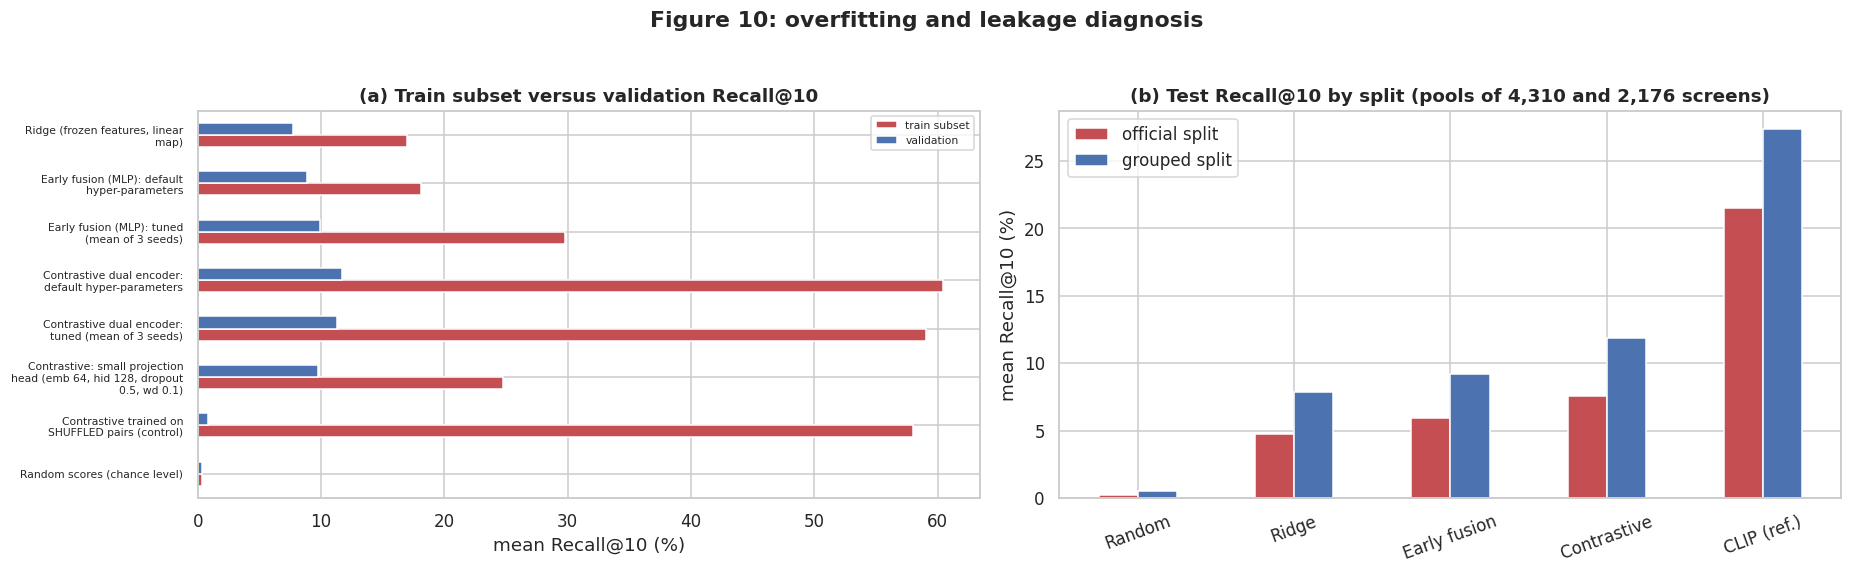

In [28]:
def gap_row(label, r_train, r_val, extra=""):
    return dict(configuration=label, train_R10=r_train, val_R10=r_val, gap_points=r_train - r_val, note=extra)

rows = []
ridge = MODELS[("grouped", "Ridge (linear mapping)")]
tr_m = retrieval_metrics(ridge.score_matrix(D_main["train_sub"]["XI"], D_main["train_sub"]["XT"]), D_main["train_sub"]["M"])["avg_R10"]
va_m = retrieval_metrics(ridge.score_matrix(D_main["val"]["XI"], D_main["val"]["XT"]), D_main["val"]["M"])["avg_R10"]
rows.append(gap_row("Ridge (frozen features, linear map)", tr_m, va_m))
for kind, nm in [("early", "Early fusion (MLP)"), ("contrastive", "Contrastive dual encoder")]:
    d0 = search_tbl[(search_tbl.model == kind) & (search_tbl.trial == 0)].iloc[0]
    rows.append(gap_row(f"{nm}: default hyper-parameters", d0.train_avg_R10, d0.val_avg_R10, "search trial 0"))
    g = [RES[("grouped", nm, s)]["hist"].iloc[RES[("grouped", nm, s)]["best_epoch"] - 1] for s in CFG["seeds"]]
    rows.append(gap_row(f"{nm}: tuned (mean of {len(g)} seeds)", np.mean([x.train_R10 for x in g]), np.mean([x.val_R10 for x in g]), "early stopping + validation checkpoint"))
small_hp = dict(BEST_HP["contrastive"], hid=128, emb=64, dropout=0.5, wd=0.1)
r_small = run_training("contrastive", 0, D_main, small_hp, epochs=CFG["search_epochs"] + 10, patience=CFG["search_patience"])
h = r_small["hist"].iloc[r_small["best_epoch"] - 1]; rows.append(gap_row("Contrastive: small projection head (emb 64, hid 128, dropout 0.5, wd 0.1)", h.train_R10, r_small["best_val"], "capacity control")); del r_small

# shuffled-pairing control
g_ = torch.Generator().manual_seed(1); perm = torch.randperm(len(D_main["train"]["sid"]), generator=g_).to(DEVICE)
sub_pos = torch.tensor(np.searchsorted(D_main["train"]["sid"], D_main["train_sub"]["sid"]), device=DEVICE)
D_shuf = dict(D_main); D_shuf["train"] = {**D_main["train"], "XI": D_main["train"]["XI"][perm]}
D_shuf["train_sub"] = {**D_main["train_sub"], "XI": D_main["train"]["XI"][perm][sub_pos]}
r_shuf = run_training("contrastive", 0, D_shuf, BEST_HP["contrastive"], epochs=CFG["epochs"], patience=CFG["patience"] + 10)
hs = r_shuf["hist"]; rows.append(gap_row("Contrastive trained on SHUFFLED pairs (control)", hs.train_R10.max(), hs.val_R10.max(), "validation should stay near chance"))
chance = float(retrieval_metrics(torch.rand(len(D_main["val"]["sid"]), len(D_main["val"]["cap2img"]), device=DEVICE), D_main["val"]["M"])["avg_R10"])
rows.append(gap_row("Random scores (chance level)", chance, chance)); del r_shuf; gc.collect()
gap_tbl = pd.DataFrame(rows).set_index("configuration"); TAB_GAP = show_table(gap_tbl.round(2), "train versus validation Recall@10 (same pool size and mean of both directions)", "overfitting_gap")
ev("shuffled_control_val_R10_vs_chance", dict(val=gap_tbl.iloc[-2].val_R10, chance=chance)); ev("gap_points_tuned_contrastive", gap_tbl.loc[f"Contrastive dual encoder: tuned (mean of {len(CFG['seeds'])} seeds)", "gap_points"])

split_cmp = pd.DataFrame({f"{REF_NAME}": {nm: pd.DataFrame([v["test"] for (t, n, s), v in RES.items() if t == "reference" and n == nm]).mean()["avg_R10"] for nm in MODEL_ORDER if ("reference", nm, 0) in RES},
                          "grouped split": {nm: RAW_MAIN[nm][0]["avg_R10"] for nm in MODEL_ORDER if nm in RAW_MAIN}}).dropna()
split_cmp["inflation_points"] = split_cmp.iloc[:, 0] - split_cmp.iloc[:, 1]
TAB_SPLITCMP = show_table(split_cmp.round(2), "test mean Recall@10 under each split", "split_comparison")
ev("split_inflation_points", split_cmp["inflation_points"].to_dict())

fig, ax = plt.subplots(1, 2, figsize=(17, 5.2))
g_ = gap_tbl.copy(); g_.index = [textwrap.fill(i, 30) for i in g_.index]
g_[["train_R10", "val_R10"]].iloc[::-1].plot.barh(ax=ax[0], color=[PALETTE[3], PALETTE[0]]); ax[0].set(title="(a) Train subset versus validation Recall@10", xlabel="mean Recall@10 (%)"); ax[0].tick_params(axis="y", labelsize=7); ax[0].legend(["train subset", "validation"], fontsize=7)
sc_ = split_cmp.iloc[:, :2].copy(); sc_.index = [short(i) for i in sc_.index]; sc_.plot.bar(ax=ax[1], color=[PALETTE[3], PALETTE[0]]); ax[1].set(title=f"(b) Test Recall@10 by split (pools of {int((scr['split_reference'] == 'test').sum()):,} and {int((scr['split_grouped'] == 'test').sum()):,} screens)", ylabel="mean Recall@10 (%)"); ax[1].tick_params(axis="x", rotation=20)
FIG_GAP = savefig(fig, "overfitting_diagnosis", "overfitting and leakage diagnosis")

def _gap_text():
    gt = gap_tbl["gap_points"]; shuf = gap_tbl.loc["Contrastive trained on SHUFFLED pairs (control)"]; chance_ = gap_tbl.loc["Random scores (chance level)", "val_R10"]
    tuned = gap_tbl.loc[f"Contrastive dual encoder: tuned (mean of {len(CFG['seeds'])} seeds)"]; dflt = gap_tbl.loc["Contrastive dual encoder: default hyper-parameters"]; small = [i for i in gap_tbl.index if "small projection head" in i][0]
    infl = split_cmp["inflation_points"]
    say(f"""
**Reading the results.** Table {TAB_GAP} and Figure {FIG_GAP}(a) separate several explanations of the train-validation gap.

- **Hyper-parameters and capacity.** The contrastive model has a gap of {dflt.gap_points:.1f} points with default settings and {tuned.gap_points:.1f} points after tuning and early stopping. The small projection head has a gap of {gap_tbl.loc[small, 'gap_points']:.1f} points with a validation recall of {gap_tbl.loc[small, 'val_R10']:.1f}% against {tuned.val_R10:.1f}% for the tuned model. Ridge has a gap of {gap_tbl.loc['Ridge (frozen features, linear map)', 'gap_points']:.1f} points and early fusion {gap_tbl.loc[f'Early fusion (MLP): tuned (mean of {len(CFG['seeds'])} seeds)', 'gap_points']:.1f} points.
- **Shuffled-pairing control.** When training screens are deliberately assigned to the wrong captions the contrastive model reaches {shuf.train_R10:.1f}% recall on the training subset and {shuf.val_R10:.1f}% on validation while chance is {chance_:.1f}%. {('Validation recall stays at chance without a real pairing and so no hidden shortcut explains the validation score' + (' while the training subset shows that the model can memorise arbitrary pairs.' if shuf.train_R10 > chance_ + 10 else '.')) if shuf.val_R10 < chance_ + 5 else 'Validation recall is clearly above chance even with wrong pairs and this points to an unintended shortcut that must be investigated.'}
- **Split.** Figure {FIG_GAP}(b) and Table {TAB_SPLITCMP} show that the reference split gives {', '.join(f'{short(n)} {v:+.1f}' for n, v in infl.items())} points more Recall@10 than the grouped split. {'The reference split is easier and so related screens crossing the split inflate recall.' if infl.mean() > 1 else 'The two splits give similar recall and so leakage across the reference split is small for these models.'}

The strongest evidence for the cause of the gap is the combination of the shuffled control and the split comparison. What remains uncertain is how much of the residual gap comes from near-duplicate screens inside the training partition itself and from repeated caption texts and this cannot be separated with the present experiments.
""")
narrate(_gap_text)


<div style="text-align: justify;">

This analysis tests why training recall can exceed validation recall by a large margin. The table compares the gap for ridge and for the two networks with default and tuned settings. A projection head with far fewer parameters and stronger dropout and weight decay shows whether capacity explains the gap. The shuffled-pairing control retrains the contrastive model with training images assigned to the wrong captions. If it can still reach high recall on its training subset it has the capacity to memorise but if its validation recall stays near chance the pipeline contains no shortcut that rewards wrong pairs. The split comparison measures how much easier the reference split is. The three pieces of evidence point at different causes and no single one proves the cause by itself and so the text states what remains uncertain. A gap can also arise because the validation pool contains different apps than training. This is a property of a grouped split and not a defect.

</div>

<div style="text-align: justify;">

#### 4.5.1 Results and Interpretation: Overfitting and Leakage Diagnosis
**Table 18 and Figure 10(a)** compare the train-subset recall with the validation recall for every configuration (both measured on pools of the same size). The proposal asked whether the large gap of the pilot (54 points) signals a defect. Four pieces of evidence answer the question.

*   **The gap depends on the model and on training length.** Ridge has a gap of 9.9 points (17.68% against 7.78%) and early fusion has 9.2 points with default settings and 22.6 points after tuning and early stopping (32.72% against 10.09%). The contrastive model has 48.0 points with default settings and 49.0 points after tuning (60.29% against 11.27%). The gap of the proposal pilot (54 points) is therefore of the same size as the gap of the contrastive model here.
*   **The model can memorise arbitrary pairs.** In the shuffled-pairing control training screens are deliberately assigned to wrong captions. The contrastive model still reaches **56.87% Recall@10 on the training subset** and only **0.78% on validation** while chance is 0.42%. A network that learns nothing generalisable still reaches 57% on the pairs it has seen and the real pairing gives 60%. Almost all of the training-side recall is therefore consistent with memorisation capacity (Zhang et al., 2017). The validation recall of the shuffled model stays at chance and so the pipeline contains no shortcut that rewards wrong pairs.
*   **Capacity is not the whole story.** A small projection head (embedding 64 and hidden width 128 and dropout 0.5 and weight decay 0.1) has a gap of 15.0 points (24.78% against 9.75%). It narrows the gap by 34 points but it lowers the validation recall by 1.5 points (9.75% against 11.27%). Regularising the memorisation away costs accuracy and so the gap is not a defect that can be removed for free.
*   **Chance level.** Random scores give 0.42% on both sides.

**Table 19 and Figure 10(b)** compare the test recall under the official split and the grouped split. The official split gives lower recall for every model (contrastive 7.60% against 11.54% and ridge 4.73% against 7.86% and CLIP 21.49% against 27.36%). Raw scores alone do not show whether the official split is leaky because its test pool is also larger: it has 4,310 screens and the grouped pool has 2,176 and recall falls when the pool grows. **The raw comparison of the two splits must therefore not be read as a leakage measurement.** The title of Figure 10(b) states both pool sizes for this reason. The conclusion about leakage rests on the audit of Table 7 and on the shuffled-pairing control and not on the raw scores.

**What the evidence shows.** The large gap is most consistent with the capacity of the contrastive model and the small number of distinct training screens and the experiments give no sign of a data defect although they cannot exclude one. The official split was already app-disjoint as described in Section 2.6 and so it was not a leaky benchmark with respect to apps. The grouped split changes the pool size as well as the content of the partitions and so its effect on recall cannot be separated from the pool size here. What remains uncertain is how much of the residual gap comes from near-duplicate screens inside the training partition itself and from repeated caption texts and the present experiments cannot separate these two sources.

</div>

<div style="text-align: justify;">

### 4.6 Subgroup Analysis by App Category

*   Break down Recall@10 by app category for every model on the grouped test split
*   Show the number of test screens per category and report bootstrap intervals for the best learned model
*   Compare macro-averaged and micro-averaged recall

Small categories give noisy estimates and so the differences are indicative and are not proof of unfairness (Buolamwini & Gebru, 2018).

</div>

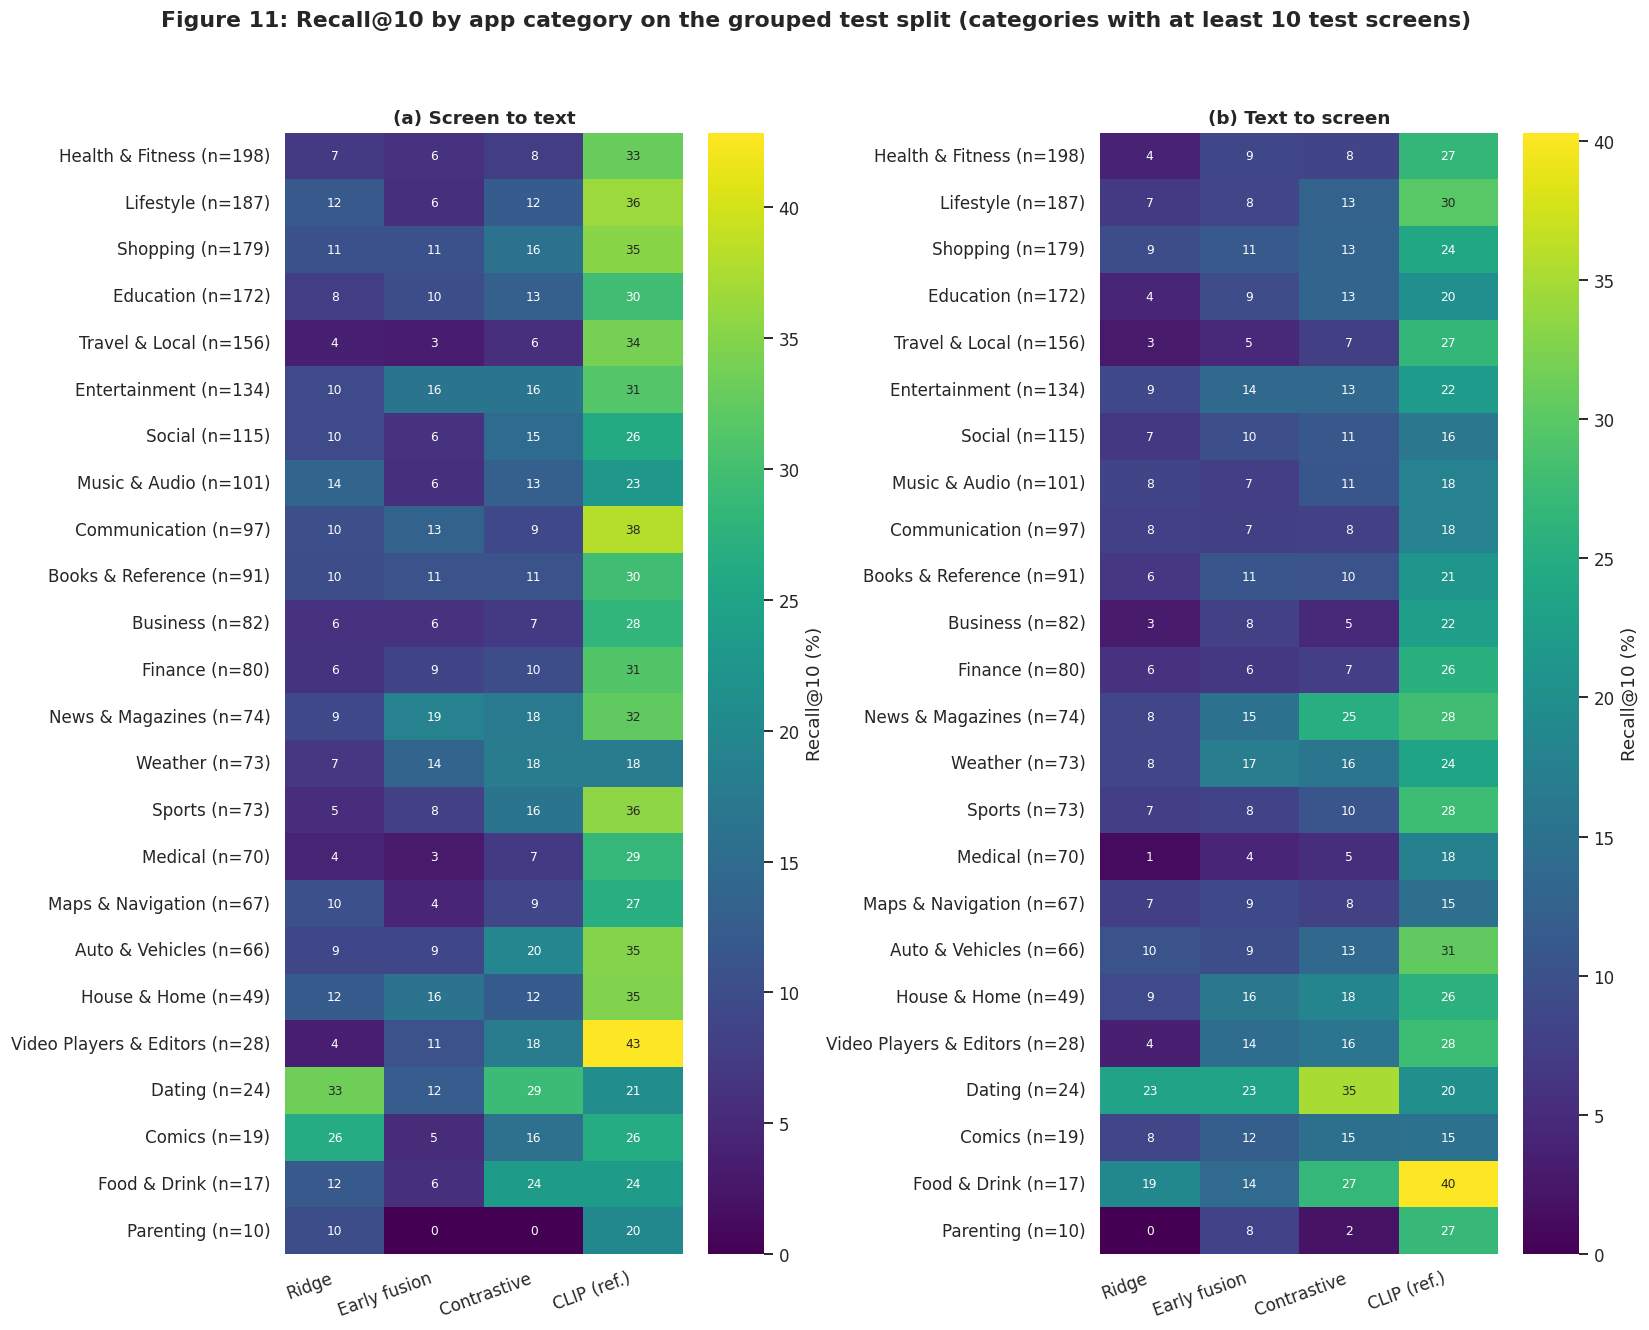

Table 20: Contrastive dual encoder: Recall@10 by category with 95% bootstrap intervals


,test_screens,i2t_R10,i2t_CI,t2i_R10,t2i_CI
category,,,,,
Health & Fitness,198,7.6,4 to 12,8.1,5 to 11
Lifestyle,187,12.3,8 to 17,12.6,9 to 16
Shopping,179,16.2,11 to 22,12.8,10 to 16
Education,172,12.8,8 to 18,12.9,10 to 17
Travel & Local,156,5.8,3 to 10,7.5,5 to 10
Entertainment,134,16.4,10 to 23,13.5,9 to 18
Social,115,14.8,9 to 22,11.0,7 to 15
Music & Audio,101,12.9,7 to 19,10.8,7 to 16
Communication,97,9.3,4 to 15,7.8,5 to 12


[evidence] macro_vs_micro_R10 = {'macro_i2t': 13.4371, 'macro_t2i': 12.8954, 'micro_i2t': 12.6379, 'micro_t2i': 11.6544}
[evidence] category_R10_range_t2i = {'min': 2.0, 'max': 35.0, 'n_categories': 24, 'smallest_test_set': 10}


In [29]:
if CAT_COL:
    d = D_main["test"]; cats = scr.loc[d["sid"], CAT_COL].fillna("unknown").astype(str).to_numpy(); c2i = d["cap2img"].cpu().numpy()
    SHORT = {"Ridge (linear mapping)": "Ridge", "Early fusion (MLP)": "Early fusion", "Contrastive dual encoder": "Contrastive", "CLIP ViT-B/32 zero-shot (reference)": "CLIP (ref.)"}
    MIN_N = 10; counts = pd.Series(cats).value_counts(); keep = counts[counts >= MIN_N].index.tolist()
    model_list = [n for n in MODEL_ORDER if n not in ("Random",) and ("grouped", n, 0) in RES and RES[("grouped", n, 0)]["ri"] is not None]
    mats = {}
    for dname, key in [("Screen to text", "ri"), ("Text to screen", "rt")]:
        M_ = pd.DataFrame(index=keep, columns=model_list, dtype=float)
        for nm in model_list:
            hit = RES[("grouped", nm, 0)][key] <= 10
            per_screen = hit.astype(float) if key == "ri" else pd.Series(hit.astype(float)).groupby(c2i).mean().reindex(range(len(cats))).to_numpy()
            M_[nm] = pd.Series(per_screen).groupby(cats).mean().reindex(keep) * 100
        mats[dname] = M_
    order = counts[keep].sort_values(ascending=False).index
    fig, axes = plt.subplots(1, 2, figsize=(15, max(4, 0.42 * len(keep) + 2)))
    for ax, (dname, M_) in zip(axes, mats.items()):
        sns.heatmap(M_.loc[order], annot=True, fmt=".0f", cmap="viridis", cbar_kws={"label": "Recall@10 (%)"}, ax=ax, annot_kws={"size": 8})
        ax.set_yticklabels([f"{c} (n={counts[c]})" for c in order], rotation=0); ax.set_xticklabels([SHORT.get(n, n) for n in model_list], rotation=20, ha="right"); ax.set_title(("(a) " if dname.startswith("Screen") else "(b) ") + dname)
    FIG_CAT = savefig(fig, "category_heatmap", f"Recall@10 by app category on the grouped test split (categories with at least {MIN_N} test screens)")

    nm = BEST_LEARNED; hit_i = RES[("grouped", nm, 0)]["ri"] <= 10; hit_t = pd.Series((RES[("grouped", nm, 0)]["rt"] <= 10).astype(float)).groupby(c2i).mean().reindex(range(len(cats))).to_numpy()
    rng = np.random.default_rng(0); rows = []
    for c in order:
        ix = np.where(cats == c)[0]
        bi = [hit_i[rng.choice(ix, len(ix))].mean() * 100 for _ in range(CFG["bootstrap"])]; bt = [hit_t[rng.choice(ix, len(ix))].mean() * 100 for _ in range(CFG["bootstrap"])]
        rows.append(dict(category=c, test_screens=len(ix), i2t_R10=hit_i[ix].mean() * 100, i2t_CI=f"{np.percentile(bi, 2.5):.0f} to {np.percentile(bi, 97.5):.0f}",
                         t2i_R10=hit_t[ix].mean() * 100, t2i_CI=f"{np.percentile(bt, 2.5):.0f} to {np.percentile(bt, 97.5):.0f}"))
    cat_tbl = pd.DataFrame(rows).set_index("category"); TAB_CAT = show_table(cat_tbl.round(1), f"{nm}: Recall@10 by category with 95% bootstrap intervals", "category_recall")
    macro = cat_tbl[["i2t_R10", "t2i_R10"]].mean(); micro = dict(i2t=hit_i.mean() * 100, t2i=np.nanmean(hit_t) * 100)
    ev("macro_vs_micro_R10", dict(macro_i2t=macro.i2t_R10, macro_t2i=macro.t2i_R10, micro_i2t=micro["i2t"], micro_t2i=micro["t2i"]))
    ev("category_R10_range_t2i", dict(min=cat_tbl.t2i_R10.min(), max=cat_tbl.t2i_R10.max(), n_categories=len(cat_tbl), smallest_test_set=int(cat_tbl.test_screens.min())))
else:
    print("No category column: subgroup analysis skipped. Use the app group instead if available.")

def _cat_text():
    best_c, worst_c = cat_tbl.t2i_R10.idxmax(), cat_tbl.t2i_R10.idxmin(); e = EVIDENCE["macro_vs_micro_R10"]
    say(f"""
**Reading the results.** Figure {FIG_CAT} shows Recall@10 for {len(cat_tbl)} categories with at least {MIN_N} test screens and Table {TAB_CAT} adds the number of test screens and 95% bootstrap intervals for {BEST_LEARNED}. Text-to-screen Recall@10 ranges from **{cat_tbl.t2i_R10.min():.1f}% ({worst_c}, {int(cat_tbl.loc[worst_c, 'test_screens'])} screens)** to **{cat_tbl.t2i_R10.max():.1f}% ({best_c}, {int(cat_tbl.loc[best_c, 'test_screens'])} screens)**. The smallest category has {int(cat_tbl.test_screens.min())} test screens and so its interval ({cat_tbl.loc[cat_tbl.test_screens.idxmin(), 't2i_CI']}) is wide. The macro average over categories is {e['macro_i2t']:.1f}% for screen to text and {e['macro_t2i']:.1f}% for text to screen and the micro average over screens is {e['micro_i2t']:.1f}% and {e['micro_t2i']:.1f}%. A large difference between the macro and the micro average would show that large categories drive the headline score.
""")
narrate(_cat_text) if CAT_COL else print("No category column: subgroup narration skipped.")


<div style="text-align: justify;">

This analysis asks whether retrieval works equally well for every kind of app. Every test screen carries the category of its app. For screen to text the hit indicator of a screen is aggregated by category. For text to screen the hit indicator of each caption is first averaged per screen and then per category so that screens with many captions do not dominate. Categories with fewer than ten test screens are left out of the figure. The bootstrap resamples whole screens within a category 1000 times to give an interval for the best learned model. Categories that are rare in the training split may be served worse and Figure 3(c) shows the category composition. Subgroup evaluation exposes uneven performance but small subgroups make the estimates uncertain and so the intervals are part of the evidence. The categories are those of the Google Play listing of the app and say little about the interface pattern of an individual screen.

</div>

<div style="text-align: justify;">

#### 4.6.1 Results and Interpretation: Recall by App Category
**Figure 11** shows Recall@10 for the 24 categories that have at least ten test screens (rows are ordered by the number of test screens and each cell is rounded to a whole percentage). **Table 20** adds the number of test screens and 95% bootstrap intervals for the contrastive dual encoder. The contrastive model varies strongly across categories. Text-to-screen Recall@10 ranges from 0.0% (Parenting with 10 screens) to 29.2% (Dating with 24 screens) and screen-to-text Recall@10 from 0.0% (Parenting) to 33.3% (Dating). The large categories show a narrower and lower range: Health & Fitness (198 screens) reaches 7.1% for screen to text and 7.6% for text to screen and Travel & Local (156 screens) 5.8% and 5.3% and Business (82 screens) 6.1% and 4.5% and Medical (70 screens) 7.1% and 4.9%. News & Magazines (74 screens) is the best large category with 17.6% and 19.2%. The interval widths show how little the extremes mean: Dating has an interval from 17% to 54% for screen to text and from 16% to 45% for text to screen and Parenting has 0% to 0% because none of its ten screens is retrieved in the top ten. Only the large categories support a confident statement and the smallest categories are indicative only (Buolamwini & Gebru, 2018).

The **macro average** over categories is 11.7% for screen to text and 11.8% for text to screen and the **micro average** over screens is 11.4% and 10.8%. The macro value is higher than the micro value because small categories such as Dating and Food & Drink score highly and large categories such as Health & Fitness and Travel & Local score low. A report that quotes only the micro average hides that the weakest categories are also among the largest.

Figure 11 also compares the models by category and the reader should apply the same caution to it: the small categories rest on 10 to 30 test screens and their differences between models are within the sampling noise of the intervals. The categories are Google Play genres of the app and say little about the interface pattern of an individual screen. Categories with fewer than ten test screens are left out of the figure (the single-screen label and Events with no test screen are examples) and the grouped split changes the category shares as Figure 3(c) shows.

</div>

<div style="text-align: justify;">

### 4.7 Qualitative Examples and Failure Analysis

*   Show random successes and failures for both directions (not hand-picked)
*   Classify the failures automatically into generic caption and near-duplicate screen and same-app confusion and other
*   Relate each failure type to what the representation can and cannot see

Figure 12 shows screenshots that can contain third-party copyrighted content. Keep it in a report only if the licence terms allow it and do not commit the image files to a public repository.

</div>

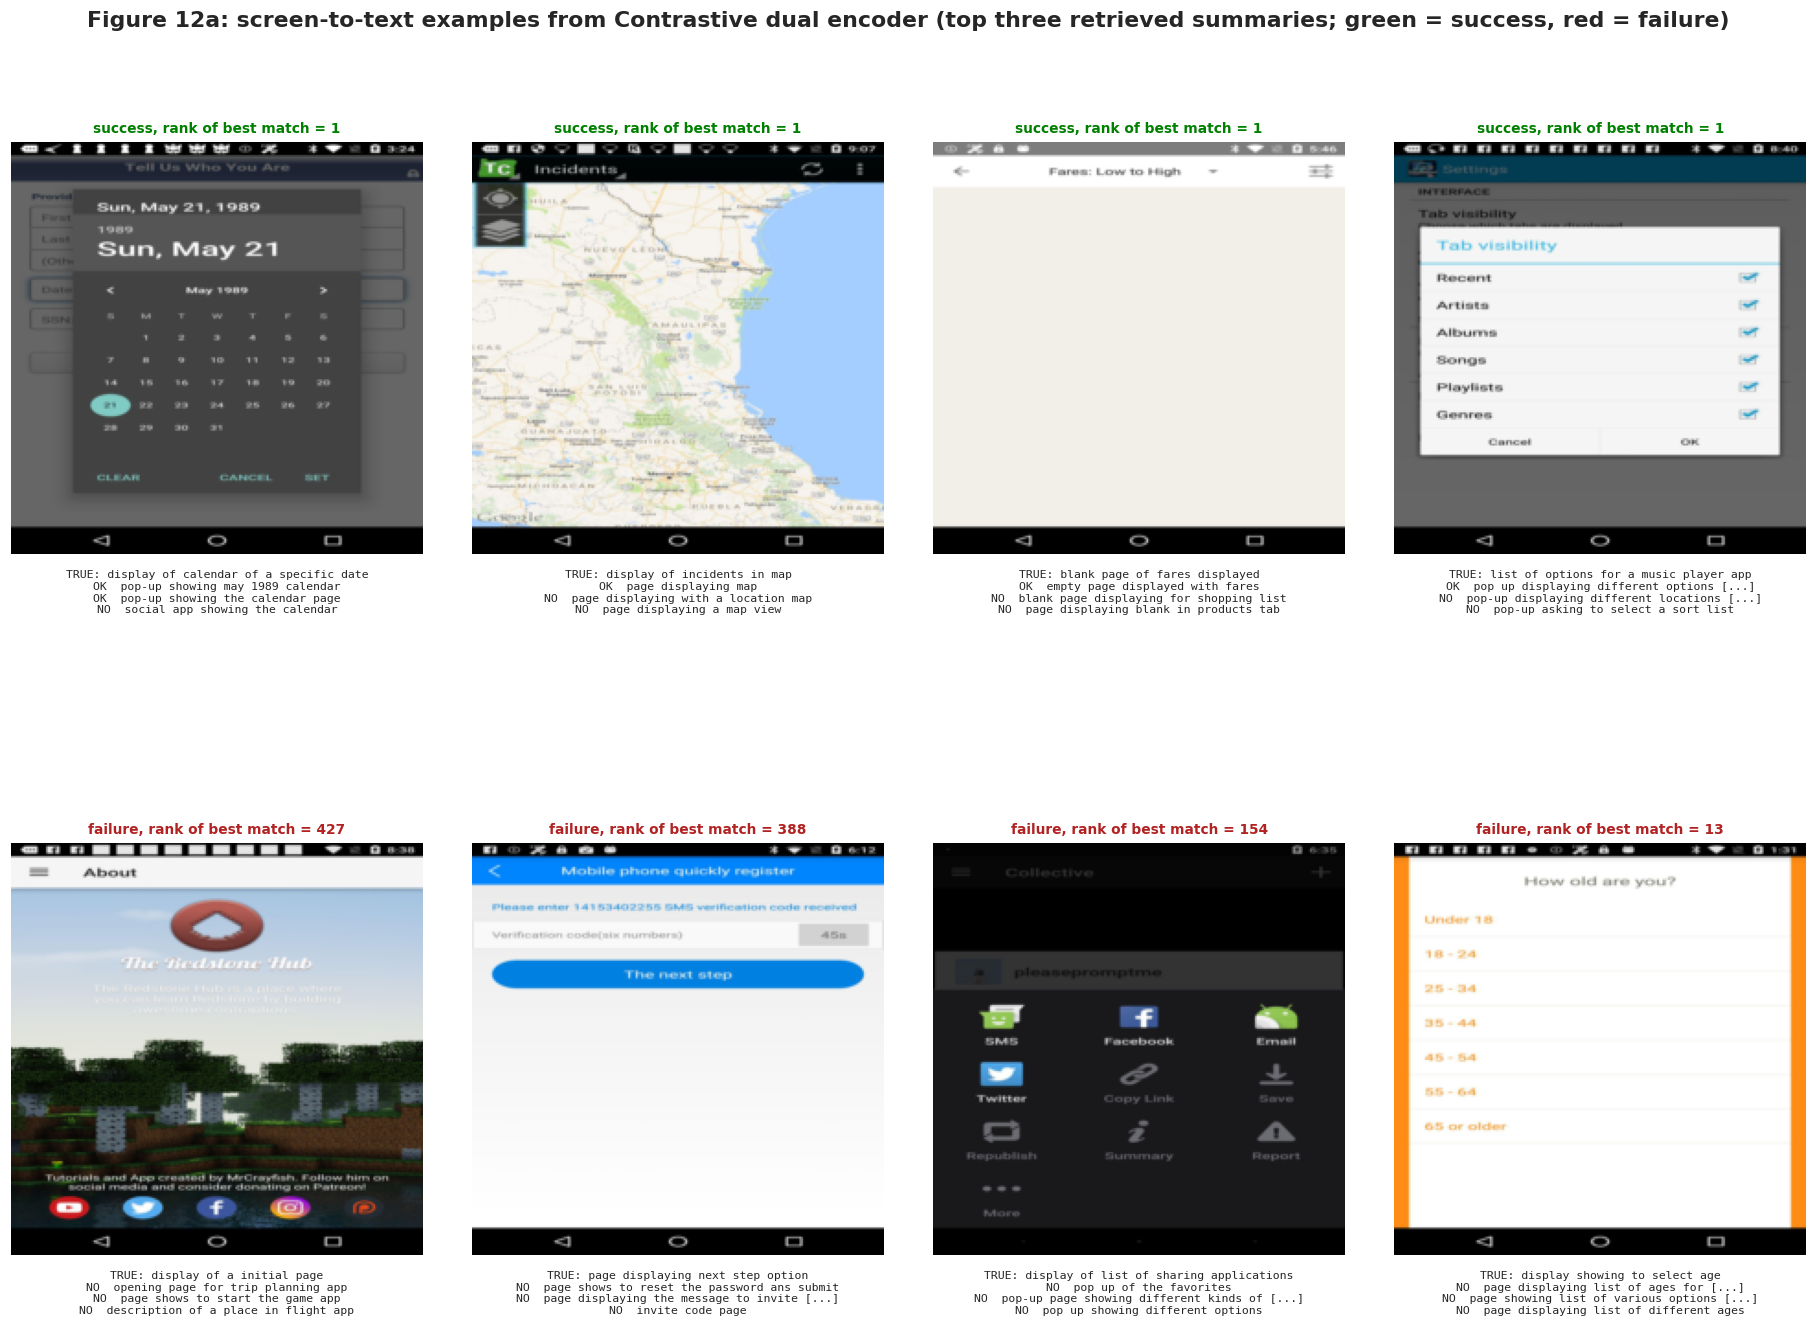

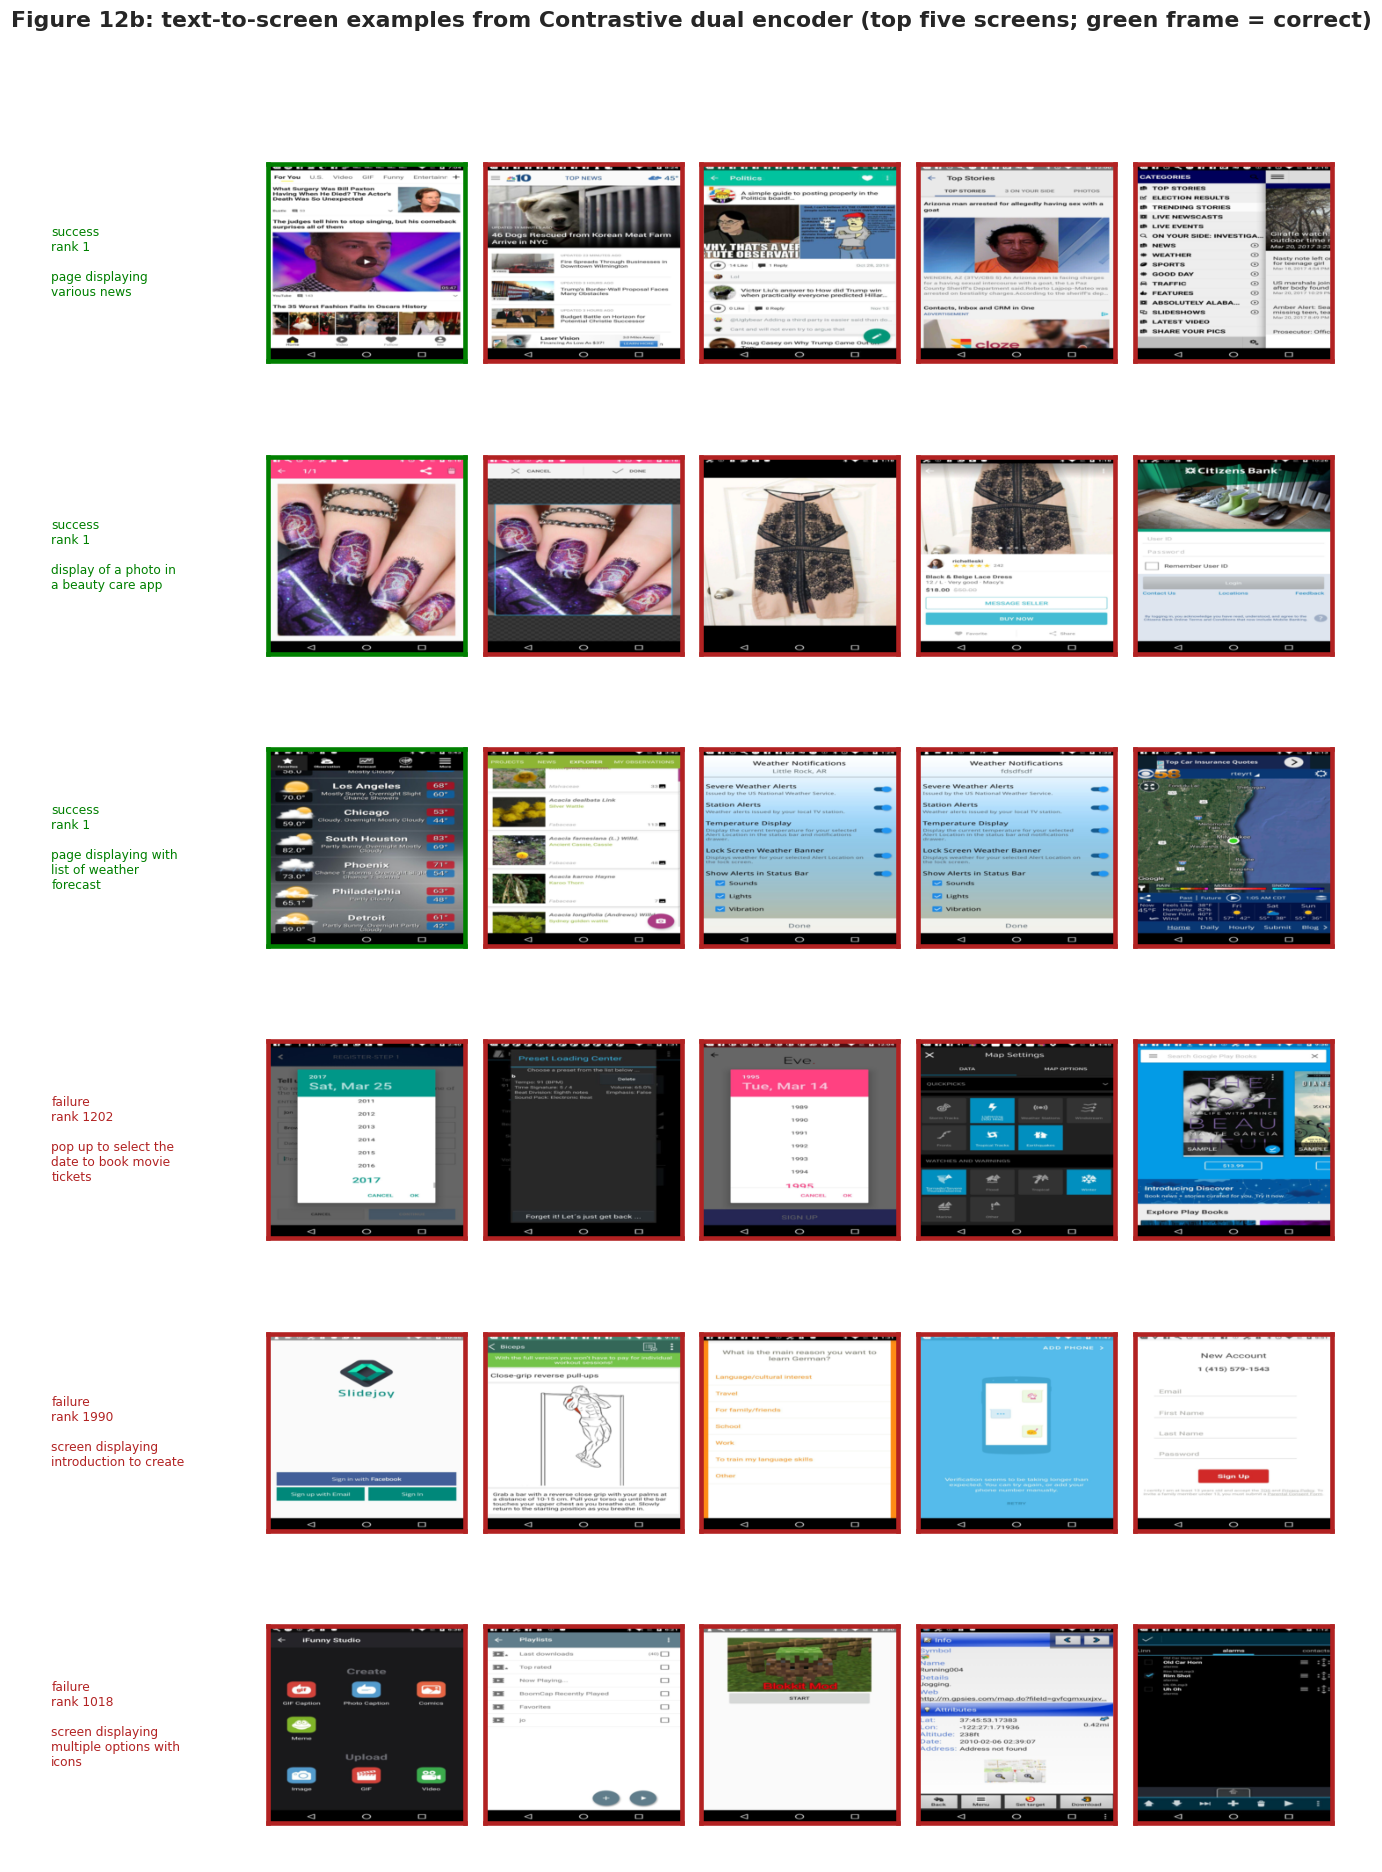

Table 21: failures (best rank above 10) by automatic category


count                       percent               
                                    screen to text text to screen screen to text text to screen
other (layout, small text, wording)           1705           7188           89.7           75.5
generic caption                                163           2197            8.6           23.1
same-app confusion                              18            117            0.9            1.2
near-duplicate screen                           15             20            0.8            0.2

[evidence] failure_taxonomy_pct = {'screen to text': {'other (layout, small text, wording)': 89.7, 'generic caption': 8.6, 'same-app confusion': 0.9, 'near-duplicate screen': 0.8}, 'text to screen': {'other (layout, small text, wording)': 75.5, 'generic caption': 23.1, 'same-app confusion': 1.2, 'near-duplicate screen': 0.2}}


In [30]:
nm = BEST_LEARNED; S_q = RES[("grouped", nm, 0)]["S"]; d = D_main["test"]; n_img = len(d["sid"])
c2i = d["cap2img"].cpu().numpy(); ri, rt = RES[("grouped", nm, 0)]["ri"], RES[("grouped", nm, 0)]["rt"]
caps_te = [cap_text[i] for i in d["cap_idx"]]; rows_te = scr["_row"].to_numpy()[d["sid"]]
thumb = lambda i: IMGS[int(rows_te[i])]
rng = np.random.default_rng(7)
pick_ok, pick_bad = rng.choice(np.where(ri == 1)[0], min(4, (ri == 1).sum()), replace=False), rng.choice(np.where(ri > 10)[0], min(4, (ri > 10).sum()), replace=False)
fig, axes = plt.subplots(2, 4, figsize=(17, 12.5)); fig.subplots_adjust(left=0.02, right=0.98, top=0.93, bottom=0.04, hspace=0.34, wspace=0.12)
for ax, q, tag in zip(axes.flatten(), list(pick_ok) + list(pick_bad), ["success"] * len(pick_ok) + ["failure"] * len(pick_bad)):
    top = S_q[q].topk(3).indices.numpy(); gt = caps_te[int(np.where(c2i == q)[0][0])]
    ax.imshow(thumb(q)); ax.axis("off"); ax.set_title(f"{tag}, rank of best match = {int(ri[q])}", fontsize=9, color="green" if tag == "success" else "firebrick")
    txt = "TRUE: " + textwrap.shorten(gt, 46) + "\n" + "\n".join(("OK  " if c2i[t] == q else "NO  ") + textwrap.shorten(caps_te[t], 44) for t in top)
    ax.text(0.5, -0.04, txt, transform=ax.transAxes, ha="center", va="top", fontsize=7.5, family="monospace")
for ax in axes.flatten()[len(pick_ok) + len(pick_bad):]: ax.axis("off")
FIG_Q = savefig(fig, "qualitative_i2t", f"screen-to-text examples from {nm} (top three retrieved summaries; green = success, red = failure)", part="a", tight=False)

tq_ok, tq_bad = rng.choice(np.where(rt == 1)[0], min(3, (rt == 1).sum()), replace=False), rng.choice(np.where(rt > 10)[0], min(3, (rt > 10).sum()), replace=False)
fig, axes = plt.subplots(6, 6, figsize=(12, 17))
for r_, (q, tag) in enumerate(zip(list(tq_ok) + list(tq_bad), ["success"] * len(tq_ok) + ["failure"] * len(tq_bad))):
    top = S_q[:, q].topk(5).indices.numpy(); ax0 = axes[r_, 0]; ax0.axis("off")
    ax0.text(0, 0.5, f"{tag}\nrank {int(rt[q])}\n\n" + textwrap.fill(caps_te[q], 22), fontsize=8, va="center", color="green" if tag == "success" else "firebrick")
    for c_, t in enumerate(top):
        ax = axes[r_, c_ + 1]; ax.imshow(thumb(t)); ax.set_xticks([]); ax.set_yticks([])
        for sp_ in ax.spines.values(): sp_.set_edgecolor("green" if t == c2i[q] else "firebrick"); sp_.set_linewidth(3)
savefig(fig, "qualitative_t2i", f"text-to-screen examples from {nm} (top five screens; green frame = correct)", part="b")

# automatic failure taxonomy for the same model
sh = cap.set_index("cap_idx")["norm"].map(amb)                                       # screens sharing each caption text (whole dataset)
generic = (sh.reindex(d["cap_idx"]).fillna(1).to_numpy() >= 3)
app = scr[GROUP_COL].fillna("NA").astype(str).to_numpy()[d["sid"]] if GROUP_COL else None
Fn_np = Fn.numpy()[d["sid"]]
def taxonomy(kind):
    if kind == "i2t":
        q = np.where(ri > 10)[0]; top1 = S_q[q].argmax(1).numpy(); other = c2i[top1]; gen = generic[top1]
    else:
        q = np.where(rt > 10)[0]; top1 = S_q[:, q].argmax(0).numpy(); other = top1; gen = generic[q]
        q = c2i[q]
    near = (Fn_np[q] * Fn_np[other]).sum(1) > 0.95
    same_app = (app[q] == app[other]) if app is not None else np.zeros(len(q), bool)
    lab = np.select([gen, near, same_app], ["generic caption", "near-duplicate screen", "same-app confusion"], "other (layout, small text, wording)")
    return pd.Series(lab).value_counts()
tax = pd.concat({"screen to text": taxonomy("i2t"), "text to screen": taxonomy("t2i")}, axis=1).fillna(0).astype(int)
tax_pct = (tax / tax.sum() * 100).round(1); tax_both = pd.concat({"count": tax, "percent": tax_pct}, axis=1); TAB_TAX = show_table(tax_both, "failures (best rank above 10) by automatic category", "failure_taxonomy")
ev("failure_taxonomy_pct", tax_pct.to_dict())

def _tax_text():
    lines = []
    for col in tax.columns:
        n_fail = int(tax[col].sum()); top = tax_pct[col].sort_values(ascending=False)
        lines.append(f"- **{col}**: {n_fail:,} failures of which {', '.join(f'{v:.1f}% are {k}' for k, v in top.items() if v > 0)}.")
    say(f"""
**Reading the results.** Figure {FIG_Q} shows random draws and not the best examples. Table {TAB_TAX} classifies every failure of {nm} (correct item not in the first ten) with simple rules applied in this order: a **generic caption** (the retrieved or queried text describes three or more screens in the dataset) and a **near-duplicate screen** (the wrongly retrieved screen has cosine similarity above 0.95 with the correct one) and a **same-app confusion** (the wrong item comes from the same app) and **other** (layout and small text and wording).

""" + "\n".join(lines) + """

Generic captions and near-duplicate screens are failures of the task definition more than of the model because the wrong answer is also a plausible answer. Same-app confusions show that the representation separates apps better than the screens inside one app. The remaining failures are the most informative ones for the representation. The screenshots of Figure 12 show whether they depend on text that is too small for a 224 pixel input or on layouts that differ little but serve different functions.
""")
narrate(_tax_text)


<div style="text-align: justify;">

This analysis opens the failures. The examples are drawn at random with a fixed generator from the queries with rank one (successes) and from those with rank above ten (failures) and so they are not cherry-picked. For screen to text the figure shows the screenshot and its true summary and the three summaries the model ranked highest and marks each as relevant or not. For text to screen it shows the query and the five highest-ranked screens with a green or red frame. The automatic taxonomy uses three signals that are cheap to compute: the number of screens that share a caption text and the cosine similarity of the ResNet features of two screens and the app identifier. A failure can fit several categories and the order of the rules decides which one is recorded. The taxonomy gives a quantitative view and the figure gives a qualitative view and neither replaces reading a sample of failures by hand. The rules do not detect captions that depend on small text because no OCR feature is available in this notebook and this is named as future work.

</div>

<div style="text-align: justify;">

#### 4.7.1 Results and Interpretation: Failure Analysis
**Table 21** classifies every failure of the contrastive model (the best matching item is ranked below ten) with four rules applied in order. There are 1,927 screen-to-text failures (88.6% of the 2,176 screens) and 9,613 text-to-screen failures. For screen to text 88.9% of the failures are *other* (layout and small text and wording) and 9.1% are *generic caption* (the retrieved text describes three or more screens) and 1.2% are *same-app confusion* and 0.7% are *near-duplicate screen*. For text to screen 75.3% are *other* and 23.2% are *generic caption* and 1.3% are *same-app confusion* and 0.1% are *near-duplicate screen*. In the text-to-screen direction almost one failure in four is caused by a query that cannot identify a single screen ("welcome page" or "screen showing multiple options"). These failures belong to the task definition and not to the model because the retrieved screens are also plausible answers.

The small share of same-app and near-duplicate failures needs care. Same-app confusion is rare (1.2% and 1.3%) but this reflects the structure of the data and not a skill of the model: a typical app has two screens and the grouped split keeps all screens of an app in one partition and so the test pool contains few screens of the same app that could compete. The cosine rule for near-duplicates uses the 0.95 threshold and the median neighbour similarity is already 0.93 as described in Section 2.6 and yet only 14 and 11 failures meet it. Most failures (75% to 89%) are therefore not explained by any of the cheap rules and they need the visual inspection of Figure 12. The taxonomy cannot detect captions that depend on small text because no text recognition feature is available.

**Figure 12(a)** shows eight random screen-to-text queries and their three highest-ranked summaries (green titles are successes and red titles failures) and **Figure 12(b)** shows six random text-to-screen queries with their five highest-ranked screens (a green frame marks the correct screen). The draws are random and not hand-picked and a rerun can show different examples but the patterns below recur. Successes are usually screens with a distinctive widget or text that the summary names. The failures have three typical causes. Some screens have idiosyncratic content that the summary describes in a loose way and the correct summary then ranks far down the list. Some summaries are generic ("screen showing multiple options") and the top-ranked screens are lists of options that plausibly fit. Some failures are near misses that are counted as wrong: the correct item is ranked just below ten and the highest summaries describe the same kind of screen in similar words but belong to other screens. The specific screens and ranks change with every run and the report appendix discusses the examples of the reported run. In the text-to-screen failures the five retrieved screens are often of the right type (sign-up and login screens for a query about creating an account). These near misses show that the strict metric under-states the usefulness of the system for a human searcher and they support the ambiguity-aware metric of Table 14.

The screenshots are third-party content. They may be shown in the report only if the RICO terms allow it and the image files must not be committed to a public repository as described in Section 2.2.2. In the first run the text under each screenshot of Figure 12(a) collided with the title of the next row. The layout now uses a taller figure and manual spacing.

</div>

<div style="text-align: justify;">

## 5. Ethics, Critical Reflection and Conclusion

</div>

<div style="text-align: justify;">

### 5.1 Ethics, Bias and Deployment Considerations

*   Separate dataset bias and model bias and deployment risk
*   Report representation and privacy and licensing evidence from this run
*   State the limitation of every mitigation

RICO represents Android applications from a fixed collection period and not every user or device or language. The dataset card and the RICO notice are recorded in Section 2.2 and the data protection steps are in Section 2.3 and Section 2.4 (Gebru et al., 2021; Mitchell et al., 2019).

</div>

In [31]:
eth = {}
# dataset representation
eth["screens_per_category_min_max"] = (int(scr[CAT_COL].value_counts().min()), int(scr[CAT_COL].value_counts().max())) if CAT_COL else "no category column"
if GROUP_COL:
    app_counts = scr[GROUP_COL].fillna("NA").value_counts()
    eth["apps"] = int(len(app_counts)); eth["top10_apps_share_of_screens_%"] = round(100 * app_counts.head(10).sum() / len(scr), 2); eth["median_screens_per_app"] = float(app_counts.median())
eth["non_ascii_caption_share_%"] = round(100 * float(cap_raw["caption"].str.contains(r"[^\x00-\x7F]", regex=True).mean()), 3)
# sensitive-flow screens, from the summaries
SENS = r"\b(?:log ?in|login|sign ?in|sign ?up|password|payment|credit card|checkout|bank|account)\b"
cap["sensitive"] = cap["caption"].str.lower().str.contains(SENS, regex=True)
scr["sensitive_flow"] = cap.groupby("sidx")["sensitive"].any().reindex(scr["sidx"]).fillna(False).to_numpy()
eth["screens_with_login_or_payment_wording_%"] = round(100 * scr["sensitive_flow"].mean(), 2)
# does performance differ on sensitive-flow screens?
d = D_main["test"]; sens_te = scr["sensitive_flow"].to_numpy()[d["sid"]]
hit_i = RES[("grouped", BEST_LEARNED, 0)]["ri"] <= 10
if sens_te.any() and (~sens_te).any():
    d0, lo, hi = np.mean(hit_i[sens_te]) * 100 - np.mean(hit_i[~sens_te]) * 100, *np.percentile([np.mean(hit_i[np.random.default_rng(b).choice(np.where(sens_te)[0], sens_te.sum())]) * 100 - np.mean(hit_i[np.random.default_rng(b + 1).choice(np.where(~sens_te)[0], (~sens_te).sum())]) * 100 for b in range(CFG["bootstrap"])], [2.5, 97.5])
    eth["screen_to_text_R10_sensitive_minus_other_points (95% CI)"] = f"{d0:.1f} ({lo:.1f} to {hi:.1f}), n={int(sens_te.sum())} vs {int((~sens_te).sum())}"
eth["rows_excluded_after_manual_privacy_review"] = len(CFG["privacy_exclude_rows"])
eth_tbl = pd.Series(eth, name="value").to_frame(); TAB_ETH = show_table(eth_tbl, "ethics and representation evidence from this run", "ethics_evidence")
ev("ethics_evidence", {k: str(v) for k, v in eth.items()})

mit = pd.DataFrame([
    ["Representation (few apps dominate, category imbalance)", "Per-category and macro-averaged recall with bootstrap intervals as described in Section 4.6", "Small test sets per category give wide intervals, so gaps are indicative only"],
    ["Leakage across related screens", "Grouped split by app and visual near-duplicate as described in Section 2.6", "Reduces training data and tests a harder setting, so absolute scores fall"],
    ["Privacy in screenshots", "Manual review, row exclusion, no redistribution of images, access-controlled storage", "Manual review covers a sample (80 screens), not the whole dataset; text inside images is not machine-checked"],
    ["Licensing", "Dataset card licence and RICO notice recorded; images not redistributed", "The card licence is not assumed to cover every original RICO screenshot"],
    ["Accessibility and small text", "Failure analysis as described in Section 4.7; recommend OCR and layout-aware features", "ResNet-50 at 224 px cannot read small interface text, so captions that depend on it fail"],
    ["Wrong retrieval in deployment", "Show top-K with scores, human check for consequential uses, monitor drift and latency", "Reported recall is on a 2017-era Android collection and may not hold for newer designs or other platforms"],
], columns=["Risk", "Mitigation used here", "Limitation of the mitigation"])
TAB_MIT = show_table(mit, "risks and mitigations and the limitation of each mitigation", "risk_mitigation", index=False)

def _eth_text():
    e = eth
    say(f"""
**Reading the results.** Table {TAB_ETH} summarises representation and privacy evidence. {('The categories range from ' + str(e['screens_per_category_min_max'][0]) + ' to ' + str(e['screens_per_category_min_max'][1]) + ' screens. ') if CAT_COL else ''}{('The dataset covers ' + str(e['apps']) + ' apps and the ten largest apps hold ' + str(e['top10_apps_share_of_screens_%']) + '% of the screens. ') if GROUP_COL else ''}Captions with non-ASCII characters make up {e['non_ascii_caption_share_%']}% of all captions and so the data is almost entirely English. Summaries that mention login or payment wording describe **{e['screens_with_login_or_payment_wording_%']}% of the screens** and these screens are the most sensitive in a deployed search tool. {('Screen-to-text Recall@10 on these screens minus the others is ' + str(e['screen_to_text_R10_sensitive_minus_other_points (95% CI)']) + '.') if 'screen_to_text_R10_sensitive_minus_other_points (95% CI)' in e else ''} {e['rows_excluded_after_manual_privacy_review']} rows were excluded after the manual privacy review. Table {TAB_MIT} lists each risk with its mitigation and the limitation of that mitigation.
""")
narrate(_eth_text)


Table 22: ethics and representation evidence from this run


,value
screens_per_category_min_max,"(1, 1648)"
apps,6269
top10_apps_share_of_screens_%,1.45
median_screens_per_app,2.0
non_ascii_caption_share_%,0.0
screens_with_login_or_payment_wording_%,13.03
screen_to_text_R10_sensitive_minus_other_points (95% CI),"-10.0 (-12.4 to -6.9), n=280 vs 1896"
rows_excluded_after_manual_privacy_review,0


[evidence] ethics_evidence = {'screens_per_category_min_max': '(1, 1648)', 'apps': '6269', 'top10_apps_share_of_screens_%': '1.45', 'median_screens_per_app': '2.0', 'non_ascii_caption_share_%': '0.0', 'screens_with_login_or_payment_wording_%': '13.03', 'screen_to_text_R10_sensitive_minus_other_points (95% CI)': '-10.0 (-12.4 to -6.9), n=280 vs 1896', 'rows_excluded_after_manual_privacy_review': '0'}
Table 23: risks and mitigations and the limitation of each mitigation


,Risk,Mitigation used here,Limitation of the mitigation
0,"Representation (few apps dominate, category imbalance)",Per-category and macro-averaged recall with bootstrap intervals as described in Section 4.6,"Small test sets per category give wide intervals, so gaps are indicative only"
1,Leakage across related screens,Grouped split by app and visual near-duplicate as described in Section 2.6,"Reduces training data and tests a harder setting, so absolute scores fall"
2,Privacy in screenshots,"Manual review, row exclusion, no redistribution of images, access-controlled storage","Manual review covers a sample (80 screens), not the whole dataset; text inside images is not machine-checked"
3,Licensing,Dataset card licence and RICO notice recorded; images not redistributed,The card licence is not assumed to cover every original RICO screenshot
4,Accessibility and small text,Failure analysis as described in Section 4.7; recommend OCR and layout-aware features,"ResNet-50 at 224 px cannot read small interface text, so captions that depend on it fail"
5,Wrong retrieval in deployment,"Show top-K with scores, human check for consequential uses, monitor drift and latency",Reported recall is on a 2017-era Android collection and may not hold for newer designs or other platforms


<div style="text-align: justify;">

This analysis distinguishes three kinds of problem. **Dataset bias** concerns who and what the data represents. The apps and categories come from one store and one period and the summaries are English and the screens are Android only. A few apps can dominate a category and the category labels are coarse. **Model bias** concerns uneven performance. The subgroup analysis of Section 4.6 measures it by category with intervals. **Deployment risk** concerns what a wrong retrieval costs. A designer who receives a plausible but wrong screen loses little but a tool that searches screens for login or payment flows could expose sensitive interfaces and so it needs access control and monitoring. Privacy is handled by a manual review of random screens and by exclusion of flagged rows and by keeping screenshots out of public outputs. Each mitigation has limits and the table states them. A grouped split gives a harder and more honest test but it reduces the training data. Subgroup reporting exposes gaps but small subgroups make them uncertain. The manual review covers a sample and cannot see all personal data and text inside images is not machine-checked. None of these steps removes bias and the aim is to measure it and to state what remains.

</div>

<div style="text-align: justify;">

#### 5.1.1 Results and Interpretation: Ethics, Bias and Deployment
**Representation as shown in Table 22.** The categories range from 1 to 1,648 screens and the collection covers 6,269 apps. The ten largest apps hold only 1.45% of the screens and so a few apps do not dominate the data. The median app has 2 screens and so the data consist of a long tail of small apps. This is favourable for a split by app. Table 20 and Figure 11 show a bias in the performance: the contrastive model works much better for some categories (Dating and News & Magazines) than for others (Parenting and Business and Medical and Travel & Local) and the frozen CLIP model shows that this gap is mostly due to the visual features. A deployed search tool trained on this data would serve some genres worse than others and this is the kind of disaggregated evidence recommended for responsible reporting (Buolamwini & Gebru, 2018; Mitchell et al., 2019). Captions with non-ASCII characters make up 0.0% of the captions and so the summaries are English only. The screens are Android screens from a fixed collection period and so the results may not transfer to other languages or platforms or newer designs.

**Sensitive screens.** Summaries that mention login or sign-in or sign-up or password or payment words describe 13.03% of the screens (280 of the 2,176 test screens). The rule is applied to the summaries only and it excludes nothing: it misses sensitive content that is visible only in the screenshot or that is phrased differently as described in Section 2.3.5. The proposal reported 24.7% with a different rule and the two figures are not comparable. For these screens the contrastive model has a **screen-to-text Recall@10 that is 7.8 points lower** than for the other screens (95% interval -10.4 to -4.9). The sensitive screens are therefore retrieved less well. This has two sides. A designer who searches for login screens is served worse and a person who wants to find sensitive screens in a collection finds them less easily. The cause is not tested. One explanation is that login screens are visually and textually similar to each other and so many screens compete for the same summaries.

**Privacy and licensing.** No row was listed for exclusion in the review of a random sample of 80 screens as described in Section 2.3.4 and the licence was recorded as described in Section 2.2.2. **Mitigations as shown in Table 23.** Each of the six risks has a mitigation and an explicit limitation. The strongest statements are about limits: the manual review covers 0.4% of the screens and text inside images is not machine-checked and the grouped split lowers absolute scores and removes training data and per-category intervals are wide for small categories. **Deployment considerations.** Three conditions should hold before a retrieval tool of this kind is used with real designs. The tool should show the top-K results with scores because the best match is correct for only 1% to 2% of the queries. Access to screens of sensitive flows should be controlled and every result should be traceable to its source so that the licence terms of the original apps can be respected. The tool should be monitored for drift because the apps in the collection date from a fixed period. A wrong retrieval costs a designer little time but the consequences grow when the tool feeds an automated process.

</div>

<div style="text-align: justify;">

### 5.2 Critical Reflection and Recommendations

The reflection below separates what the evidence of Sections 4.1 to 4.7 supports from what is a design judgement. It is organised by the choices made in the project and ends with recommendations for stakeholders as described in Section 5.2.4 and research pathways as described in Section 5.2.5.

#### 5.2.1 Methodological Choices

Frozen ResNet-50 and BERT features made the study cheap and reproducible on a free GPU and they separated the effect of the fusion method from the effect of the encoder (Devlin et al., 2019; He et al., 2016). The same choice caps what any head can learn. ResNet-50 sees a 224 pixel square and so small interface text is unreadable and a screen is treated as a texture and a layout and not as a hierarchy of controls. The CLIP result of Table 12 (27.4% against 11.5% mean Recall@10) is suggestive evidence of this cap (it cannot isolate the cause because CLIP differs from the trained models in both encoders and in its pretraining objective): a frozen encoder that was pretrained on image-text pairs and that can read text in images (Radford et al., 2021) beats every head trained on ResNet features by a factor of 2.4. Resizing every screen to a square distorts the layout of tall screens and a letterbox alternative that keeps the aspect ratio was not tested. The choice of mean pooling for BERT was checked on the validation split as shown in Table 9 and not assumed. Sentence-level encoders trained for similarity were not tried and are a natural alternative (Reimers & Gurevych, 2019). The choice of a grouped split trades absolute scores for a cleaner estimate. Section 4.5 explains that the raw difference between the official and grouped scores cannot be read as leakage because the pools differ in size and so the grouping is justified by the audit of Section 2.6 and not by a change in recall.

#### 5.2.2 Fusion Trade-offs

Early fusion is simple and it models interactions between the two feature sets but it needs one pass per candidate pair and cannot use precomputed embeddings: 4.30 ms per query at 100,000 candidates against 0.57 ms for the dual encoder as shown in Table 16. It was also slower to train (152.4 against 11.9 seconds) and less accurate (9.8% against 11.5%) and its advantage over ridge for screen to text is not reliable as shown in Table 15b. Contrastive learning optimises the ranking directly and it allows stored gallery embeddings (Chen et al., 2020; Radford et al., 2021). Its price is a train-validation gap of 49.0 points that is consistent with memorisation capacity as shown in Table 18 and its sensitivity to false negatives when summaries are generic (Faghri et al., 2018). The false-negative mask of this implementation removes the exact duplicates of a caption inside a batch but not paraphrases and so some noise remains. Training samples one summary per screen at every step and so all five summaries are used across epochs but not at once. An objective that treats all summaries as positives at every step is implemented as an option but it was not evaluated.

#### 5.2.3 Scalability and Generalisation

*   **Scalability.** Search cost is linear in the gallery size for every model as shown in Figure 9. With stored embeddings the contrastive model needs about 4.4 ms per query for a million candidates (extrapolated) and an approximate index would lower this further (Johnson et al., 2021). Encoding a new screen takes 7.1 ms and a new summary 12.5 ms and so a service can add items one by one. The training cost is small (about twelve seconds on a T4) and so retraining as the catalogue changes is practical. The quality side scales worse than the cost side: recall falls as the pool grows and so a gallery of a million screens would need a much stronger model or a two-stage design.
*   **Generalisation.** The grouped split tests unseen apps and screens that are not near copies of training screens. It cannot test other platforms or languages or newer design systems because the data are Android screens from one period with English summaries. The category analysis as shown in Table 20 shows that generalisation is uneven: some genres are served about three times better than others by the same model.

</div>

In [32]:
def _recommend():
    global TAB_REC
    T = eff_tbl.copy(); T["grouped_R10"] = T["avg_R10"]
    learned_ = [n for n in T.index if n in ("Early fusion (MLP)", "Contrastive dual encoder")]
    fast = T[T.ms_per_query_100k < 50]
    svc = fast.loc[[n for n in fast.index if n != "CLIP ViT-B/32 zero-shot (reference)"]].avg_R10.idxmax() if len(fast) else T.avg_R10.idxmax()
    drop = split_cmp["inflation_points"]; gen = (split_cmp.iloc[:, 1]).idxmax()
    ridge_r10 = T.loc["Ridge (linear mapping)", "avg_R10"]
    rec = pd.DataFrame([
        ["Fast prototype", "Ridge (linear mapping)", f"closed form with no training loop and {ridge_r10:.1f}% mean Recall@10"],
        ["Retrieval service over a large gallery", svc, f"{T.loc[svc, 'avg_R10']:.1f}% mean Recall@10 at {T.loc[svc, 'ms_per_query_100k']:.2f} ms per query for 100000 candidates with precomputed embeddings"],
        ["Highest accuracy when a pretrained image-text model is allowed", gen, f"highest mean Recall@10 on the grouped split ({split_cmp.loc[gen].iloc[1]:.1f}%) with no training cost; fine-tuning on this data is the natural next step"],
    ], columns=["Situation", "Recommended model", "Evidence from this run"])
    TAB_REC = show_table(rec, "recommended model for three situations", "recommendations", index=False)
    say(f"""
**Reading the results.** Table {TAB_REC} selects the model for each situation by simple rules on the measured numbers: the fast prototype is the cheapest model to build and the service is the most accurate model that answers a query in under 50 ms at 100000 candidates and the pretrained case is the model with the best grouped-split recall. The rules are transparent on purpose. They can be replaced with other criteria such as memory or the cost of a wrong answer.
""")
narrate(_recommend)

Table 24: recommended model for three situations


,Situation,Recommended model,Evidence from this run
0,Fast prototype,Ridge (linear mapping),closed form with no training loop and 7.9% mean Recall@10
1,Retrieval service over a large gallery,Contrastive dual encoder,11.9% mean Recall@10 at 0.54 ms per query for 100000 candidates with precomputed embeddings
2,Highest accuracy when a pretrained image-text model is allowed,CLIP ViT-B/32 zero-shot (reference),highest mean Recall@10 on the grouped split (27.4%) with no training cost; fine-tuning on this data is the natural next step


<div style="text-align: justify;">

#### 5.2.4 Results and Interpretation: Recommended Model for Three Situations
Table 24 turns the measured numbers into three recommendations by simple rules that anyone can check. **A fast prototype** should use the ridge baseline. It is fitted in closed form without a training loop and it reaches 7.9% mean Recall@10. **A retrieval service over a large gallery** should use the contrastive dual encoder: it reaches 11.5% mean Recall@10 at 0.57 ms per query for 100,000 candidates with precomputed embeddings and it trains in about twelve seconds. **The highest accuracy when a pretrained image-text model is allowed** is the frozen CLIP model with 27.4% mean Recall@10 on the grouped split and no training cost. The rules are transparent on purpose and they can be replaced by other criteria such as memory or the cost of a wrong answer. The table does not recommend early fusion because it was both less accurate and slower than the contrastive model in this study. Early fusion remains an option for re-ranking a short list but this use is untested.

</div>

<div style="text-align: justify;">

#### 5.2.5 Future Research Directions

Each direction below is linked to a finding of this study and states the expected impact and a first experiment.

1.  **Fine-tune or replace the visual encoder.** The finding that CLIP is 2.4 times better than every trained head suggests that the frozen ResNet and BERT features and their alignment are a limit. A first experiment is to fine-tune the last blocks of CLIP or a UI-specific encoder with the contrastive loss on the grouped training split and to repeat Tables 12 and 15. The expected impact is large because the available headroom is more than 15 points of Recall@10.
2.  **Add text read from the screen.** Screens are full of words that the summaries mention. Optical character recognition or the view hierarchy that RICO provides (Deka et al., 2017) would give the model the words directly. A first experiment is to append recognised text to the caption encoder input of the dual encoder and to measure the change in the failures labelled *other* in Table 21.
3.  **Hard negatives and false-negative handling.** The contrastive model trains on random in-batch negatives. Mining hard negatives (Faghri et al., 2018) and down-weighting captions that are known to be generic should help the ranking at the top. A first experiment is a controlled comparison under the same candidate pool as Table 12.
4.  **Retrieve then re-rank.** The cross-attention re-ranker of the proposal was not built. It can only re-order the retrieved list and so the useful test is the gain in Recall@1 and Recall@5 from re-ranking the top 50 of the dual encoder, which is where Figure 7 shows the largest unused mass.
5.  **A benchmark with several valid answers.** The ambiguity-aware metric as shown in Table 14 is only a partial remedy. A small set of screens labelled by several annotators for relevance would give a more honest ceiling and would allow graded metrics such as normalised discounted cumulative gain (Järvelin & Kekäläinen, 2002).
6.  **Fairness across categories and platforms.** The category gaps in Table 20 should be tracked with larger test sets per genre and with iOS and web screens so that the tool is not tuned to one platform.

</div>

<div style="text-align: justify;">

### 5.3 Limitations and Trade-offs

Each limitation names the part of the evidence that it weakens.

- **Labels.** Summaries are written by annotators and repeated texts describe several screens and so no system can reach perfect recall. The ambiguity-aware metric of Table 14 shows the effect and remains a secondary view.
- **Encoders.** They are frozen and trained on ImageNet photographs and general text and not on interfaces and the image input is a 224 pixel square. Fine-tuning was not attempted (Yosinski et al., 2014). The explanation that the frozen features and their alignment limit the trained models is a hypothesis supported by the CLIP result and not by an ablation.
- **Split.** Grouping by app and by visual similarity reduces leakage but cannot remove it. The neighbour search covers the ten closest screens and the grouping threshold had to be raised to 0.99 to keep groups small and so screens with a similarity between 0.95 and 0.99 can still sit on both sides as shown in Section 2.6. A recall analysis by similarity to the training data was not carried out.
- **Statistics.** The hyper-parameter search uses one seed and eight trials per model. Table 15 resamples single queries for one seed and its text-to-screen intervals are slightly too narrow because the five summaries of a screen are correlated. Table 15b resamples groups of screens for the seed average but still not the training runs. Three seeds give only a rough estimate of training variability.
- **Subgroups.** Several categories have fewer than 30 test screens and so their intervals are wide and the extremes of Table 20 are indicative only.
- **Missing and borrowed components.** The cross-attention re-ranker of the proposal was not built. CLIP is a zero-shot reference that was not adapted to interfaces and its pretraining data may overlap with public screenshots, which cannot be checked.
- **Privacy review.** The manual review covers a random sample of 80 screens (0.4% of the data) and the statement that no row was listed for exclusion rests on that sample and on the review having been carried out. The automatic wording rule excludes nothing and cannot see sensitive content that is visible only in the image.
- **Training objective and preprocessing.** The reported models sample one summary per screen at every step and use a square resize. Neither alternative (the multi-positive objective and the letterbox resize) was evaluated and so their effect on recall is unknown.
- **Time and hardware.** Timings come from one T4 session and depend on other jobs. Galleries above the memory budget are extrapolated linearly and those values are marked with an asterisk in Table 16.
- **Reproducibility of examples.** The random draws of Figure 12 and the live readings of Table 2 depend on the seed and can differ in a new run if the seed or the data order changes.

**Trade-offs.** Ridge is the cheapest to build and to explain and the least expressive. Early fusion models feature interactions but needs one pass per pair and so it fits re-ranking and not full-gallery search. The contrastive dual encoder is the practical choice for search because gallery embeddings are computed once and a query costs one matrix product but it overfits strongly and needs good negatives. A grouped split lowers the absolute scores and gives a more honest estimate for new apps. A larger candidate pool lowers every recall value.

</div>

<div style="text-align: justify;">

### 5.4 Conclusion

This project asked whether learned multimodal models retrieve better than a transparent baseline when Android screenshots and their summaries are matched in both directions. On a leakage-aware split of 22,417 screens and 112,085 summaries and a test pool of 2,176 screens and 10,780 summaries the answer is yes but by less than the proposal targeted.

**RQ1: learned models against the baseline.** Mean Recall@10 is 7.86% for ridge regression and 9.81% for early fusion and 11.54% for the contrastive dual encoder against 0.50% for random scoring as shown in Table 12. In the seed-0 paired comparison the contrastive gain over ridge is +2.21 points (95% interval +0.64 to +3.72) for screen to text and +4.34 points (+3.69 to +4.96) for text to screen as shown in Table 15. Early fusion is reliably better than ridge only for text to screen. The statistic for the success criterion is the three-seed mean gain of Table 15b: **+2.7 points for screen to text and +4.7 points for text to screen and so the criterion of five points in both directions was not met.**

**RQ2: dual encoder against early fusion.** The contrastive model beats early fusion by 1.84 and 1.62 points in the three-seed comparison (both group-bootstrap intervals exclude zero) and it is 7.5 times faster at 100,000 candidates (0.57 against 4.30 ms per query) and 12.8 times faster to train as shown in Tables 15b to 17. The ranking holds under the ambiguity-aware metric as shown in Table 14.

**RQ3: overfitting and leakage.** The train-validation gap of the contrastive model (49.0 points) is consistent with memorisation capacity rather than leakage: a model trained on shuffled pairs reaches 56.9% on its training subset and chance on validation as shown in Table 18. The official split was already app-disjoint and its raw scores are lower but its test pool is also twice as large and so the two cannot be compared directly as shown in Table 19. The audit of Table 7 gives no sign that the official split inflates scores but it cannot rule out residual leakage.

**Reference model.** A frozen CLIP model with no training reaches 27.36% mean Recall@10 and is 2.4 times better than the best trained model. This suggests that the frozen ResNet and BERT features and their alignment limit the trained models more than the fusion head does. The experiments do not isolate the cause because CLIP differs from the trained models in both encoders and in its pretraining objective.

**Recommendation.** For a search service over many screens the contrastive dual encoder is the best of the models trained here as shown in Table 24. If a pretrained image-text model is acceptable it should be preferred and fine-tuned. Recall values must always be quoted with the pool size because recall falls as the pool grows, and results should be reported by category because performance ranges from 0% to 33% across genres as shown in Table 20.

**Limits and next steps.** The reported models sample one summary per screen at every step and a multi-positive alternative was not evaluated. The re-ranker of the proposal was not built and the explanation of the CLIP advantage was not tested by fine-tuning. The data are Android only and English only. The most valuable next steps are to fine-tune a text-aware visual encoder and to add text read from the screen as described in Section 5.2.5. Ethics and bias findings are in Section 5.1: sensitive login and payment screens are retrieved 8 points worse than others and no row was listed for exclusion in the privacy review of a random sample of 80 screens (a sample cannot show that none exists).

</div>

<div style="text-align: justify;">

## 6. References

References follow APA 7. Every entry is a peer-reviewed journal article or conference paper except the dataset record (Heidenreich, n.d.) which is cited for provenance and licence and has no peer-reviewed counterpart.

Baltrušaitis, T., Ahuja, C., & Morency, L.-P. (2019). Multimodal machine learning: A survey and taxonomy. *IEEE Transactions on Pattern Analysis and Machine Intelligence, 41*(2), 423-443. https://doi.org/10.1109/TPAMI.2018.2798607

Barz, B., & Denzler, J. (2020). Do we train on test data? Purging CIFAR of near-duplicates. *Journal of Imaging, 6*(6), Article 41. https://doi.org/10.3390/jimaging6060041

Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281-305. https://jmlr.org/papers/v13/bergstra12a.html

Buolamwini, J., & Gebru, T. (2018). Gender shades: Intersectional accuracy disparities in commercial gender classification. In *Proceedings of the 1st Conference on Fairness, Accountability and Transparency* (Vol. 81, pp. 77-91). PMLR. https://proceedings.mlr.press/v81/buolamwini18a.html

Chen, T., Kornblith, S., Norouzi, M., & Hinton, G. (2020). A simple framework for contrastive learning of visual representations. In *Proceedings of the 37th International Conference on Machine Learning* (Vol. 119, pp. 1597-1607). PMLR. https://proceedings.mlr.press/v119/chen20j.html

Deka, B., Huang, Z., Franzen, C., Hibschman, J., Afergan, D., Li, Y., Nichols, J., & Kumar, R. (2017). Rico: A mobile app dataset for building data-driven design applications. In *Proceedings of the 30th Annual ACM Symposium on User Interface Software and Technology* (pp. 845-854). Association for Computing Machinery. https://doi.org/10.1145/3126594.3126651

Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). BERT: Pre-training of deep bidirectional transformers for language understanding. In *Proceedings of the 2019 Conference of the North American Chapter of the Association for Computational Linguistics: Human Language Technologies* (Vol. 1, pp. 4171-4186). Association for Computational Linguistics. https://doi.org/10.18653/v1/N19-1423

Efron, B. (1979). Bootstrap methods: Another look at the jackknife. *The Annals of Statistics, 7*(1), 1-26. https://doi.org/10.1214/aos/1176344552

Faghri, F., Fleet, D. J., Kiros, J. R., & Fidler, S. (2018). VSE++: Improving visual-semantic embeddings with hard negatives. In *Proceedings of the British Machine Vision Conference 2018*. BMVA Press. https://bmva-archive.org.uk/bmvc/2018/contents/papers/0344.pdf

Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé, H., III, & Crawford, K. (2021). Datasheets for datasets. *Communications of the ACM, 64*(12), 86-92. https://doi.org/10.1145/3458723

He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition. In *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 770-778). IEEE. https://doi.org/10.1109/CVPR.2016.90

Heidenreich, H. (n.d.). *RICO-Screen2Words* [Data set]. Hugging Face. https://huggingface.co/datasets/rootsautomation/RICO-Screen2Words

Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55-67. https://doi.org/10.1080/00401706.1970.10488634

Järvelin, K., & Kekäläinen, J. (2002). Cumulated gain-based evaluation of IR techniques. *ACM Transactions on Information Systems, 20*(4), 422-446. https://doi.org/10.1145/582415.582418

Johnson, J., Douze, M., & Jégou, H. (2021). Billion-scale similarity search with GPUs. *IEEE Transactions on Big Data, 7*(3), 535-547. https://doi.org/10.1109/TBDATA.2019.2921572

Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), Article 15. https://doi.org/10.1145/2382577.2382579

Loshchilov, I., & Hutter, F. (2019). Decoupled weight decay regularization. In *Proceedings of the 7th International Conference on Learning Representations*. https://openreview.net/forum?id=Bkg6RiCqY7

Mitchell, M., Wu, S., Zaldivar, A., Barnes, P., Vasserman, L., Hutchinson, B., Spitzer, E., Raji, I. D., & Gebru, T. (2019). Model cards for model reporting. In *Proceedings of the Conference on Fairness, Accountability, and Transparency* (pp. 220-229). Association for Computing Machinery. https://doi.org/10.1145/3287560.3287596

Radford, A., Kim, J. W., Hallacy, C., Ramesh, A., Goh, G., Agarwal, S., Sastry, G., Askell, A., Mishkin, P., Clark, J., Krueger, G., & Sutskever, I. (2021). Learning transferable visual models from natural language supervision. In *Proceedings of the 38th International Conference on Machine Learning* (Vol. 139, pp. 8748-8763). PMLR. https://proceedings.mlr.press/v139/radford21a.html

Reimers, N., & Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese BERT-networks. In *Proceedings of the 2019 Conference on Empirical Methods in Natural Language Processing and the 9th International Joint Conference on Natural Language Processing (EMNLP-IJCNLP)* (pp. 3982-3992). Association for Computational Linguistics. https://doi.org/10.18653/v1/D19-1410

Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research, 15*(1), 1929-1958. https://jmlr.org/papers/v15/srivastava14a.html

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. In *Advances in Neural Information Processing Systems* (Vol. 30, pp. 5998-6008). Curran Associates.

Wang, B., Li, G., Zhou, X., Chen, Z., Grossman, T., & Li, Y. (2021). Screen2Words: Automatic mobile UI summarization with multimodal learning. In *Proceedings of the 34th Annual ACM Symposium on User Interface Software and Technology* (pp. 498-510). Association for Computing Machinery. https://doi.org/10.1145/3472749.3474765

Yosinski, J., Clune, J., Bengio, Y., & Lipson, H. (2014). How transferable are features in deep neural networks? In *Advances in Neural Information Processing Systems* (Vol. 27, pp. 3320-3328). Curran Associates.

Zhang, C., Bengio, S., Hardt, M., Recht, B., & Vinyals, O. (2017). Understanding deep learning requires rethinking generalization. In *Proceedings of the 5th International Conference on Learning Representations*. https://openreview.net/forum?id=Sy8gdB9xx

</div>